<a href="https://colab.research.google.com/github/ghirr/Smart-Traffic-Flow-Prediction-and-Optimization/blob/main/Smart_Traffic_Flow_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Smart Traffic Flow Prediction and Optimization**

**Contenu du notebook** : Partie 1 (données) · Partie 2 (Bagging et Boosting) · Partie 3 (ANN) · Partie 4 (Reinforcement Learning, bonus) · Partie 5 (évaluation et comparaison).

Durée d'exécution complète : environ 50 minutes sur Colab (la partie 1 dure environ 2 minutes, les parties 2 et 3 le plus long). Les parties 2 à 5 relisent `data_prepared/` et `results/` : on peut les exécuter séparément si ces dossiers existent (ils sont dans le dépôt).

# Partie 1 : Data Understanding, Exploration and Preparation

**Plan du notebook**

| # | Section | Ce qu'on y fait |
|---|---|---|
| 0 | Problématique et objectifs | formulation du problème, choix de modélisation |
| 1 | Chargement et présentation du dataset | schéma, taille, granularité temporelle |
| 2 | Qualité des données | manquants, doublons, constantes, règles de validité, cohérence des trajectoires |
| 3 | Valeurs aberrantes | IQR, z-score, règles physiques |
| 4 | Analyse exploratoire (EDA) | distributions, déséquilibre, relations, carte spatiale, dynamique temporelle |
| 5 | Nettoyage | fonction `nettoyer(df)` appliquée dans un ordre fixe |
| 6 | Feature Engineering | variables par véhicule puis agrégation par cellule spatiale × fenêtre de temps |
| 7 | Cibles et découpage train / validation / test | découpage **chronologique**, sans fuite |
| 8 | Imputation, encodage, sélection, normalisation, PCA | tout est ajusté sur le **train uniquement** |
| 9 | Sauvegarde et rapport qualité | jeux prêts pour les parties 2 (Ensemble Learning) et 3 (ANN) |

## 0. Problématique et objectifs

**Contexte.** Le dataset `HEU-101092696-CODECO-Trajectories.csv` contient les trajectoires de véhicules d'une simulation de trafic urbain (une ligne = un véhicule à une seconde donnée : position, vitesse, direction, voie).

**Problématique.** Anticiper l'état du trafic sur le réseau pour pouvoir le fluidifier : *combien de véhicules vont se trouver dans chaque zone de la ville dans la minute qui vient, et à quelle vitesse vont-ils rouler ?*

**Objectifs de cette partie.**
1. Comprendre le dataset et vérifier sa qualité.
2. Explorer les distributions, les corrélations et la structure spatio-temporelle.
3. Transformer des trajectoires individuelles (3,9 M de lignes) en un jeu **supervisé** exploitable par des modèles de Machine Learning.
4. Produire des jeux `train / validation / test` **sans fuite de données**.

**Choix de modélisation (à justifier dans le rapport).**

- *Unité d'analyse* : une **cellule spatiale de 100 m × 100 m** observée sur une **fenêtre de 60 secondes**. Une analyse par voie (`lane_id`, 2 482 voies) donnerait des fenêtres presque vides : environ 166 véhicules sont présents à un instant donné, soit en moyenne 0,07 véhicule par voie. La grille spatiale donne des comptages plus stables et permet d'utiliser les cellules voisines comme variables.
- *Cibles* (minute suivante, pour chaque cellule) :
  - `speed_next` : vitesse moyenne (régression) ;
  - `n_veh_next` : nombre de véhicules distincts, c'est-à-dire le **flux** (régression) ;
  - `etat_next` : état du trafic `congestionné / ralenti / fluide` (classification, seuils calculés sur le train).
- *Découpage* : **chronologique**. Un découpage aléatoire mélangerait des minutes consécutives, très corrélées entre elles, et surestimerait les performances.
- Les paramètres (`CELL`, `WINDOW`, `N_LAGS`...) sont regroupés dans la première cellule de code : on peut les changer et tout relancer.

In [1]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from numpy import isnan
from pandas import read_csv
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, f_regression, mutual_info_regression, chi2
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# ----- Paramètres de modélisation (modifiables) -----
SEED        = 42        # reproductibilité
CELL        = 100       # taille d'une cellule de la grille (mètres)
WINDOW      = 60        # durée d'une fenêtre d'agrégation (secondes)
N_LAGS      = 3         # nombre de fenêtres passées utilisées comme variables
V_MAX_IMPL  = 25.0      # m/s (90 km/h) : au-delà, un déplacement entre 2 positions est physiquement impossible (vitesse max observée : 18,7 m/s)
WARMUP_S    = 600       # secondes de « montée en charge » du réseau, exclues de la modélisation
HARD_BRAKE  = -3.0      # m/s² : seuil de freinage brusque
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15   # le reste (15 %) = test
OUT_DIR     = "data_prepared"

np.random.seed(SEED)

## 1. Chargement et présentation du dataset

Le fichier fait environ 447 Mo : trop gros pour GitHub. Sur Colab, placez-le dans la session (`/content`) ou dans Google Drive (`MyDrive/` ou `MyDrive/ML_Project/`). La cellule ci-dessous le cherche à ces emplacements et monte Drive si besoin.

On fixe les types à la lecture (`float32`, `category`) pour réduire la mémoire : environ 100 Mo au lieu de plus de 1 Go.

In [2]:
FILE = "HEU-101092696-CODECO-Trajectories.csv"
candidats = [os.environ.get("TRAFFIC_CSV", ""), FILE, f"/content/{FILE}",
             f"/content/drive/MyDrive/{FILE}", f"/content/drive/MyDrive/ML_Project/{FILE}"]

if "google.colab" in sys.modules and not any(c and os.path.exists(c) for c in candidats):
    from google.colab import drive
    drive.mount("/content/drive")

DATA_PATH = next((c for c in candidats if c and os.path.exists(c)), None)
assert DATA_PATH, f"Fichier introuvable : placez {FILE} dans /content ou dans Drive (MyDrive/ML_Project/)."

dtypes = {"step": "int32", "id": "category", "x": "float32", "y": "float32",
          "speed": "float32", "angle": "float32", "lane_id": "category", "type": "category"}
dt = read_csv(DATA_PATH, dtype=dtypes)
dt.head()

,step,id,x,y,speed,angle,lane_id,type
0,0,veh0,470.490936,722.513794,0.000000,323.006775,288595616_0,veh_passenger
1,1,veh0,469.352539,724.024841,1.891703,323.006775,288595616_0,veh_passenger
2,2,veh0,467.735626,726.171082,2.686898,323.006775,288595616_0,veh_passenger
3,3,veh0,466.729248,727.506958,1.672368,323.006775,288595616_0,veh_passenger
4,3,veh1,1485.124023,380.426239,0.000000,46.493462,1370026143#1_2,veh_passenger


In [3]:
print("Dimensions :", dt.shape)
print("Colonnes   :", list(dt.columns))
dt.info(memory_usage="deep")

Dimensions : (3921776, 8)
Colonnes   : ['step', 'id', 'x', 'y', 'speed', 'angle', 'lane_id', 'type']
<class 'pandas.DataFrame'>
RangeIndex: 3921776 entries, 0 to 3921775
Data columns (total 8 columns):
 #   Column   Dtype   
---  ------   -----   
 0   step     int32   
 1   id       category
 2   x        float32 
 3   y        float32 
 4   speed    float32 
 5   angle    float32 
 6   lane_id  category
 7   type     category
dtypes: category(3), float32(4), int32(1)
memory usage: 94.0 MB


**Description des colonnes** (simulation de type SUMO)

| Colonne | Type | Signification | Rôle dans le projet |
|---|---|---|---|
| `step` | entier | seconde de simulation | axe du temps |
| `id` | catégorie | identifiant du véhicule (`veh0`, `veh1`...) | identifiant, **pas une variable explicative** |
| `x`, `y` | réel | position du véhicule (mètres, repère de la simulation) | localisation, grille spatiale |
| `speed` | réel | vitesse instantanée (m/s) | cible principale (en moyenne par zone) |
| `angle` | réel | cap du véhicule (degrés, 0 à 360) | direction, variable **circulaire** |
| `lane_id` | catégorie | voie occupée : `<route>_<n° de voie>`, un identifiant commençant par `:` désigne l'intérieur d'une intersection | contexte routier |
| `type` | catégorie | type de véhicule | à vérifier (constante ?) |

**Il n'y a pas de variable cible dans le fichier brut** : les cibles du projet (flux, vitesse moyenne, état du trafic) se construisent par agrégation, sections 6 et 7.

In [4]:
# Granularité temporelle : l'écart entre deux observations consécutives d'un même véhicule
dt = dt.sort_values(["id", "step"], ignore_index=True)
ecart = dt.groupby("id", observed=True)["step"].diff()
print("Écarts de temps entre observations d'un même véhicule (secondes) :")
print(ecart.value_counts().head(6).to_string())

duree_h = (dt.step.max() - dt.step.min() + 1) / 3600
print(f"\nSimulation : steps {dt.step.min()} à {dt.step.max()} ({dt.step.nunique()} instants distincts) = {duree_h:.2f} heures")
print(f"Véhicules distincts : {dt.id.nunique():,}   |   Voies distinctes : {dt.lane_id.nunique():,}")
print(f"Véhicules présents simultanément (moyenne) : {dt.groupby('step').size().mean():.0f}")

Écarts de temps entre observations d'un même véhicule (secondes) :
step
1.0     3911867
4.0          11
3.0          11
53.0          5
2.0           4
36.0          3

Simulation : steps 0 à 23583 (23584 instants distincts) = 6.55 heures
Véhicules distincts : 9,863   |   Voies distinctes : 2,482
Véhicules présents simultanément (moyenne) : 166


## 2. Qualité des données

### 2.1 Valeurs manquantes, doublons, colonnes constantes

In [5]:
manquants = pd.DataFrame({"n_manquants": dt.isna().sum(), "pct": 100 * dt.isna().mean()})
print(manquants.to_string())

n_dup_total = int(dt.duplicated().sum())
n_dup_cle   = int(dt.duplicated(["step", "id"]).sum())   # un véhicule ne peut être qu'à un seul endroit à un instant donné
print(f"\nLignes dupliquées (toutes colonnes)       : {n_dup_total}")
print(f"Doublons sur la clé (step, id)             : {n_dup_cle}")

constantes = [c for c in dt.columns if dt[c].nunique() == 1]
print(f"Colonnes constantes                        : {constantes} -> valeur : {dt[constantes[0]].iloc[0] if constantes else None}")

         n_manquants  pct
step               0  0.0
id                 0  0.0
x                  0  0.0
y                  0  0.0
speed              0  0.0
angle              0  0.0
lane_id            0  0.0
type               0  0.0



Lignes dupliquées (toutes colonnes)       : 0
Doublons sur la clé (step, id)             : 0


Colonnes constantes                        : ['type'] -> valeur : veh_passenger


Le fichier est **complet** (aucune valeur manquante, aucun doublon). La colonne `type` ne contient qu'une seule modalité (`veh_passenger`) : elle n'apporte aucune information et sera supprimée.

Attention : un jeu sans valeur manquante n'est pas pour autant sans problème. Les cellules et fenêtres où **aucun véhicule ne passe** créeront des valeurs manquantes *structurelles* lors de l'agrégation (section 6).

### 2.2 Règles de validité (règles métier)

In [6]:
regles = pd.Series({
    "speed >= 0":                          bool((dt.speed >= 0).all()),
    "0 <= angle <= 360":                   bool(dt.angle.between(0, 360).all()),
    "x, y finies":                         bool(np.isfinite(dt[["x", "y"]]).all().all()),
    "step >= 0":                           bool((dt.step >= 0).all()),
    "vitesse max plausible (<= 25 m/s = 90 km/h, ville)": bool((dt.speed <= 25).all()),
})
print(regles.to_string())
print(f"\nEmprise spatiale : x in [{dt.x.min():.0f}, {dt.x.max():.0f}] m, y in [{dt.y.min():.0f}, {dt.y.max():.0f}] m  (soit environ {(dt.x.max()-dt.x.min())/1000:.1f} km x {(dt.y.max()-dt.y.min())/1000:.1f} km)")
print(f"Vitesse max observée : {dt.speed.max():.1f} m/s = {dt.speed.max()*3.6:.0f} km/h")

speed >= 0                                            True
0 <= angle <= 360                                     True
x, y finies                                           True
step >= 0                                             True
vitesse max plausible (<= 25 m/s = 90 km/h, ville)    True

Emprise spatiale : x in [-1, 1695] m, y in [0, 944] m  (soit environ 1.7 km x 0.9 km)
Vitesse max observée : 18.7 m/s = 67 km/h


### 2.3 Cohérence des trajectoires

Un véhicule ne peut pas se téléporter. Pour deux observations consécutives d'un même véhicule, on calcule la **vitesse implicite** (distance parcourue / temps écoulé) et on la compare à une borne physique de 25 m/s (90 km/h), alors que la vitesse maximale observée est de 18,7 m/s. Les sauts impossibles sont des artefacts de simulation (téléportations de véhicules bloqués, par exemple).

Trous temporels dans une trajectoire (écart > 1 s) : 46
Sauts de position impossibles (v. implicite > 25 m/s)  : 63  (0.0016 % des lignes)
Véhicules avec une seule observation              : 1


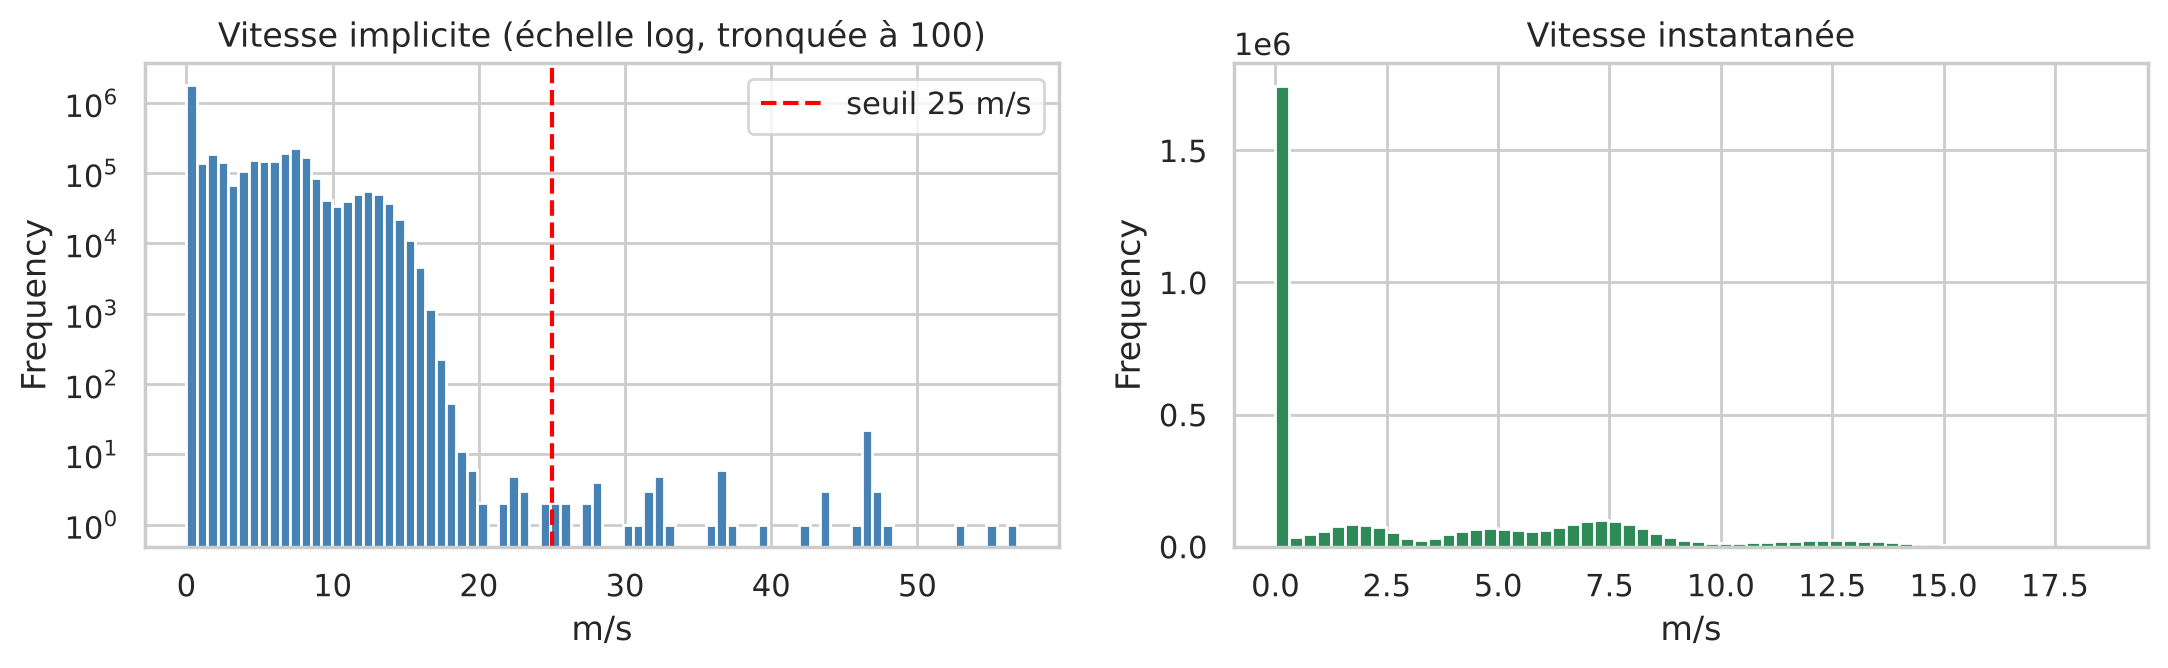

In [7]:
g = dt.groupby("id", observed=True)
dstep  = g["step"].diff()
v_impl = np.hypot(g["x"].diff(), g["y"].diff()) / dstep

n_trous = int((dstep > 1).sum())
n_tele  = int((v_impl > V_MAX_IMPL).sum())
print(f"Trous temporels dans une trajectoire (écart > 1 s) : {n_trous}")
print(f"Sauts de position impossibles (v. implicite > {V_MAX_IMPL:.0f} m/s)  : {n_tele}  ({100*n_tele/len(dt):.4f} % des lignes)")
print(f"Véhicules avec une seule observation              : {int((g.size() == 1).sum())}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
v_impl.dropna().clip(upper=100).plot.hist(bins=80, log=True, ax=ax[0], color="steelblue")
ax[0].axvline(V_MAX_IMPL, color="red", ls="--", label=f"seuil {V_MAX_IMPL:.0f} m/s"); ax[0].legend()
ax[0].set_title("Vitesse implicite (échelle log, tronquée à 100)"); ax[0].set_xlabel("m/s")
dt["speed"].plot.hist(bins=60, ax=ax[1], color="seagreen"); ax[1].set_title("Vitesse instantanée"); ax[1].set_xlabel("m/s")
plt.tight_layout(); plt.show()
del g, dstep, v_impl

## 3. Valeurs aberrantes

On applique les deux méthodes du cours (IQR et z-score) à la vitesse, puis on les **confronte à une règle physique**. Une valeur extrême statistiquement n'est pas forcément une erreur.

In [8]:
def bornes_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

lo, hi = bornes_iqr(dt.speed)
n_iqr = int(((dt.speed < lo) | (dt.speed > hi)).sum())

s64 = dt.speed.astype("float64")
z = (s64 - s64.mean()) / s64.std()
n_z = int((z.abs() > 3).sum())

print(f"IQR     : bornes [{lo:.1f}, {hi:.1f}] m/s -> {n_iqr:,} valeurs hors bornes ({100*n_iqr/len(dt):.2f} %)")
print(f"z-score : |z| > 3 (vitesse > {s64.mean()+3*s64.std():.1f} m/s) -> {n_z:,} valeurs ({100*n_z/len(dt):.2f} %)")
print(f"Vitesse maximale = {dt.speed.max():.1f} m/s = {dt.speed.max()*3.6:.0f} km/h : plausible pour une voie urbaine rapide")
del z, s64

IQR     : bornes [-9.9, 16.5] m/s -> 980 valeurs hors bornes (0.02 %)
z-score : |z| > 3 (vitesse > 15.5 m/s) -> 7,253 valeurs (0.18 %)
Vitesse maximale = 18.7 m/s = 67 km/h : plausible pour une voie urbaine rapide


**Lecture.** Les méthodes statistiques signalent une petite part de vitesses élevées (au-delà d'environ 16 m/s, soit 58 km/h). Ce sont des **véhicules qui roulent librement sur une voie rapide**, pas des erreurs : la vitesse maximale (67 km/h) reste réaliste. Les supprimer fausserait précisément ce qu'on veut prédire (le trafic fluide). **Décision : on conserve ces valeurs.**

En revanche, les **sauts de position impossibles** (section 2.3) sont de vraies anomalies : on supprime ces lignes dans `nettoyer()`.

L'accélération (variation de vitesse d'une seconde à l'autre) est examinée à la section 5, après le nettoyage.

## 4. Analyse exploratoire (EDA)

### 4.1 Statistiques descriptives

In [9]:
print(dt[["step", "x", "y", "speed", "angle"]].describe().T.to_string())
print()
print(dt[["id", "lane_id", "type"]].describe().T.to_string())

           count          mean          std       min          25%           50%           75%           max
step   3921776.0  11974.624485  6676.449165  0.000000  6164.000000  12091.000000  17723.000000  23583.000000
x      3921776.0    872.984192   356.668976 -1.338734   696.159927    867.800110   1100.102539   1694.544434
y      3921776.0    435.878571   210.477737  0.183826   255.528687    408.583389    607.993469    944.136841
speed  3921776.0      3.405776     4.037585  0.000000     0.000000      1.536675      6.605764     18.658438
angle  3921776.0    174.451965    91.708954  0.000388   135.442337    143.795944    230.683411    359.985687

           count unique            top     freq
id       3921776   9863        veh1781     2953
lane_id  3921776   2482  836361915#1_0   121570
type     3921776      1  veh_passenger  3921776


### 4.2 Distribution de la vitesse : variable à forte masse en zéro

Part des observations à l'arrêt (vitesse < 0,1 m/s) : 43.2 %
Asymétrie (skew) de la vitesse : 0.96
Médiane = 1.54 m/s, moyenne = 3.41 m/s


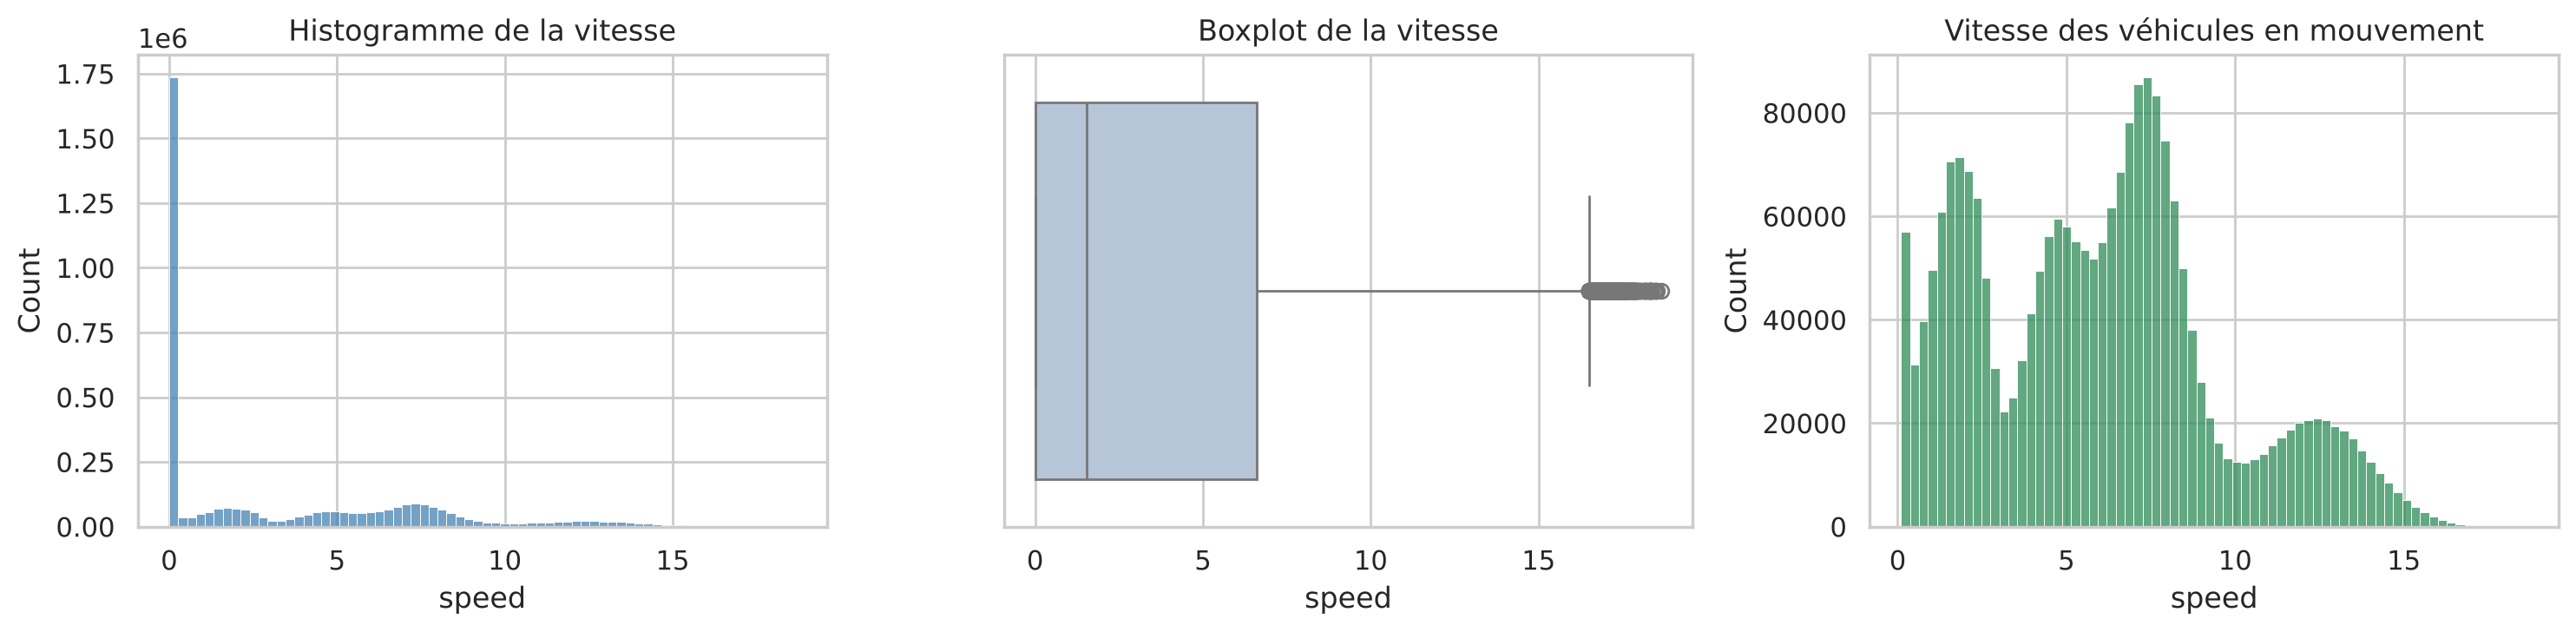

In [10]:
p_zero = (dt.speed < 0.1).mean()
print(f"Part des observations à l'arrêt (vitesse < 0,1 m/s) : {100*p_zero:.1f} %")
print(f"Asymétrie (skew) de la vitesse : {dt.speed.skew():.2f}")
print(f"Médiane = {dt.speed.median():.2f} m/s, moyenne = {dt.speed.mean():.2f} m/s")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(dt.speed, bins=70, ax=ax[0], color="steelblue"); ax[0].set_title("Histogramme de la vitesse")
sns.boxplot(x=dt.speed, ax=ax[1], color="lightsteelblue"); ax[1].set_title("Boxplot de la vitesse")
sns.histplot(dt.loc[dt.speed >= 0.1, "speed"], bins=70, ax=ax[2], color="seagreen"); ax[2].set_title("Vitesse des véhicules en mouvement")
plt.tight_layout(); plt.show()

**Observation.** Plus de 4 observations sur 10 (43 %) correspondent à un véhicule **à l'arrêt** (feux, files d'attente) : un pic énorme à 0. Pour les véhicules en mouvement, on voit **trois régimes** de vitesse : autour de 2 m/s (circulation très lente), de 7 m/s et de 12 m/s (voies rapides), ce qui reflète des types de routes différents. Une moyenne seule cache cette structure, c'est pourquoi on construira aussi la part de véhicules arrêtés (`p_stopped`) comme variable, et un état de trafic discret en cible.

### 4.3 Dynamique temporelle

      vitesse_moy  n_lignes  p_arret  vehicules_actifs_moy
step                                                      
0            3.58    535748     0.41                148.82
1            3.41    616089     0.43                171.14
2            3.47    589497     0.42                163.75
3            3.23    639442     0.45                177.62
4            3.40    606908     0.43                168.59
5            3.29    618679     0.45                171.86
6            3.60    315413     0.41                158.98


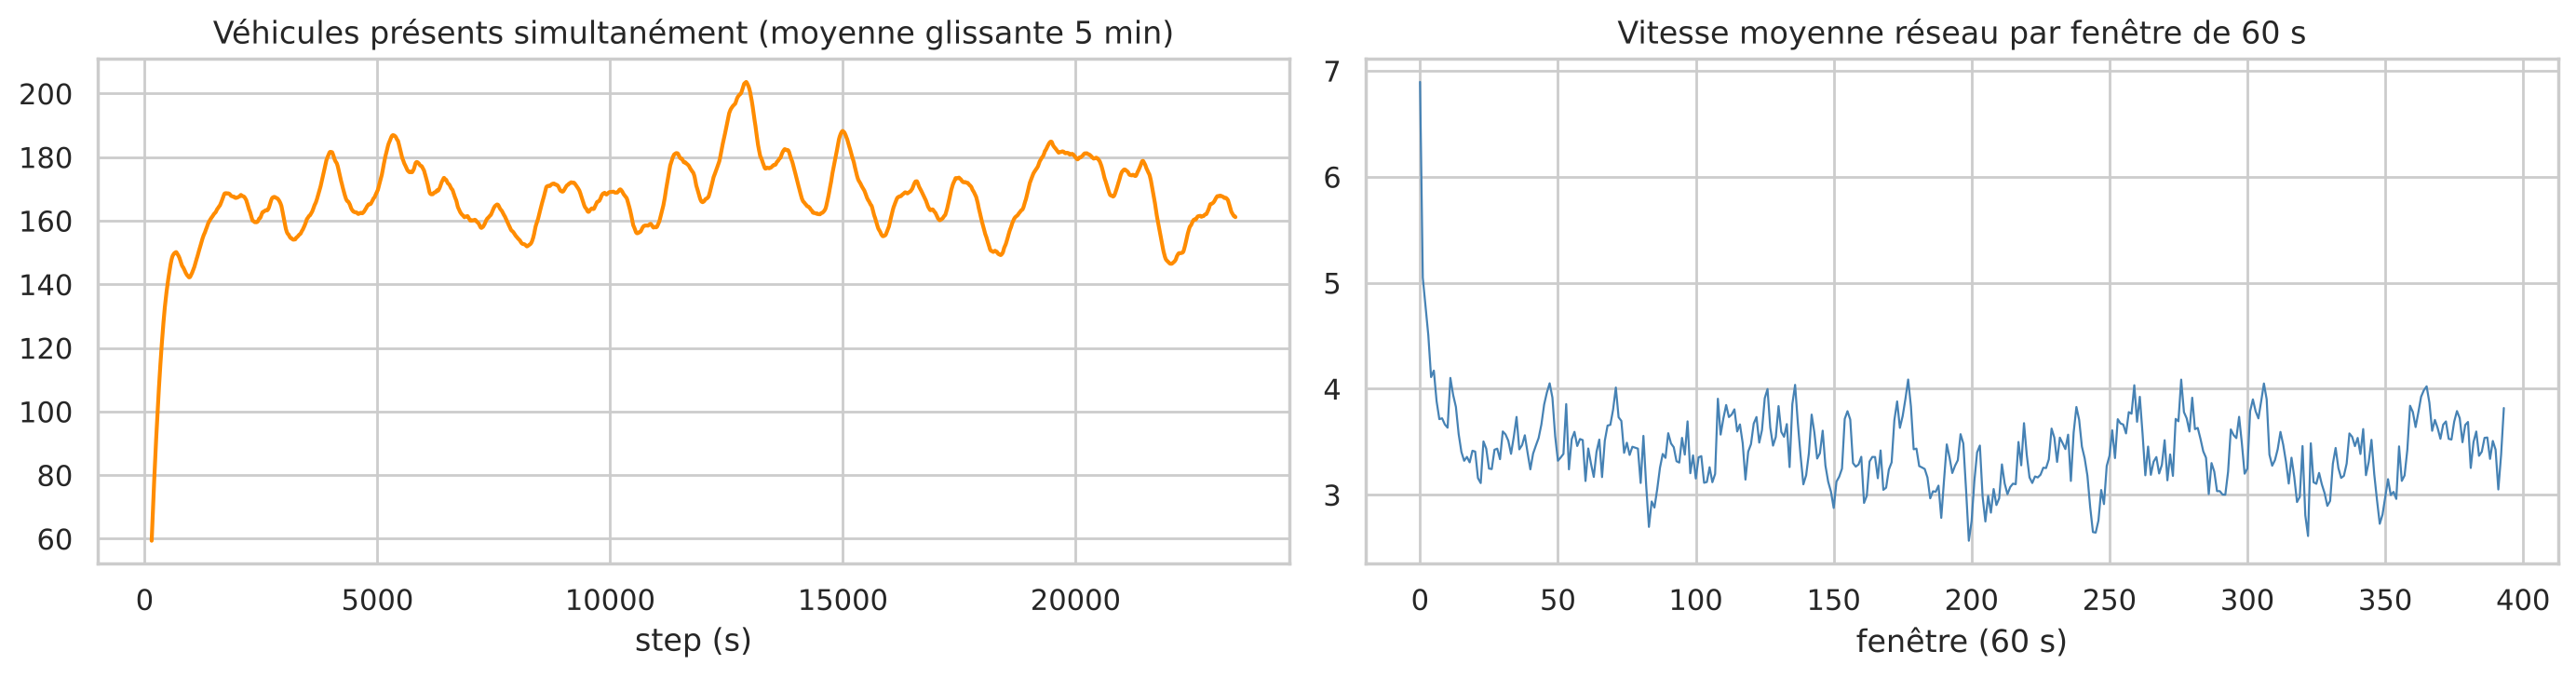

In [11]:
n_actifs = dt.groupby("step").size()
par_heure = dt.groupby(dt.step // 3600).agg(vitesse_moy=("speed", "mean"), n_lignes=("speed", "size"),
                                            p_arret=("speed", lambda s: (s < 0.1).mean()))
par_heure["vehicules_actifs_moy"] = n_actifs.groupby(n_actifs.index // 3600).mean()
print(par_heure.round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
n_actifs.rolling(300, center=True).mean().plot(ax=ax[0], color="darkorange")
ax[0].set_title("Véhicules présents simultanément (moyenne glissante 5 min)"); ax[0].set_xlabel("step (s)")
vit_t = dt.groupby(dt.step // WINDOW)["speed"].mean()
vit_t.plot(ax=ax[1], color="steelblue", lw=0.8)
ax[1].set_title(f"Vitesse moyenne réseau par fenêtre de {WINDOW} s"); ax[1].set_xlabel(f"fenêtre ({WINDOW} s)")
plt.tight_layout(); plt.show()

**Observation.** Le réseau part **vide** : pendant les 10 premières minutes environ, le nombre de véhicules monte de 60 à 165 et la vitesse moyenne est artificiellement élevée (route libre). Cette **phase de montée en charge** n'est pas représentative : on l'exclura de la modélisation (`WARMUP_S`, section 7). Ensuite, le nombre de véhicules oscille autour de 150 à 200 : le trafic est **globalement stationnaire** (pas de pointe nette) tandis que les véhicules entrent et sortent en permanence. La variation d'une minute à l'autre vient donc surtout de la **géographie** (où sont les véhicules) et des **cycles locaux** (feux, files), plus que d'une tendance globale. Cela justifie une variable de contexte « réseau entier » et des variables **spatiales**.

### 4.4 Véhicules et voies

Durée de présence d'un véhicule (secondes) :
count    9863.0
mean      397.6
std       281.5
min         1.0
25%       209.0
50%       324.0
75%       498.0
max      2953.0

Les 20 voies les plus fréquentées concentrent 24.0 % des observations (sur 2,482 voies)


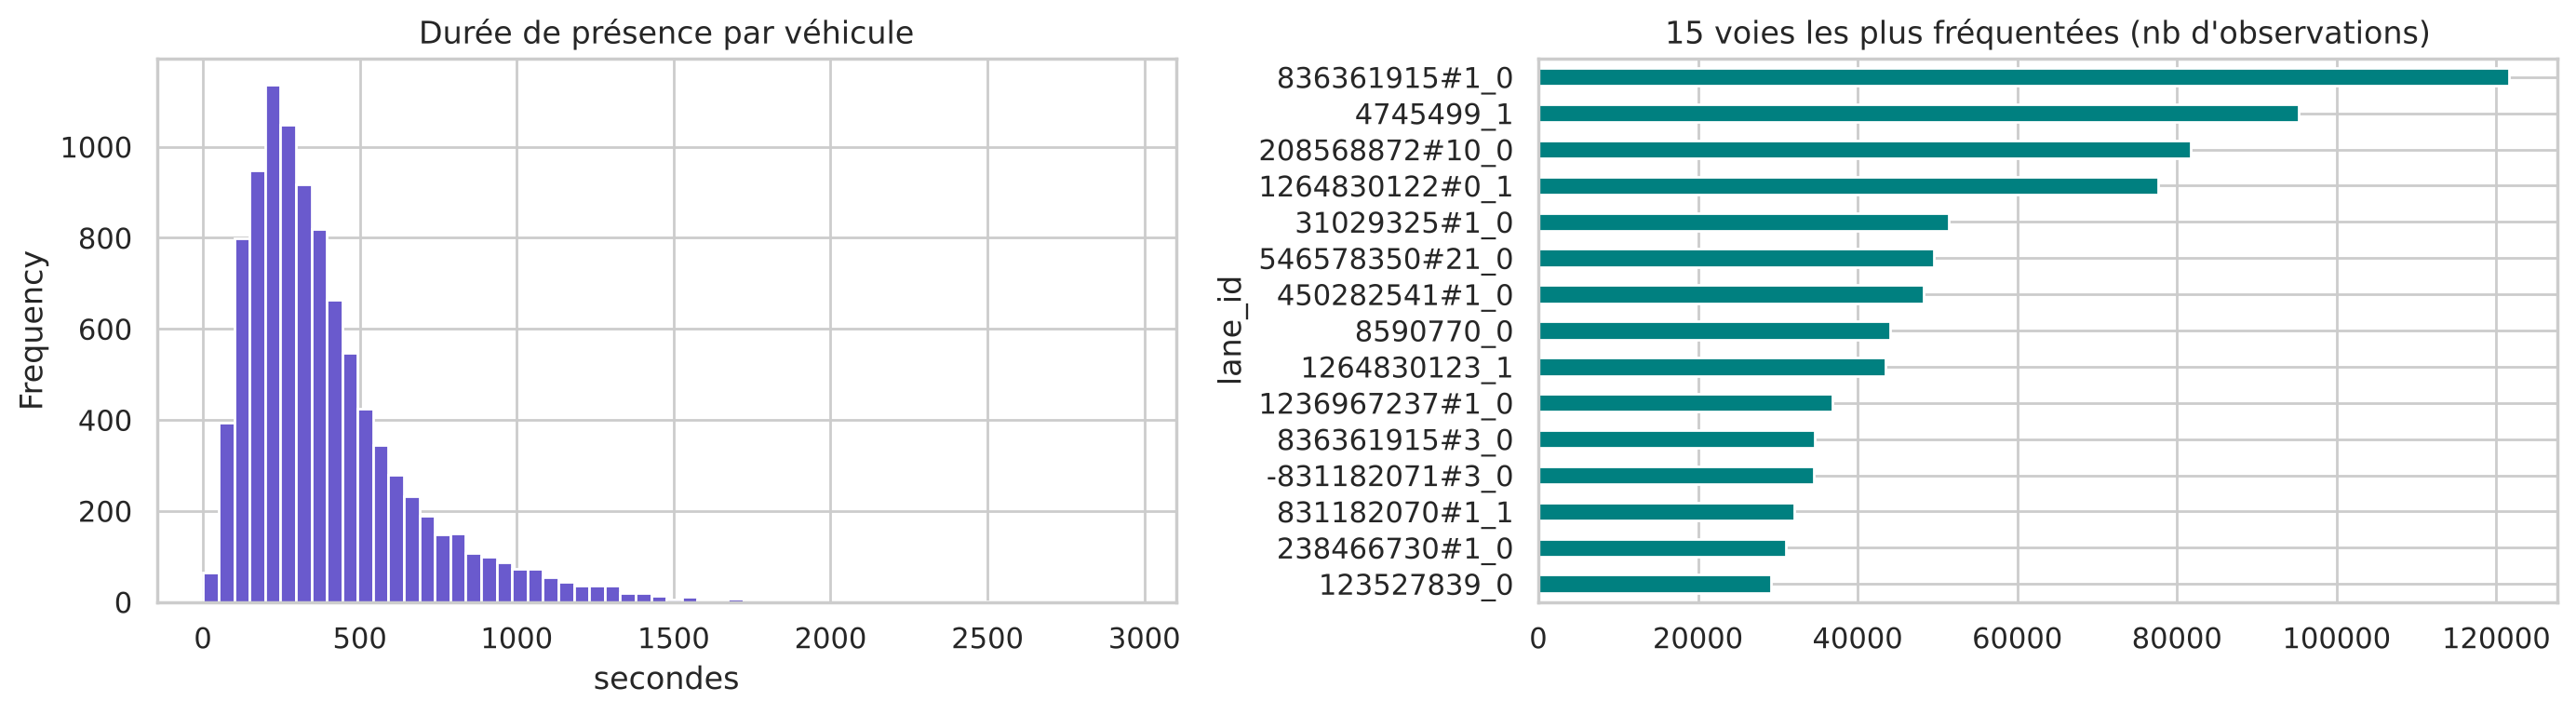

In [12]:
longueur = dt.groupby("id", observed=True).size()
print("Durée de présence d'un véhicule (secondes) :"); print(longueur.describe().round(1).to_string())

top_voies = dt.lane_id.value_counts().head(15)
part_top20 = dt.lane_id.value_counts().head(20).sum() / len(dt)
print(f"\nLes 20 voies les plus fréquentées concentrent {100*part_top20:.1f} % des observations (sur {dt.lane_id.nunique():,} voies)")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
longueur.plot.hist(bins=60, ax=ax[0], color="slateblue"); ax[0].set_title("Durée de présence par véhicule"); ax[0].set_xlabel("secondes")
top_voies.sort_values().plot.barh(ax=ax[1], color="teal"); ax[1].set_title("15 voies les plus fréquentées (nb d'observations)")
plt.tight_layout(); plt.show()

**Observation.** Les durées de présence sont très inégales (quelques secondes à près d'une heure) : un véhicule qui reste longtemps bloqué pèse beaucoup dans les statistiques. Les 20 voies les plus fréquentées (sur 2 482) concentrent à elles seules 24 % des observations : ce sont des axes très chargés ou des zones d'attente (probablement des goulots d'étranglement).

### 4.5 Structure spatiale : où roulent les véhicules, et à quelle vitesse ?

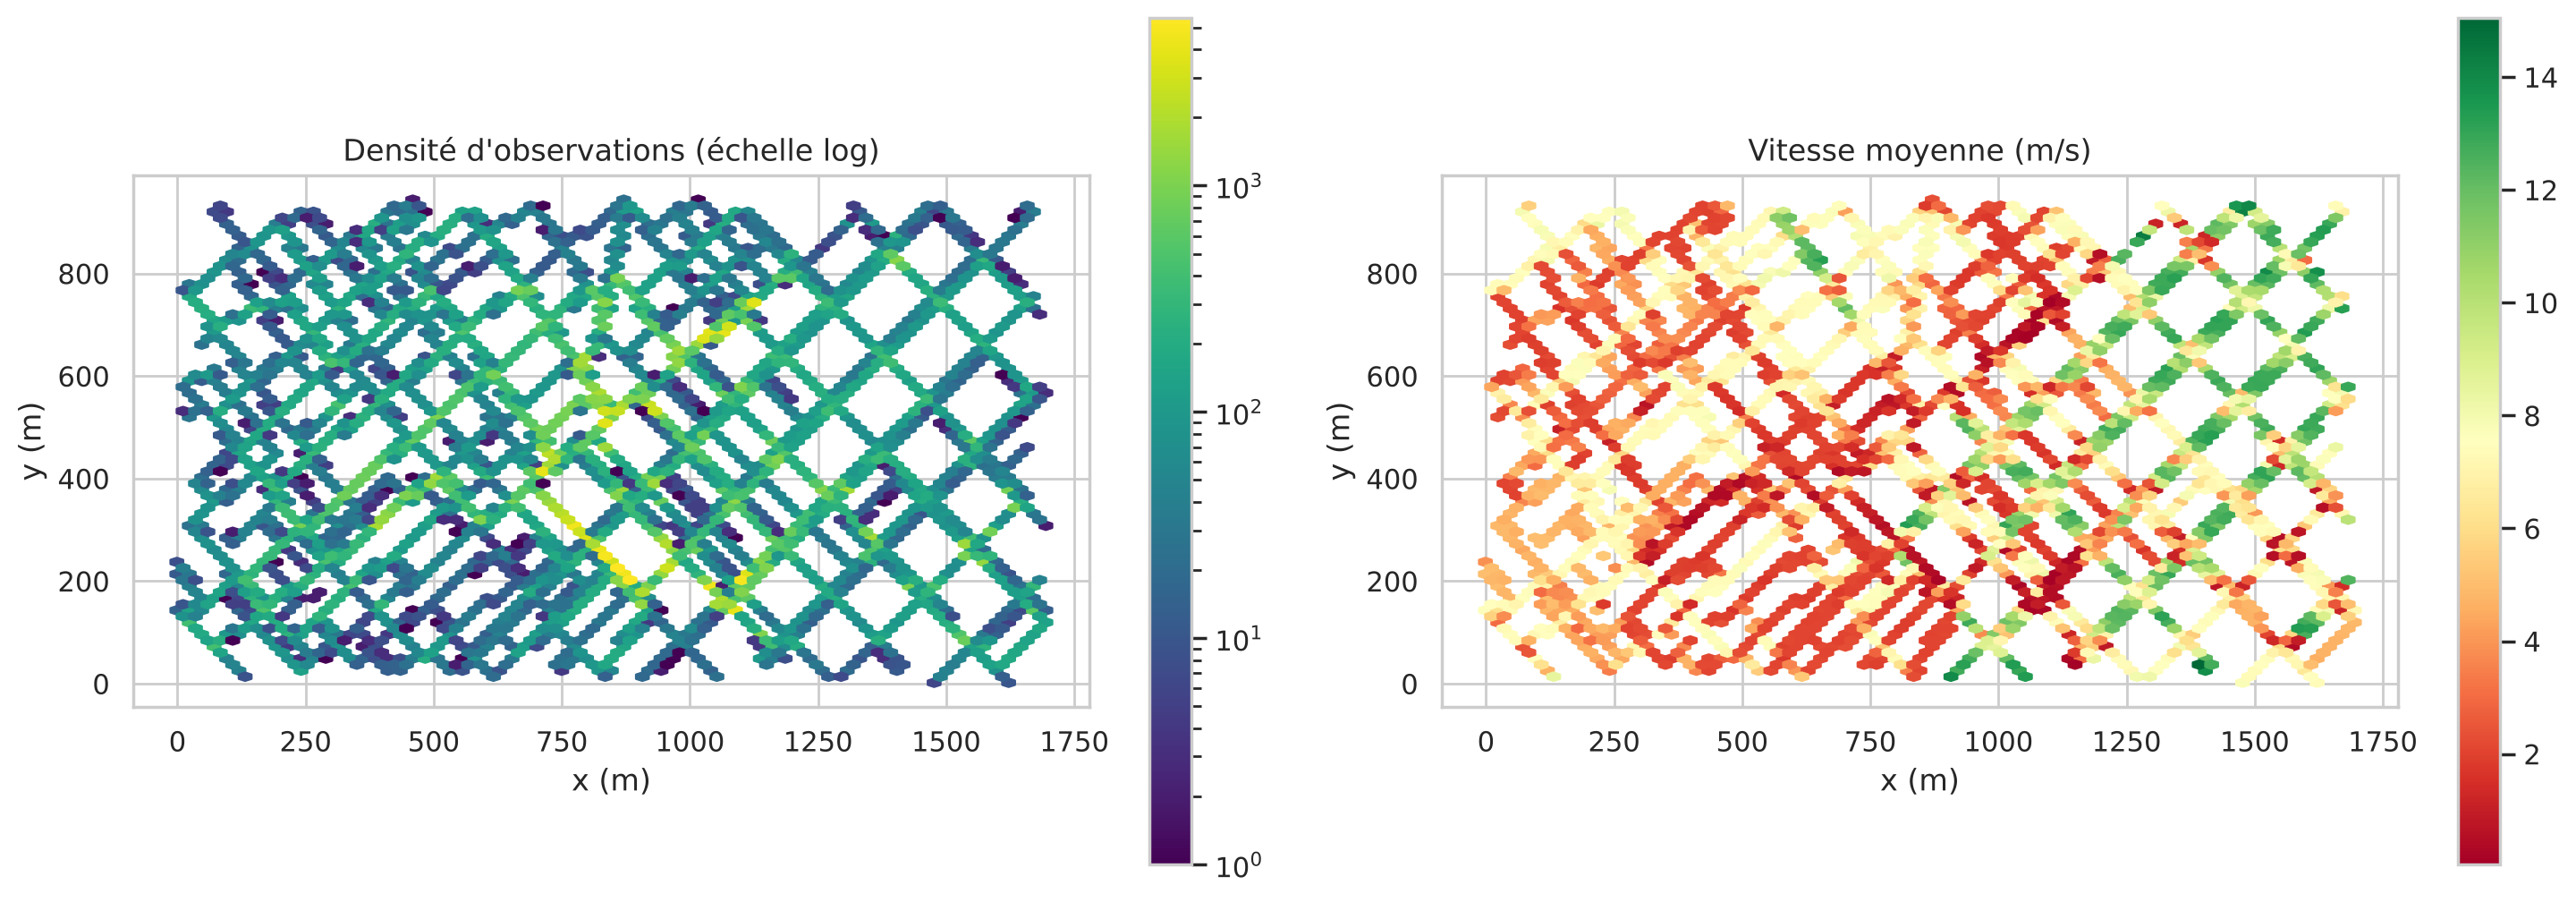

In [13]:
ech = dt.sample(500_000, random_state=SEED)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
h1 = ax[0].hexbin(ech.x, ech.y, gridsize=70, bins="log", cmap="viridis")
ax[0].set_title("Densité d'observations (échelle log)"); plt.colorbar(h1, ax=ax[0])
h2 = ax[1].hexbin(ech.x, ech.y, C=ech.speed, reduce_C_function=np.mean, gridsize=70, cmap="RdYlGn", mincnt=5)
ax[1].set_title("Vitesse moyenne (m/s)"); plt.colorbar(h2, ax=ax[1])
for a in ax: a.set_xlabel("x (m)"); a.set_ylabel("y (m)"); a.set_aspect("equal")
plt.tight_layout(); plt.show()

**Observation.** Le réseau est un **damier incliné à 45°** (deux familles de routes orthogonales). Quelques axes du centre (x entre 700 et 1 100 m) concentrent le plus d'observations. La vitesse varie fortement d'une zone à l'autre : la partie **est** (x > 1 200 m) est rapide (10 à 14 m/s en moyenne), alors que le **centre et l'ouest** sont lents, avec des poches à vitesse moyenne proche de 0 (files d'attente). La position est donc une information essentielle : elle sera conservée sous forme de **cellules de grille** (section 6) et de coordonnées de cellule.

### 4.6 Direction (`angle`) et type de voie

Observations dans une intersection (voie ':...') : 14.4 %
              mean  median    count
intersection                       
False         3.12    0.49  3356343
True          5.13    5.09   565433


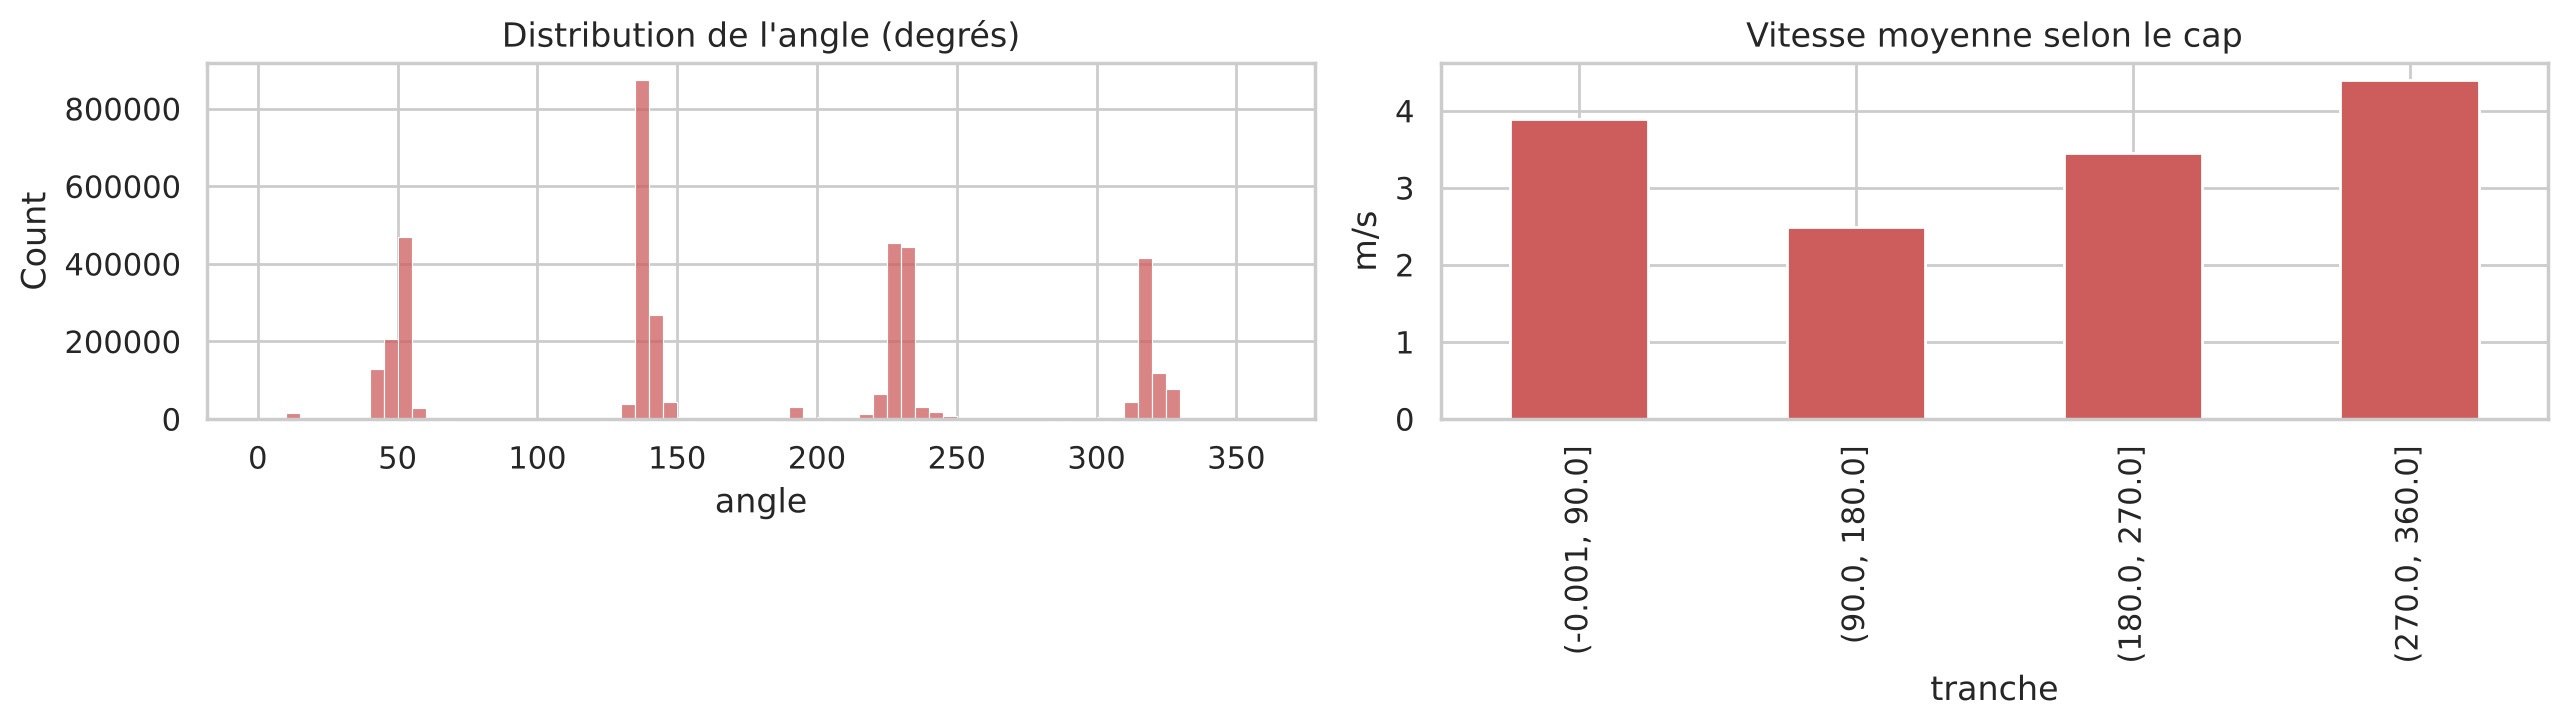

In [14]:
lane_str = pd.Series(dt.lane_id.cat.categories.astype(str))
interne  = lane_str.str.startswith(":").values
dt_int   = interne[dt.lane_id.cat.codes.values]
print(f"Observations dans une intersection (voie ':...') : {100*dt_int.mean():.1f} %")
print(dt.assign(intersection=dt_int).groupby("intersection")["speed"].agg(["mean", "median", "count"]).round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
sns.histplot(dt.angle, bins=72, ax=ax[0], color="indianred"); ax[0].set_title("Distribution de l'angle (degrés)")
dt.assign(tranche=pd.cut(dt.angle, [0, 90, 180, 270, 360], include_lowest=True)).groupby("tranche", observed=True)["speed"].mean().plot.bar(ax=ax[1], color="indianred")
ax[1].set_title("Vitesse moyenne selon le cap"); ax[1].set_ylabel("m/s")
plt.tight_layout(); plt.show()
del dt_int

**Observation.** Les caps se regroupent en **quatre directions** (environ 50°, 140°, 230° et 320°) : ce sont les quatre sens de circulation du damier. La vitesse moyenne dépend du sens (2,5 m/s pour les caps 90-180°, 4,4 m/s pour 270-360°), ce qui reflète la géographie du réseau. L'angle est de plus une grandeur **circulaire** : 359° et 1° sont presque identiques. Le donner tel quel à un modèle serait trompeur, on le remplacera par `sin(angle)` et `cos(angle)`. Contrairement à ce qu'on pourrait croire, les véhicules **à l'intérieur** des intersections roulent plus vite (5,1 m/s en moyenne) que sur les autres voies (3,1 m/s ; médiane 0,5 m/s) : les files d'attente se forment **en amont**, sur les voies d'approche, pas dans l'intersection elle-même. La part de véhicules en intersection (`p_internal`) est conservée comme variable ; son utilité sera mesurée par les modèles.

### 4.7 Corrélations et significativité

Avec presque 4 millions de lignes, **toute** corrélation, même minuscule, est « statistiquement significative » (p-value proche de 0). Il faut donc regarder la **taille** de la corrélation, pas seulement la p-value. On teste sur un échantillon de 100 000 lignes.

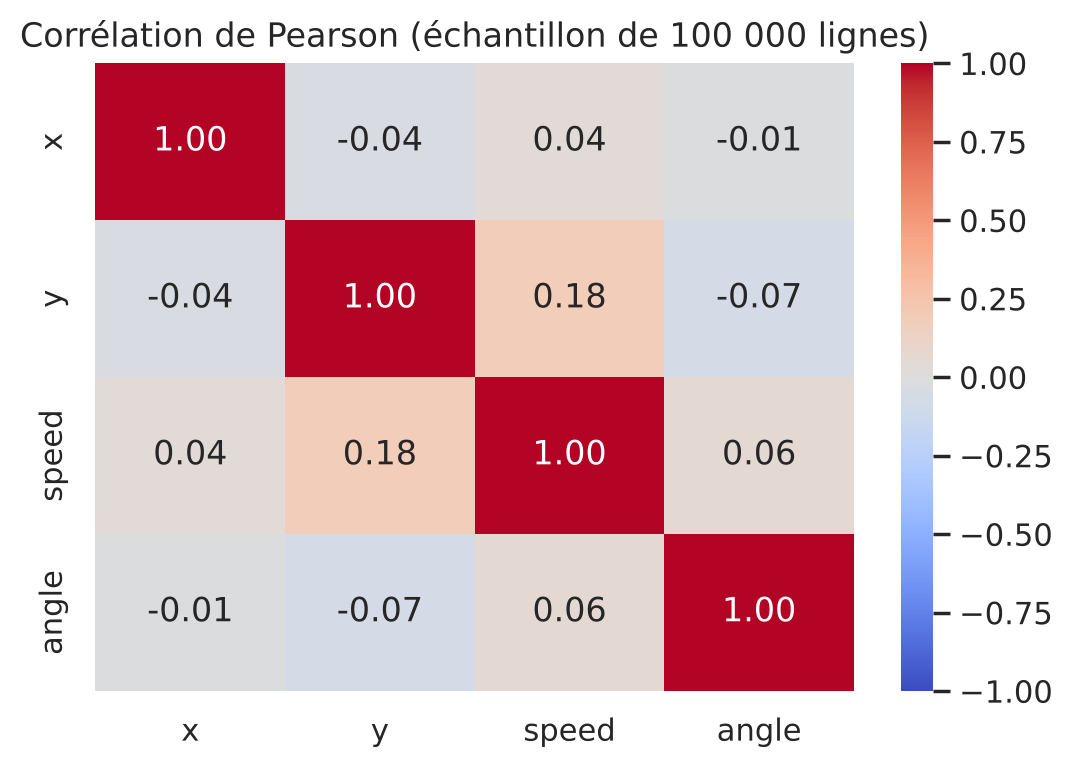

p-values associées :
             x        y    speed    angle
x      0.0e+00  9.9e-31  1.1e-31  4.4e-05
y      9.9e-31  0.0e+00  0.0e+00  0.0e+00
speed  1.1e-31  0.0e+00  0.0e+00  0.0e+00
angle  4.4e-05  0.0e+00  0.0e+00  0.0e+00
Spearman (speed vs autres) : {'x': -0.065, 'y': 0.201, 'angle': 0.055}


In [15]:
ech2 = dt.sample(100_000, random_state=SEED)
cols = ["x", "y", "speed", "angle"]
corr = ech2[cols].corr()
pv = pd.DataFrame({a: {b: stats.pearsonr(ech2[a], ech2[b])[1] for b in cols} for a in cols})

fig, ax = plt.subplots(figsize=(5.5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax); ax.set_title("Corrélation de Pearson (échantillon de 100 000 lignes)")
plt.tight_layout(); plt.show()
print("p-values associées :"); print(pv.map(lambda p: f"{p:.1e}").to_string())

# Corrélation de rang (Spearman) : robuste aux relations non linéaires et aux valeurs extrêmes
print("Spearman (speed vs autres) :", {c: round(float(stats.spearmanr(ech2.speed, ech2[c])[0]), 3) for c in ["x", "y", "angle"]})

**Observation.** Les corrélations entre `speed` et les coordonnées ou l'angle sont **faibles** (|ρ| de Spearman ≤ 0,2) : la vitesse ne se lit pas directement dans la position brute. La relation est **non linéaire et locale** (telle zone est lente, telle autre rapide), ce qu'une corrélation linéaire globale ne capture pas. C'est une raison de plus pour préférer des modèles non linéaires (arbres, ANN) et des variables d'agrégation locales.

### 4.8 Synthèse des problèmes détectés

- Pas de valeur manquante ni de doublon dans le fichier brut ; `type` est constante.
- Quelques sauts de position impossibles (téléportations) : à supprimer.
- Vitesse à forte masse en zéro (véhicules à l'arrêt) : à représenter par `p_stopped`.
- `angle` circulaire : à encoder avec sin/cos.
- Trafic très concentré sur quelques voies et zones : la dimension spatiale est essentielle.
- Les identifiants (`id`) ne doivent pas être utilisés comme variables explicatives.

## 5. Nettoyage : la fonction `nettoyer(df)`

Les opérations sont appliquées **dans un ordre précis** (comme dans le TP d'exploration) :

1. tri par véhicule et par temps ;
2. suppression des sauts de position impossibles ;
3. suppression des colonnes constantes (`type`) ;
4. variables dérivées au niveau du véhicule : voie (route, numéro de voie, intersection ou non), accélération, arrêt, freinage brusque, `sin`/`cos` de l'angle.

Cette fonction n'utilise **aucune statistique du jeu entier** (seulement des différences entre deux lignes d'un même véhicule) : elle peut être appliquée avant le découpage sans fuite.

In [16]:
def nettoyer(df, v_max_impl=V_MAX_IMPL, hard_brake=HARD_BRAKE):
    # 1. tri
    df = df.sort_values(["id", "step"], ignore_index=True)

    # 2. sauts de position impossibles (artefacts de simulation)
    g = df.groupby("id", observed=True)
    v_impl = np.hypot(g["x"].diff(), g["y"].diff()) / g["step"].diff()
    n_avant = len(df)
    df = df.loc[~(v_impl > v_max_impl)].reset_index(drop=True)
    n_sup = n_avant - len(df)

    # 3. colonnes constantes
    constantes = [c for c in df.columns if df[c].nunique() == 1]
    df = df.drop(columns=constantes)

    # 4a. voie : route, numéro de voie, intersection (calculé sur les catégories, puis propagé)
    cats = pd.Series(df["lane_id"].cat.categories.astype(str))
    parts = cats.str.rsplit("_", n=1)
    route_of  = parts.str[0].values
    idx_of    = pd.to_numeric(parts.str[1], errors="coerce").fillna(0).astype("int8").values
    inter_of  = cats.str.startswith(":").values
    codes = df["lane_id"].cat.codes.values
    df["edge"]        = pd.Categorical(route_of[codes])
    df["lane_idx"]    = idx_of[codes]
    df["is_internal"] = inter_of[codes].astype("float32")

    # 4b. dynamique : accélération (m/s², pas de 1 s), arrêt, freinage brusque
    g = df.groupby("id", observed=True)
    acc = g["speed"].diff().where(g["step"].diff() == 1)
    df["acc"]        = acc.astype("float32")
    df["acc_abs"]    = df["acc"].abs()
    df["hard_brake"] = (df["acc"] < hard_brake).astype("float32")
    df["stopped"]    = (df["speed"] < 0.1).astype("float32")

    # 4c. angle circulaire -> sin / cos
    rad = np.deg2rad(df["angle"].astype("float32"))
    df["sin_a"] = np.sin(rad).astype("float32")
    df["cos_a"] = np.cos(rad).astype("float32")

    print(f"nettoyer : {n_sup} lignes supprimées (sauts impossibles), colonnes constantes retirées : {constantes}")
    return df

dt_clean = nettoyer(dt)
n_brut, n_propre = len(dt), len(dt_clean)
del dt
print(f"{n_brut:,} -> {n_propre:,} lignes")
dt_clean.head()

nettoyer : 63 lignes supprimées (sauts impossibles), colonnes constantes retirées : ['type']
3,921,776 -> 3,921,713 lignes


,step,id,x,y,speed,angle,lane_id,edge,lane_idx,is_internal,acc,acc_abs,hard_brake,stopped,sin_a,cos_a
0,0,veh0,470.490936,722.513794,0.000000,323.006775,288595616_0,288595616,0,0.0,NaN,NaN,0.0,1.0,-0.601721,0.798707
1,1,veh0,469.352539,724.024841,1.891703,323.006775,288595616_0,288595616,0,0.0,1.891703,1.891703,0.0,0.0,-0.601721,0.798707
2,2,veh0,467.735626,726.171082,2.686898,323.006775,288595616_0,288595616,0,0.0,0.795195,0.795195,0.0,0.0,-0.601721,0.798707
3,3,veh0,466.729248,727.506958,1.672368,323.006775,288595616_0,288595616,0,0.0,-1.014530,1.014530,0.0,0.0,-0.601721,0.798707
4,4,veh0,465.683472,728.895081,1.737784,323.006775,288595616_0,288595616,0,0.0,0.065416,0.065416,0.0,0.0,-0.601721,0.798707


In [17]:
# Contrôle de l'accélération après nettoyage : les valeurs extrêmes ont-elles disparu ?
print(dt_clean["acc"].describe().round(2).to_string())
print(f"\nFreinages brusques (< {HARD_BRAKE} m/s²) : {100*dt_clean.hard_brake.mean():.2f} % des observations")
print(f"Accélération max = {dt_clean.acc.max():.1f} m/s², décélération max = {dt_clean.acc.min():.1f} m/s²")
n_extr = int((dt_clean.acc.abs() > 9.5).sum())
print(f"|accélération| > 9,5 m/s² : {n_extr} observations sur {len(dt_clean):,} ({100*n_extr/len(dt_clean):.5f} %) -> conservées, trop rares pour peser ; "
      f"la décélération d'urgence est bornée à -9 m/s² par le simulateur")

count    3911746.00
mean           0.02
std            1.08
min           -9.00
25%           -0.09
50%            0.00
75%            0.23
max           13.89

Freinages brusques (< -3.0 m/s²) : 3.07 % des observations
Accélération max = 13.9 m/s², décélération max = -9.0 m/s²
|accélération| > 9,5 m/s² : 4 observations sur 3,921,713 (0.00010 %) -> conservées, trop rares pour peser ; la décélération d'urgence est bornée à -9 m/s² par le simulateur


## 6. Feature Engineering : des trajectoires aux observations « cellule × fenêtre »

**Principe.** Pour chaque cellule de 100 m et chaque fenêtre de 60 s, on résume les véhicules présents :

| Famille | Variables |
|---|---|
| Flux / densité | `n_veh` (véhicules distincts), `n_obs` (véhicule-secondes) |
| Vitesse | moyenne, écart-type, min, max, `p_stopped` (part à l'arrêt) |
| Dynamique | `acc_abs_mean`, `p_hard_brake` |
| Direction | `sin_mean`, `cos_mean` (moyennes de sin/cos du cap) |
| Contexte routier | `p_internal` (part en intersection), `lane_idx_max`, `n_lanes`, `n_edges` |
| Position | `cell_x`, `cell_y` (centre de la cellule) |
| **Historique** (passé uniquement) | valeurs aux fenêtres `t-1, t-2, t-3` et moyennes glissantes sur 3 fenêtres |
| **Voisinage** | vitesse et nombre de véhicules des 8 cellules voisines |
| **Réseau** | vitesse moyenne et nombre de véhicules sur tout le réseau à la même fenêtre |

Toutes ces variables à la fenêtre `t` n'utilisent que des informations disponibles à la fin de la fenêtre `t`. Les cibles sont celles de la fenêtre `t+1`.

In [18]:
def agreger(df, cell=CELL, win=WINDOW):
    """Résume les trajectoires par (fenêtre, cellule). Retourne un tableau complet fenêtres x grille."""
    x0, y0 = float(df.x.min()), float(df.y.min())
    d = pd.DataFrame({
        "w":  (df.step // win).astype("int32"),
        "cx": ((df.x - x0) // cell).astype("int16"),
        "cy": ((df.y - y0) // cell).astype("int16"),
        "id": df.id, "lane_id": df.lane_id, "edge": df.edge, "speed": df.speed,
        "stopped": df.stopped, "acc_abs": df.acc_abs, "hard_brake": df.hard_brake,
        "sin_a": df.sin_a, "cos_a": df.cos_a, "is_internal": df.is_internal, "lane_idx": df.lane_idx})
    agg = d.groupby(["w", "cy", "cx"], observed=True).agg(
        n_obs=("id", "size"), n_veh=("id", "nunique"),
        speed_mean=("speed", "mean"), speed_std=("speed", "std"),
        speed_min=("speed", "min"), speed_max=("speed", "max"),
        p_stopped=("stopped", "mean"), acc_abs_mean=("acc_abs", "mean"), p_hard_brake=("hard_brake", "mean"),
        sin_mean=("sin_a", "mean"), cos_mean=("cos_a", "mean"),
        p_internal=("is_internal", "mean"), lane_idx_max=("lane_idx", "max"),
        n_lanes=("lane_id", "nunique"), n_edges=("edge", "nunique"))
    W, NY, NX = int(d.w.max()) + 1, int(d.cy.max()) + 1, int(d.cx.max()) + 1
    idx = pd.MultiIndex.from_product([range(W), range(NY), range(NX)], names=["w", "cy", "cx"])
    full = agg.reindex(idx)
    compteurs = ["n_obs", "n_veh", "n_lanes", "n_edges"]
    full[compteurs] = full[compteurs].fillna(0)          # aucune observation = 0 véhicule (et non une valeur inconnue)
    full = full.reset_index()
    full["cell_id"] = full.cy * NX + full.cx
    full["cell_x"]  = x0 + (full.cx + 0.5) * cell
    full["cell_y"]  = y0 + (full.cy + 0.5) * cell
    return full, (W, NY, NX)

grille, (W, NY, NX) = agreger(dt_clean)
print(f"Grille : {NX} x {NY} cellules de {CELL} m, {W} fenêtres de {WINDOW} s -> {len(grille):,} lignes (cellule x fenêtre)")
print(f"Cellules x fenêtres jamais occupées : {100*(grille.n_obs == 0).mean():.1f} %")
print(f"Nombre de véhicules par cellule occupée : médiane {grille.loc[grille.n_veh > 0, 'n_veh'].median():.0f}, "
      f"moyenne {grille.loc[grille.n_veh > 0, 'n_veh'].mean():.1f}, max {grille.n_veh.max():.0f}")
grille.head()

Grille : 17 x 10 cellules de 100 m, 394 fenêtres de 60 s -> 66,980 lignes (cellule x fenêtre)
Cellules x fenêtres jamais occupées : 18.4 %
Nombre de véhicules par cellule occupée : médiane 4, moyenne 4.5, max 33


,w,cy,cx,n_obs,n_veh,speed_mean,speed_std,speed_min,speed_max,p_stopped,acc_abs_mean,p_hard_brake,sin_mean,cos_mean,p_internal,lane_idx_max,n_lanes,n_edges,cell_id,cell_x,cell_y
0,0,0,0,20.0,1.0,3.845545,2.876868,0.000214,6.877575,0.25,0.867743,0.0,-0.661007,0.750365,0.100000,1.0,3.0,3.0,0,48.661266,50.183826
1,0,0,1,6.0,1.0,6.395185,0.453971,5.663432,6.922230,0.00,0.500955,0.0,-0.654283,0.756104,0.333333,1.0,3.0,3.0,1,148.661266,50.183826
2,0,0,2,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,2,248.661266,50.183826
3,0,0,3,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,3,348.661266,50.183826
4,0,0,4,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,4,448.661266,50.183826


**Valeurs manquantes structurelles.** Lorsqu'une cellule est vide pendant une fenêtre, `n_veh = n_obs = 0` (c'est une vraie information : *zéro véhicule*), mais la **vitesse moyenne n'existe pas** (`NaN`). Ces `NaN` ne sont ni au hasard ni des erreurs : ils signifient « rien à mesurer ». On ne les imputera donc pas avec la moyenne de tout le jeu ; l'imputation (section 8) utilisera une statistique du **train** et l'indicateur `n_obs = 0` reste disponible pour le modèle.

In [19]:
pct_nan = grille.isna().mean().mul(100).round(1)
print(pct_nan[pct_nan > 0].sort_values(ascending=False).to_string())

speed_std       19.9
acc_abs_mean    18.5
speed_mean      18.4
speed_min       18.4
speed_max       18.4
p_stopped       18.4
p_hard_brake    18.4
sin_mean        18.4
cos_mean        18.4
p_internal      18.4
lane_idx_max    18.4


In [20]:
# ---------- Variables de réseau, de voisinage et d'historique ----------
grille = grille.sort_values(["w", "cy", "cx"], ignore_index=True)

# Réseau entier à la même fenêtre
grille["speed_sum"] = grille.speed_mean.fillna(0) * grille.n_obs
net = grille.groupby("w").agg(net_n_veh=("n_veh", "sum"), net_obs=("n_obs", "sum"), net_speed_sum=("speed_sum", "sum"))
net["net_speed"] = net.net_speed_sum / net.net_obs
grille = grille.merge(net[["net_n_veh", "net_speed"]], left_on="w", right_index=True, how="left")

# Voisinage : somme sur les 8 cellules voisines (même fenêtre)
def somme_voisins(col):
    a = grille[col].to_numpy(dtype="float64").reshape(W, NY, NX)
    p = np.pad(a, ((0, 0), (1, 1), (1, 1)))
    s = sum(p[:, 1 + dy:1 + dy + NY, 1 + dx:1 + dx + NX] for dy in (-1, 0, 1) for dx in (-1, 0, 1) if (dy, dx) != (0, 0))
    return s.reshape(-1)

grille["nb_n_obs"] = somme_voisins("n_obs")
grille["nb_n_veh"] = somme_voisins("n_veh")
grille["nb_speed"] = np.where(grille.nb_n_obs > 0, somme_voisins("speed_sum") / grille.nb_n_obs.replace(0, np.nan), np.nan)

# Historique : décalages du passé UNIQUEMENT (shift positif) ; la cellule est le groupe
cell_g = grille.groupby("cell_id")
for k in range(1, N_LAGS + 1):
    grille[f"n_veh_lag{k}"]     = cell_g["n_veh"].shift(k)
    grille[f"n_obs_lag{k}"]     = cell_g["n_obs"].shift(k)
    grille[f"speed_lag{k}"]     = cell_g["speed_mean"].shift(k)
    grille[f"p_stopped_lag{k}"] = cell_g["p_stopped"].shift(k)
grille["speed_sum_lag1"] = cell_g["speed_sum"].shift(1)
grille["speed_sum_lag2"] = cell_g["speed_sum"].shift(2)

# Moyennes glissantes sur t, t-1, t-2 (vitesse pondérée par le nombre d'observations)
obs3 = grille.n_obs + grille.n_obs_lag1 + grille.n_obs_lag2
grille["n_veh_roll3"] = (grille.n_veh + grille.n_veh_lag1 + grille.n_veh_lag2) / 3
grille["speed_roll3"] = np.where(obs3 > 0, (grille.speed_sum + grille.speed_sum_lag1 + grille.speed_sum_lag2) / obs3.replace(0, np.nan), np.nan)

# Tendance : le nombre de véhicules augmente-t-il ?
grille["n_veh_trend"] = grille.n_veh - grille.n_veh_lag1

# ---------- Cibles : fenêtre t+1 ----------
grille["speed_next"] = cell_g["speed_mean"].shift(-1)
grille["n_veh_next"] = cell_g["n_veh"].shift(-1)
grille["w_cible"]    = grille.w + 1

print(f"{grille.shape[1]} colonnes après feature engineering")

47 colonnes après feature engineering


**Contrôle anti-fuite.** Toutes les variables d'historique sont des `shift(k)` avec `k > 0` (valeurs *passées*), et les cibles sont des `shift(-1)` (valeur *future*). On vérifie ci-dessous qu'aucune variable explicative n'est identique à une cible, et que la cible d'une ligne est bien la valeur de la fenêtre suivante.

In [21]:
# Vérification 1 : speed_next(w) == speed_mean(w+1) pour la même cellule
a = grille[["cell_id", "w", "speed_mean", "n_veh"]].copy(); a["w"] -= 1
chk = grille[["cell_id", "w", "speed_next", "n_veh_next"]].merge(a, on=["cell_id", "w"], how="inner")
ok_speed = np.allclose(chk.speed_next.fillna(-1), chk.speed_mean.fillna(-1))
ok_veh   = np.allclose(chk.n_veh_next, chk.n_veh)
print("Cible = valeur de la fenêtre suivante :", ok_speed and ok_veh)

# Vérification 2 : l'historique ne contient que du passé
ex = grille[grille.cell_id == grille.loc[grille.n_veh.idxmax(), "cell_id"]].set_index("w")
assert (ex.n_veh_lag1.iloc[1:].values == ex.n_veh.iloc[:-1].values).all()
print("n_veh_lag1(w) == n_veh(w-1) : OK")
del a, chk, ex

Cible = valeur de la fenêtre suivante : True
n_veh_lag1(w) == n_veh(w-1) : OK


## 7. Jeu supervisé, cibles et découpage train / validation / test

### 7.1 Lignes retenues

- On enlève les premières fenêtres : la **phase de montée en charge** du réseau (`WARMUP_S` = 10 minutes, section 4.3), qui couvre aussi les `N_LAGS` fenêtres sans historique complet. On enlève aussi la dernière fenêtre (pas de cible).
- On garde les lignes qui ont eu de l'**activité récente** (véhicules dans la cellule, dans ses voisines, ou aux fenêtres `t-1, t-2`). Cette règle n'utilise que le passé : elle est applicable en production. Les lignes sans aucune activité récente (environ 1 % ici) sont donc exclues, sans regarder le futur.
- `speed_next` est **indéfinie** quand la cellule est vide à `t+1` : ces lignes seront écartées pour la régression de la vitesse (on prédit la vitesse *quand il y a des véhicules*), mais gardées pour la prédiction du flux (prédire « 0 véhicule » est utile).

In [22]:
w_debut = max(N_LAGS, WARMUP_S // WINDOW)
data = grille[(grille.w >= w_debut) & (grille.w < W - 1)].copy()
activite = data.n_obs + data.n_obs_lag1 + data.n_obs_lag2 + data.nb_n_obs
data = data[activite > 0].reset_index(drop=True)

print(f"Lignes : {len(data):,}  (sur {len(grille):,} cellules x fenêtres)")
print(f"speed_next non défini (cellule vide à t+1) : {100*data.speed_next.isna().mean():.1f} %")
print(f"n_veh_next == 0                           : {100*(data.n_veh_next == 0).mean():.1f} %")

Lignes : 64,863  (sur 66,980 cellules x fenêtres)
speed_next non défini (cellule vide à t+1) : 17.8 %
n_veh_next == 0                           : 17.8 %


### 7.2 Découpage **chronologique** (anti-fuite)

On découpe selon la fenêtre de la **cible** : 70 % des fenêtres pour l'entraînement, 15 % pour la validation, 15 % pour le test. Aucune ligne d'entraînement n'a donc de cible située dans la période de validation ou de test.

Les variables d'historique d'une ligne de validation peuvent regarder dans le passé (fenêtres d'entraînement) : c'est légitime, car au moment de la prédiction ce passé est connu.

Ensuite, **tout ce qui est « appris » sur les données** (seuils de classes, profil des cellules, imputation, normalisation, sélection de variables, PCA) est calculé **sur le train uniquement**, puis appliqué tel quel à la validation et au test.

In [23]:
T1 = int(TRAIN_FRAC * W)
T2 = int((TRAIN_FRAC + VAL_FRAC) * W)
data["split"] = np.select([data.w_cible <= T1, data.w_cible <= T2], ["train", "val"], default="test")

resume = data.groupby("split").agg(lignes=("w", "size"), w_min=("w_cible", "min"), w_max=("w_cible", "max"))
resume["minutes"] = resume.w_max - resume.w_min + 1
print(resume.loc[["train", "val", "test"]].to_string())

# Aucune cible d'entraînement ne tombe dans la période de val/test
assert data.loc[data.split == "train", "w_cible"].max() <= T1
assert data.loc[data.split == "val", "w_cible"].min() > T1
assert data.loc[data.split == "test", "w_cible"].min() > T2
print("\nChevauchement des périodes : aucun (vérifié)")

       lignes  w_min  w_max  minutes
split                               
train   44873     11    275      265
val      9990    276    334       59
test    10000    335    393       59

Chevauchement des périodes : aucun (vérifié)


### 7.3 Cible de classification `etat_next` (seuils appris sur le train)

On découpe la vitesse future en trois états aux **terciles du train** (33 % et 66 %). On obtient trois classes équilibrées, ce qui évite le piège de l'accuracy sur classes déséquilibrées vu en cours. Les seuils viennent du train seul : sinon, la définition même de la cible utiliserait de l'information du futur.

Seuils (train) : congestionné <= 3.93 m/s < ralenti <= 7.19 m/s < fluide
etat_next  congestionné  ralenti  fluide
split                                   
train              33.3     33.3    33.3
val                33.6     33.4    33.0
test               33.1     33.8    33.1



Asymétrie de n_veh_next : 1.54   |   asymétrie de speed_next : 0.47


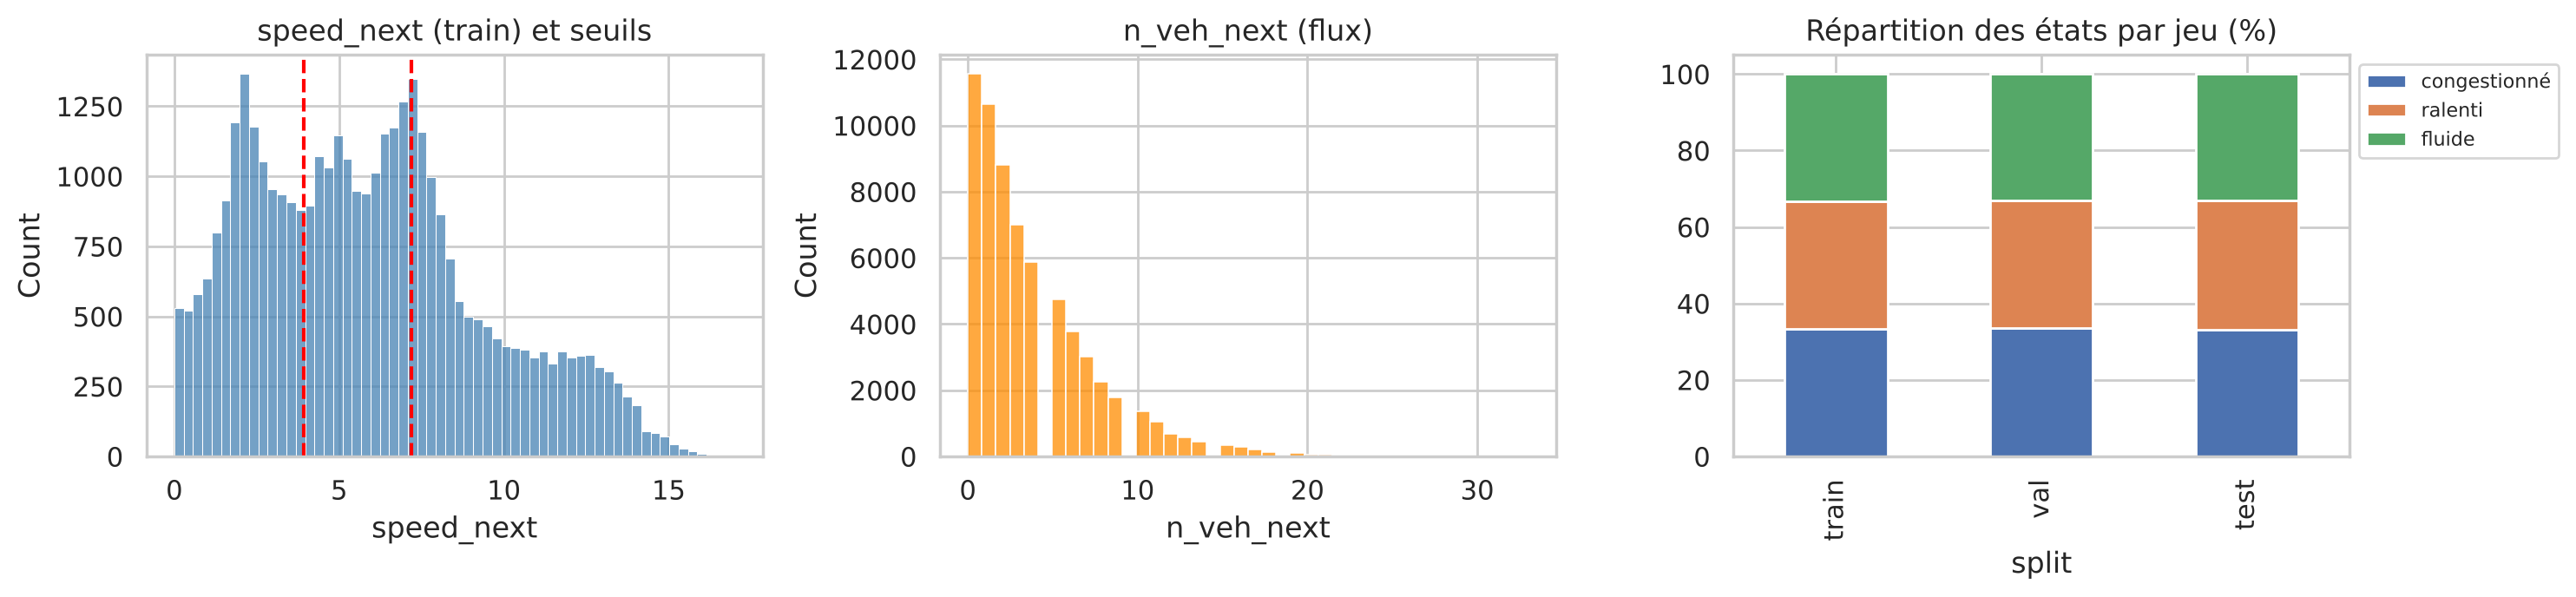

In [24]:
tr_speed = data.loc[(data.split == "train") & data.speed_next.notna(), "speed_next"]
SEUILS = tr_speed.quantile([1/3, 2/3]).values
ETATS  = ["congestionné", "ralenti", "fluide"]           # ordre explicite : du pire au meilleur

data["etat_next"] = pd.cut(data.speed_next, bins=[-np.inf, SEUILS[0], SEUILS[1], np.inf], labels=ETATS)
print(f"Seuils (train) : congestionné <= {SEUILS[0]:.2f} m/s < ralenti <= {SEUILS[1]:.2f} m/s < fluide")

rep = data.groupby("split")["etat_next"].value_counts(normalize=True).unstack().loc[["train", "val", "test"], ETATS]
print((100 * rep).round(1).to_string())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
sns.histplot(tr_speed, bins=60, ax=ax[0], color="steelblue"); ax[0].set_title("speed_next (train) et seuils")
for s in SEUILS: ax[0].axvline(s, color="red", ls="--")
sns.histplot(data.n_veh_next, bins=40, ax=ax[1], color="darkorange"); ax[1].set_title("n_veh_next (flux)")
print(f"\nAsymétrie de n_veh_next : {data.n_veh_next.skew():.2f}   |   asymétrie de speed_next : {data.speed_next.skew():.2f}")
(100 * rep).plot.bar(stacked=True, ax=ax[2]); ax[2].set_title("Répartition des états par jeu (%)"); ax[2].legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.show()

**Observation.** Les trois états sont à peu près équilibrés dans le train (par construction) et restent proches dans la validation et le test : le trafic est **stationnaire**, donc les seuils appris sur le début de la simulation restent valables ensuite. Le flux `n_veh_next` est très asymétrique à droite (beaucoup de petites valeurs, quelques gros pics) : on gardera cette asymétrie en tête pour le choix des métriques (MAE, RMSE) dans la partie 2.

## 8. Imputation, encodage, sélection, normalisation, PCA

### 8.1 Profil historique des cellules (encodage de `cell_id`)

`cell_id` est une variable catégorielle à **170 modalités** (une par cellule). Un *one-hot* ajouterait 170 colonnes presque vides ; un *ordinal* inventerait un ordre qui n'existe pas. On utilise plutôt un **encodage par statistique** : chaque cellule est décrite par son comportement habituel (vitesse moyenne, activité, part d'arrêts), **calculé sur le train uniquement**. Une cellule jamais vue dans le train reçoit la valeur médiane (section 8.2).

Un léger biais subsiste : pour une ligne du train, la moyenne de sa cellule contient (parmi des centaines de fenêtres) sa propre cible. Avec environ 270 fenêtres par cellule, l'effet d'une seule ligne est faible ; le jeu de validation n'a pas ce biais et permettra de le vérifier.

In [25]:
tr = data[data.split == "train"]
profil = tr.groupby("cell_id").agg(cell_speed_mean=("speed_mean", "mean"),
                                   cell_obs_mean=("n_obs", "mean"),
                                   cell_stop_mean=("p_stopped", "mean"))
data = data.merge(profil, left_on="cell_id", right_index=True, how="left")
print(f"{len(profil)} cellules dans le train ; cellules du jeu complet absentes du train : {data.cell_id.nunique() - len(profil)}")
profil.describe().round(2)

170 cellules dans le train ; cellules du jeu complet absentes du train : 0


,cell_speed_mean,cell_obs_mean,cell_stop_mean
count,168.00,170.00,168.00
mean,5.91,59.45,0.15
std,2.90,82.84,0.21
min,0.68,0.00,0.00
25%,3.60,12.39,0.01
50%,5.81,34.16,0.04
75%,7.72,68.82,0.20
max,13.03,574.97,0.86


### 8.2 Valeurs manquantes (imputation)

Les `NaN` restants sont les vitesses et statistiques associées des fenêtres vides. Stratégie du cours (imputation par la **médiane**, robuste aux valeurs extrêmes), avec la médiane **ajustée sur le train** puis appliquée aux trois jeux. L'information « la cellule était vide » n'est pas perdue : elle est portée par `n_obs`, `n_veh` et leurs retards.

In [26]:
META    = ["w", "w_cible", "cell_id", "split"]
CIBLES  = ["speed_next", "n_veh_next", "etat_next"]
FEATS_0 = [c for c in data.columns if c not in META + CIBLES + ["cx", "cy", "speed_sum", "speed_sum_lag1", "speed_sum_lag2"]]
print(f"{len(FEATS_0)} variables candidates")

nan_train = data.loc[data.split == "train", FEATS_0].isna().mean().mul(100).round(1)
print("\n% de NaN dans le train, avant imputation :")
print(nan_train[nan_train > 0].sort_values(ascending=False).to_string())

imputer = SimpleImputer(strategy="median")
imputer.fit(data.loc[data.split == "train", FEATS_0])          # ajusté sur le TRAIN seul
X_all = pd.DataFrame(imputer.transform(data[FEATS_0]), columns=FEATS_0, index=data.index)
print("\nNaN restants :", int(X_all.isna().sum().sum()))

40 variables candidates

% de NaN dans le train, avant imputation :
speed_std          19.2
speed_lag3         17.7
p_stopped_lag3     17.7
acc_abs_mean       17.7
speed_mean         17.6
p_stopped          17.6
speed_max          17.6
speed_min          17.6
p_hard_brake       17.6
p_internal         17.6
lane_idx_max       17.6
sin_mean           17.6
cos_mean           17.6
p_stopped_lag2     17.6
speed_lag1         17.6
speed_lag2         17.6
p_stopped_lag1     17.6
speed_roll3         5.8
cell_speed_mean     1.1
cell_stop_mean      1.1
nb_speed            0.3

NaN restants : 0


### 8.3 Encodage de la cible de classification

Les trois états ont un **ordre naturel** (congestionné < ralenti < fluide). On utilise donc un `OrdinalEncoder` avec l'ordre explicite, car par défaut l'encodeur classerait par ordre alphabétique (`congestionné`, `fluide`, `ralenti`), ce qui serait faux.

In [27]:
enc = OrdinalEncoder(categories=[ETATS])
mask_c = data.etat_next.notna()
y_cls = pd.Series(np.nan, index=data.index)
y_cls[mask_c] = enc.fit_transform(data.loc[mask_c, ["etat_next"]].astype(str)).ravel()
print("Encodage :", {e: i for i, e in enumerate(ETATS)})
print(pd.crosstab(data.etat_next, y_cls, dropna=False).to_string())

Encodage : {'congestionné': 0, 'ralenti': 1, 'fluide': 2}
col_0           0.0    1.0    2.0  NaN
etat_next                             
NaN               0      0      0    0
congestionné  17767      0      0    0
ralenti           0  17816      0    0
fluide            0      0  17724    0


### 8.4 Sélection de variables (sur le train)

Trois filtres, tous calculés sur le **train**, pour la cible de vitesse :

1. **Variance quasi nulle** : une variable constante n'apprend rien.
2. **Redondance** : si deux variables ont une corrélation absolue > 0,95, on en garde une (le moins redondant est préférable pour les modèles linéaires et les ANN ; les arbres y sont moins sensibles).
3. **Pertinence** : classement par `f_regression` (lien linéaire) et `mutual_info_regression` (lien quelconque) avec `speed_next`. Pour la classification, test du **khi-deux** sur les variables mises à l'échelle [0, 1] (le khi-deux exige des valeurs positives).

In [28]:
tr_mask  = (data.split == "train").values
sp_mask  = tr_mask & data.speed_next.notna().values       # train avec cible de vitesse définie
Xtr      = X_all.loc[tr_mask]

# 1. variance
vt = VarianceThreshold(threshold=1e-8).fit(Xtr)
cst = [c for c, keep in zip(FEATS_0, vt.get_support()) if not keep]
print("1. Variables à variance quasi nulle :", cst or "aucune")

# 2. redondance
def filtre_correlation(X, seuil=0.95):
    c = X.corr().abs()
    haut = c.where(np.triu(np.ones(c.shape), k=1).astype(bool))
    return {col: haut.index[haut[col] > seuil].tolist() for col in haut.columns if (haut[col] > seuil).any()}

redondantes = filtre_correlation(Xtr.drop(columns=cst))
print("\n2. Variables redondantes (|r| > 0,95) -> avec quelles variables :")
for k, v in redondantes.items(): print(f"   {k:16s} ~ {v}")
a_supprimer = list(redondantes.keys())

FEATS = [c for c in FEATS_0 if c not in cst + a_supprimer]
print(f"\n=> {len(FEATS)} variables conservées sur {len(FEATS_0)} (retirées : {len(FEATS_0) - len(FEATS)})")

1. Variables à variance quasi nulle : aucune

2. Variables redondantes (|r| > 0,95) -> avec quelles variables :
   n_edges          ~ ['n_lanes']

=> 39 variables conservées sur 40 (retirées : 1)


                 f_regression  mutual_info      chi2  rang_moyen
cell_speed_mean     88525.459        0.793  2868.738       2.667
speed_roll3         59985.707        0.582  2014.421       4.000
cell_stop_mean      13995.729        0.515  3639.013       4.667
speed_mean          41855.224        0.476  1818.542       5.667
speed_lag1          34680.592        0.420  1613.664       6.667
p_stopped           11540.114        0.222  3946.417       7.333
speed_lag2          33223.983        0.394  1560.663       8.000
speed_lag3          32753.445        0.402  1545.180       8.333
p_stopped_lag1      10255.604        0.198  3697.789       8.333
speed_min           12986.873        0.224  2093.757       8.667
cell_obs_mean        8622.829        0.554  1270.707      10.000
p_stopped_lag2       9603.309        0.175  3478.133      10.667
p_stopped_lag3       9161.780        0.169  3350.696      11.667
nb_speed            13646.126        0.187   645.890      13.333
n_obs                7760

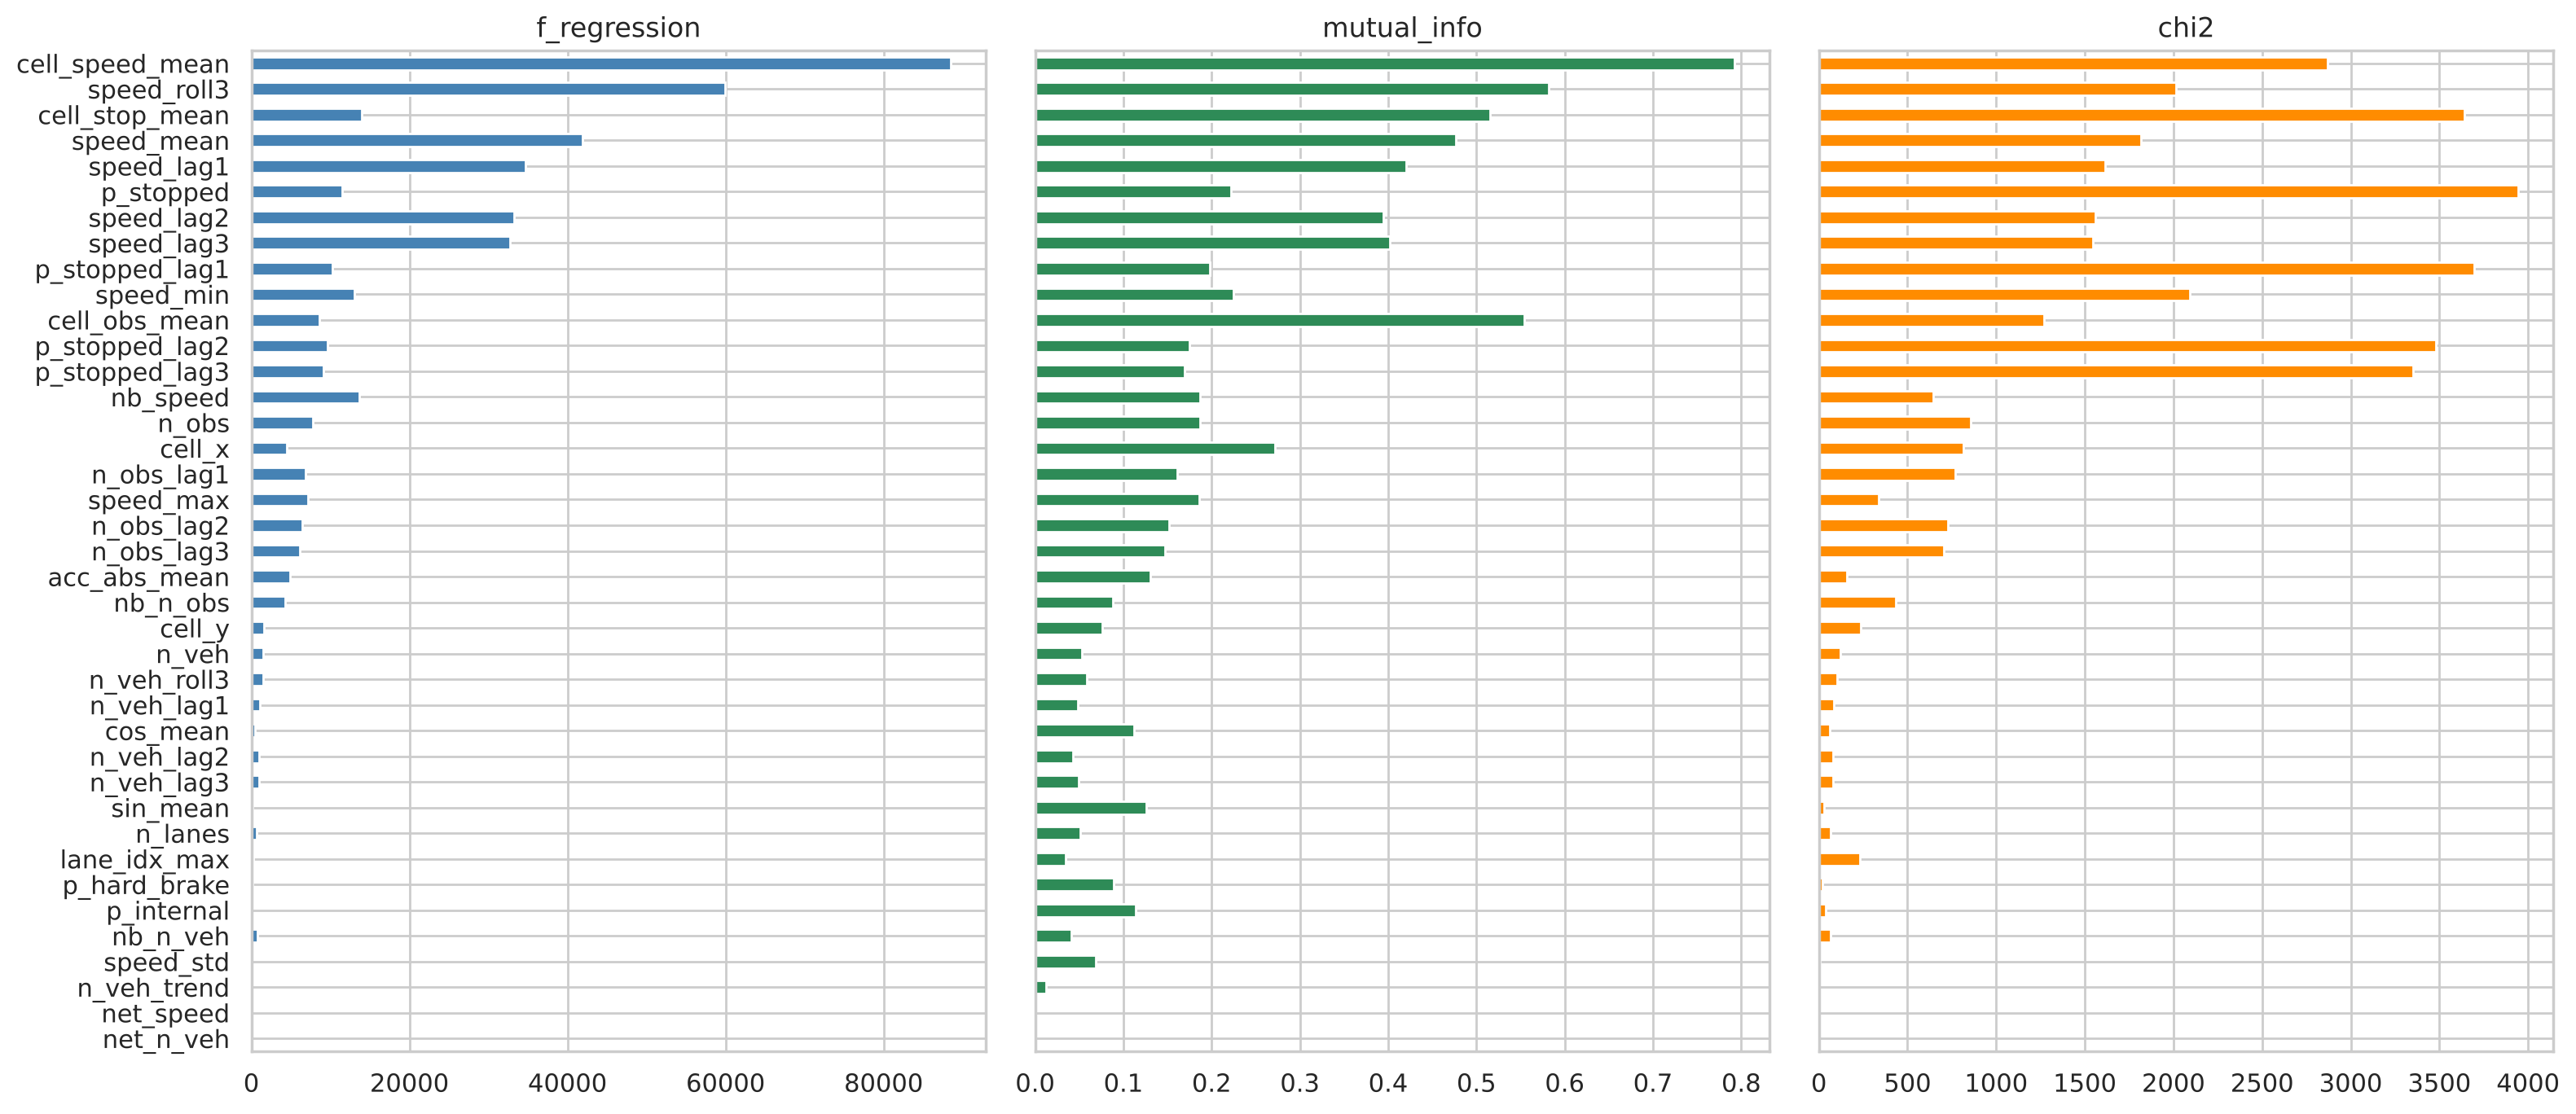

In [29]:
# 3. pertinence (train, cible vitesse définie)
Xs, ys = X_all.loc[sp_mask, FEATS], data.loc[sp_mask, "speed_next"]
f_sc, _ = f_regression(Xs, ys)
rng_idx = np.random.RandomState(SEED).choice(len(Xs), size=min(20_000, len(Xs)), replace=False)
mi_sc = mutual_info_regression(Xs.iloc[rng_idx], ys.iloc[rng_idx], random_state=SEED)

# khi-deux (classification) : variables mises à l'échelle [0, 1]
cl_mask = tr_mask & mask_c.values
Xc = MinMaxScaler().fit_transform(X_all.loc[cl_mask, FEATS])
chi_sc, chi_p = chi2(Xc, y_cls[cl_mask])

scores = pd.DataFrame({"f_regression": f_sc, "mutual_info": mi_sc, "chi2": chi_sc}, index=FEATS)
scores["rang_moyen"] = scores.rank(ascending=False).mean(axis=1)
scores = scores.sort_values("rang_moyen")
print(scores.round(3).head(15).to_string())

# Même question pour la cible de flux (toutes les lignes du train)
f_flux, _ = f_regression(X_all.loc[tr_mask, FEATS], data.loc[tr_mask, "n_veh_next"])
print("\nVariables les plus liées au flux futur n_veh_next (f_regression) :")
print(pd.Series(f_flux, index=FEATS).sort_values(ascending=False).head(6).round(0).to_string())

ordre = scores.index[::-1]          # même ordre (rang moyen) sur les trois graphiques
fig, ax = plt.subplots(1, 3, figsize=(16, 7), sharey=True)
for a, col, c in zip(ax, ["f_regression", "mutual_info", "chi2"], ["steelblue", "seagreen", "darkorange"]):
    scores.loc[ordre, col].plot.barh(ax=a, color=c); a.set_title(col)
plt.tight_layout(); plt.show()

**Lecture et décision.** Les variables les plus liées à la vitesse de la minute suivante sont, sans surprise, la **vitesse actuelle et passée** de la cellule et de son voisinage, la part d'arrêts et le profil historique de la cellule. Le **flux** futur (`n_veh_next`) est surtout lié au flux actuel et récent de la cellule (`n_veh_roll3`, `n_veh`, `n_veh_lag1`) et au flux de ses voisines (`nb_n_veh`).

On ne garde pas seulement le « top-k » : les arbres (partie 2) savent ignorer les variables peu utiles, et un score univarié ne voit pas les **interactions** (par exemple vitesse × densité). On conserve donc toutes les variables non redondantes (`FEATS`), et on utilisera `scores` pour justifier le choix dans le rapport et, si besoin, réduire la dimension pour l'ANN. Les variables `net_speed`, `net_n_veh` et `n_veh_trend` ont un score presque nul pour la vitesse : ce sont les premières candidates à retirer si un modèle sur-apprend, mais on les garde pour tester leur utilité sur le flux.

### 8.5 Transformation et normalisation

Deux versions du même jeu :
- **brute** (`X_*`) pour les arbres, forêts, boosting : ils ne dépendent pas de l'échelle des variables ;
- **normalisée** (`Xs_*`) pour l'ANN : transformation `log(1+x)` des variables de comptage très asymétriques, puis **standardisation** (`StandardScaler`) ajustée sur le train.

Asymétrie (skew) > 2 et valeurs >= 0 -> transformation log(1+x) :
n_obs            3.98
p_hard_brake     3.50
n_obs_lag1       3.99
n_obs_lag2       3.99
n_obs_lag3       3.99
cell_obs_mean    3.13


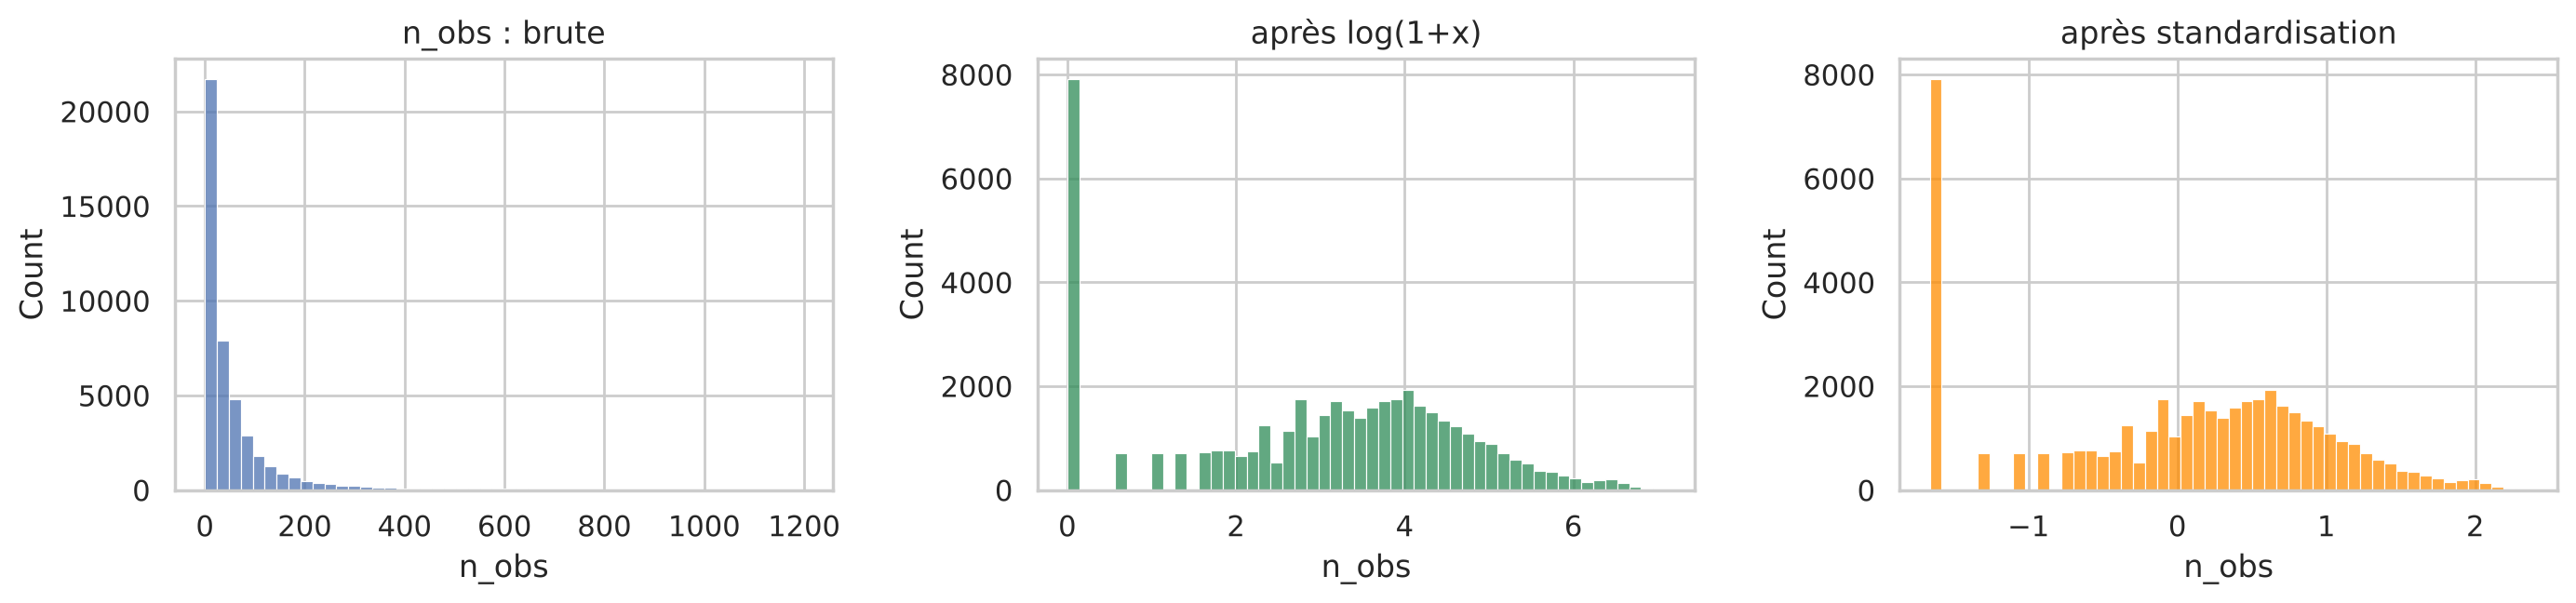


Vérification (train) : moyenne ~ 0 et écart-type ~ 1
     mean  std
min  -0.0  1.0
max   0.0  1.0
Validation (non nulle, c'est normal : statistiques du train) : 0.012


In [30]:
skew_tr = Xtr[FEATS].skew().sort_values(ascending=False)
LOG_COLS = [c for c in FEATS if skew_tr[c] > 2 and X_all[c].min() >= 0]
print("Asymétrie (skew) > 2 et valeurs >= 0 -> transformation log(1+x) :")
print(skew_tr[LOG_COLS].round(2).to_string())

def transformer(X):
    X = X[FEATS].copy()
    X[LOG_COLS] = np.log1p(X[LOG_COLS])
    return X

scaler = StandardScaler().fit(transformer(Xtr))                 # ajusté sur le TRAIN
Xs_all = pd.DataFrame(scaler.transform(transformer(X_all)), columns=FEATS, index=X_all.index)

# Effet visuel sur une variable
c = LOG_COLS[0]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
sns.histplot(Xtr[c], bins=50, ax=ax[0]); ax[0].set_title(f"{c} : brute")
sns.histplot(np.log1p(Xtr[c]), bins=50, ax=ax[1], color="seagreen"); ax[1].set_title("après log(1+x)")
sns.histplot(Xs_all.loc[tr_mask, c], bins=50, ax=ax[2], color="darkorange"); ax[2].set_title("après standardisation")
plt.tight_layout(); plt.show()

print("\nVérification (train) : moyenne ~ 0 et écart-type ~ 1")
print(Xs_all.loc[tr_mask].agg(["mean", "std"]).T.describe().loc[["min", "max"]].round(3).to_string())
print("Validation (non nulle, c'est normal : statistiques du train) :", Xs_all.loc[(data.split == 'val').values].mean().abs().mean().round(3))

### 8.6 Réduction de dimension (PCA)

La PCA (analyse en composantes principales) sert ici à **mesurer la redondance** entre variables et à visualiser les classes en 2D. Elle est ajustée sur le train normalisé. On ne l'impose pas aux modèles : les composantes sont difficiles à interpréter et les arbres n'en ont pas besoin. Elle reste disponible pour l'ANN.

23 composantes sur 39 expliquent 95 % de la variance ; 11 expliquent 80 %


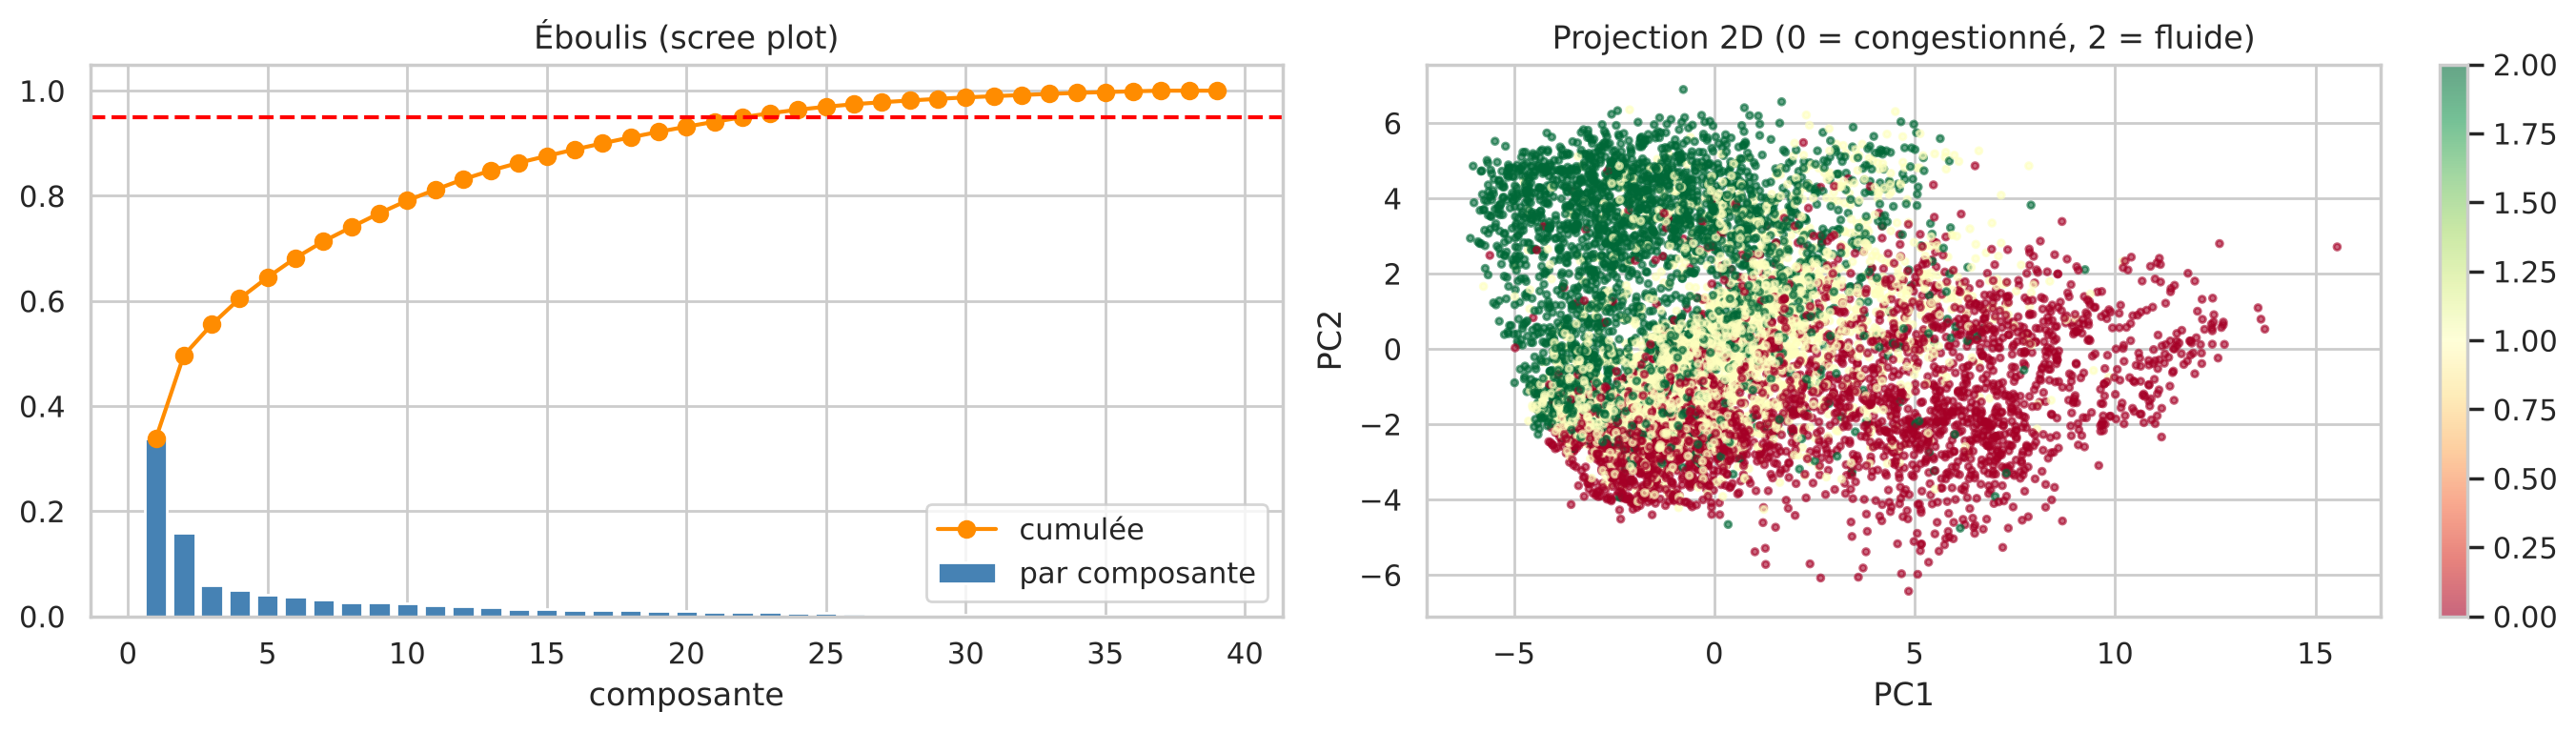

Variables qui pèsent le plus sur PC1 :
cell_obs_mean     0.24
n_veh_roll3       0.23
cell_stop_mean    0.23
n_obs             0.22
n_obs_lag1        0.22
p_stopped_lag1    0.21
Variables qui pèsent le plus sur PC2 :
speed_max          0.32
cell_speed_mean    0.29
speed_roll3        0.29
speed_mean         0.28
speed_lag2         0.26
speed_lag1         0.26
Variance expliquée par PC1 + PC2 : 50 %


In [31]:
pca = PCA(random_state=SEED).fit(Xs_all.loc[tr_mask])
cumul = np.cumsum(pca.explained_variance_ratio_)
n95 = int(np.argmax(cumul >= 0.95) + 1)
print(f"{n95} composantes sur {len(FEATS)} expliquent 95 % de la variance ; {int(np.argmax(cumul >= 0.80) + 1)} expliquent 80 %")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(range(1, len(cumul) + 1), pca.explained_variance_ratio_, color="steelblue", label="par composante")
ax[0].plot(range(1, len(cumul) + 1), cumul, "o-", color="darkorange", label="cumulée")
ax[0].axhline(0.95, color="red", ls="--"); ax[0].set_xlabel("composante"); ax[0].set_title("Éboulis (scree plot)"); ax[0].legend()

pts = np.random.RandomState(SEED).choice(np.where(cl_mask)[0], size=min(8000, cl_mask.sum()), replace=False)
Z = pca.transform(Xs_all.iloc[pts])[:, :2]
sc = ax[1].scatter(Z[:, 0], Z[:, 1], c=y_cls.iloc[pts], cmap="RdYlGn", s=6, alpha=0.6)
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].set_title("Projection 2D (0 = congestionné, 2 = fluide)"); plt.colorbar(sc, ax=ax[1])
plt.tight_layout(); plt.show()

load = pd.DataFrame(pca.components_[:2].T, index=FEATS, columns=["PC1", "PC2"])
print("Variables qui pèsent le plus sur PC1 :"); print(load.PC1.abs().sort_values(ascending=False).head(6).round(2).to_string())
print("Variables qui pèsent le plus sur PC2 :"); print(load.PC2.abs().sort_values(ascending=False).head(6).round(2).to_string())
print(f"Variance expliquée par PC1 + PC2 : {100*cumul[1]:.0f} %")

**Lecture.** La première composante (environ un tiers de la variance) oppose les cellules **actives** (beaucoup de véhicules, beaucoup d'arrêts) aux cellules calmes ; la deuxième (environ 15 %) est dominée par les **variables de vitesse**. À elles deux elles expliquent la moitié de la variance et suffisent déjà à séparer en grande partie les trois états : les cellules fluides se regroupent d'un côté de la projection, les cellules congestionnées de l'autre. En revanche, il faut **23 composantes sur 39** pour atteindre 95 % : la redondance est modérée, la réduction de dimension n'est pas indispensable ici et on gardera les variables d'origine pour garder des modèles interprétables.

## 9. Jeux finaux, sauvegarde et rapport qualité

On sauvegarde, pour chaque partie (`train`, `val`, `test`), le tableau **brut** et le tableau **normalisé**, avec les trois cibles. Les parties 2 et 3 n'ont qu'à relire ces fichiers : pas de recalcul, pas de risque de refaire une fuite par accident.

Rappel d'utilisation :
- **régression de la vitesse** : garder les lignes où `speed_next` n'est pas `NaN` ;
- **régression du flux** : toutes les lignes (`n_veh_next`) ;
- **classification** : lignes où `etat_next_code` n'est pas `NaN`.

In [32]:
os.makedirs(OUT_DIR, exist_ok=True)

final = pd.concat([data[META], X_all[FEATS], data[["speed_next", "n_veh_next"]], y_cls.rename("etat_next_code")], axis=1)
final_s = pd.concat([data[META], Xs_all[FEATS], data[["speed_next", "n_veh_next"]], y_cls.rename("etat_next_code")], axis=1)

for nom in ["train", "val", "test"]:
    final[final.split == nom].drop(columns="split").to_parquet(f"{OUT_DIR}/{nom}_raw.parquet", index=False)
    final_s[final_s.split == nom].drop(columns="split").to_parquet(f"{OUT_DIR}/{nom}_scaled.parquet", index=False)

joblib.dump({"imputer": imputer, "scaler": scaler, "pca": pca, "ordinal_encoder": enc}, f"{OUT_DIR}/transformers.joblib")
meta = {"CELL": CELL, "WINDOW": WINDOW, "N_LAGS": N_LAGS, "SEED": SEED, "features": FEATS, "log_cols": LOG_COLS,
        "etats": ETATS, "seuils_etat_m_s": [float(s) for s in SEUILS], "T1": T1, "T2": T2, "n_fenetres": int(W),
        "grille": [int(NX), int(NY)], "features_candidates": FEATS_0, "features_retirees": cst + a_supprimer}
json.dump(meta, open(f"{OUT_DIR}/meta.json", "w"), indent=2, ensure_ascii=False)

print(f"Fichiers écrits dans {OUT_DIR}/ :", sorted(os.listdir(OUT_DIR)))
for nom in ["train", "val", "test"]:
    f_ = final[final.split == nom]
    print(f"{nom:5s}: {len(f_):6,} lignes | speed_next défini : {f_.speed_next.notna().sum():6,} | classes définies : {f_.etat_next_code.notna().sum():6,}")

Fichiers écrits dans data_prepared/ : ['meta.json', 'rl_flux_axes.parquet', 'test_raw.parquet', 'test_scaled.parquet', 'train_raw.parquet', 'train_scaled.parquet', 'transformers.joblib', 'val_raw.parquet', 'val_scaled.parquet']
train: 44,873 lignes | speed_next défini : 36,950 | classes définies : 36,950
val  :  9,990 lignes | speed_next défini :  8,180 | classes définies :  8,180
test : 10,000 lignes | speed_next défini :  8,177 | classes définies :  8,177


In [33]:
# Relecture de contrôle : mêmes colonnes, pas de NaN dans les variables explicatives
chk = pd.read_parquet(f"{OUT_DIR}/train_scaled.parquet")
assert chk[FEATS].isna().sum().sum() == 0
print("Relecture OK :", chk.shape, "| variables explicatives sans NaN")

Relecture OK : (44873, 45) | variables explicatives sans NaN


### Rapport qualité (synthèse, à reprendre dans le rapport technique)

In [34]:
rapport = pd.DataFrame([
    ["Valeurs manquantes (fichier brut)", "Non", "0 sur 8 colonnes", "Aucune action"],
    ["Valeurs manquantes (après agrégation)", "Oui", f"{100*grille.speed_mean.isna().mean():.0f} % des cellules x fenêtres sans véhicule", "Comptages = 0 ; vitesses imputées par médiane du train ; `n_obs` conserve l'information « vide »"],
    ["Doublons", "Non", f"{n_dup_total} lignes, {n_dup_cle} sur (step, id)", "Aucune action"],
    ["Colonne constante", "Oui", "`type` : une seule modalité (veh_passenger)", "Supprimée"],
    ["Identifiant", "Oui", "`id` : 9 863 véhicules", "Exclu des variables explicatives"],
    ["Valeurs aberrantes statistiques", "Oui", f"IQR : {n_iqr:,} ({100*n_iqr/n_brut:.2f} %) ; z-score : {n_z:,} ({100*n_z/n_brut:.2f} %)", "Conservées : vitesses élevées plausibles (max 67 km/h)"],
    ["Anomalies physiques (téléportations)", "Oui", f"{n_tele} sauts impossibles ; {n_trous} trous temporels", "Lignes supprimées dans `nettoyer()`"],
    ["Distribution", "Oui", f"{100*p_zero:.0f} % de vitesses nulles (pic en 0 + trois régimes)", "Variable `p_stopped` ; état discret en cible"],
    ["Variable circulaire", "Oui", "`angle` (0-360°)", "Remplacée par sin / cos"],
    ["Variables corrélées / redondantes", "Oui", f"{len(a_supprimer)} variables avec |r| > 0,95", f"Retirées : {a_supprimer}"],
    ["Déséquilibre de classes", "Non", "Terciles du train : ~ 33 % / 33 % / 33 %", "Seuils appris sur le train"],
    ["Risque de fuite", "Oui", "Historique, cibles t+1, normalisation, seuils, imputation, profil des cellules", "Découpage chronologique ; tout ajusté sur le train ; contrôles par `assert`"],
    ["Taille de l'échantillon", "OK", f"{len(data):,} lignes (cellule x minute)", "Suffisant pour arbres, boosting et ANN"],
], columns=["Problème", "Détecté ?", "Où / combien", "Décision prise"])
pd.set_option("display.max_colwidth", None)
rapport

,Problème,Détecté ?,Où / combien,Décision prise
0,Valeurs manquantes (fichier brut),Non,0 sur 8 colonnes,Aucune action
1,Valeurs manquantes (après agrégation),Oui,18 % des cellules x fenêtres sans véhicule,Comptages = 0 ; vitesses imputées par médiane du train ; `n_obs` conserve l'information « vide »
2,Doublons,Non,"0 lignes, 0 sur (step, id)",Aucune action
3,Colonne constante,Oui,`type` : une seule modalité (veh_passenger),Supprimée
4,Identifiant,Oui,`id` : 9 863 véhicules,Exclu des variables explicatives
5,Valeurs aberrantes statistiques,Oui,"IQR : 980 (0.02 %) ; z-score : 7,253 (0.18 %)",Conservées : vitesses élevées plausibles (max 67 km/h)
6,Anomalies physiques (téléportations),Oui,63 sauts impossibles ; 46 trous temporels,Lignes supprimées dans `nettoyer()`
7,Distribution,Oui,43 % de vitesses nulles (pic en 0 + trois régimes),Variable `p_stopped` ; état discret en cible
8,Variable circulaire,Oui,`angle` (0-360°),Remplacée par sin / cos
9,Variables corrélées / redondantes,Oui,"1 variables avec |r| > 0,95",Retirées : ['n_edges']


### Données pour la partie 4 (Reinforcement Learning, bonus)

Le dataset ne contient ni feux ni décisions de régulation : pour la partie RL on construira un **environnement simulé** (un carrefour à feux). Pour qu'il reste **ancré dans les données réelles**, on exporte ici les flux observés, par minute, dans les cellules les plus chargées :

- les véhicules sont séparés en **deux axes de circulation** selon leur cap (`angle mod 180`) : axe 0 pour les caps d'environ 50° et 230°, axe 1 pour 140° et 320° (les deux familles de routes du damier) ;
- pour chaque cellule et chaque minute : nombre de véhicules distincts de chaque axe (proxy du flux entrant) et vitesse moyenne.

In [35]:
axe = (dt_clean["angle"] % 180 >= 90).astype("int8")            # 0 : caps ~50°/230° ; 1 : caps ~140°/320°
x0, y0 = float(dt_clean.x.min()), float(dt_clean.y.min())
flux_axes = pd.DataFrame({"w": (dt_clean.step // WINDOW).astype("int32"),
                          "cell_id": (((dt_clean.y - y0) // CELL).astype("int32") * NX + ((dt_clean.x - x0) // CELL).astype("int32")),
                          "id": dt_clean["id"], "axe": axe})
top_cells = grille.groupby("cell_id")["n_obs"].sum().nlargest(5).index.tolist()
flux_axes = flux_axes[flux_axes.cell_id.isin(top_cells)]
flux_axes = (flux_axes.groupby(["cell_id", "w", "axe"], observed=True)["id"].nunique().unstack("axe", fill_value=0)
             .rename(columns={0: "n_axe0", 1: "n_axe1"}).reset_index())
# fenêtres sans aucun véhicule : à compléter avec des zéros pour que les séries soient régulières
idx = pd.MultiIndex.from_product([top_cells, range(W)], names=["cell_id", "w"])
flux_axes = flux_axes.set_index(["cell_id", "w"]).reindex(idx, fill_value=0).reset_index()
flux_axes = flux_axes.merge(grille[["cell_id", "w", "cell_x", "cell_y", "speed_mean", "p_stopped"]], on=["cell_id", "w"], how="left")
os.makedirs(OUT_DIR, exist_ok=True)
flux_axes.to_parquet(f"{OUT_DIR}/rl_flux_axes.parquet", index=False)

resume = flux_axes.groupby("cell_id").agg(cell_x=("cell_x", "first"), cell_y=("cell_y", "first"),
                                          axe0_veh_min=("n_axe0", "mean"), axe1_veh_min=("n_axe1", "mean"),
                                          axe0_p95=("n_axe0", lambda s: s.quantile(.95)), axe1_p95=("n_axe1", lambda s: s.quantile(.95)),
                                          vitesse_moy=("speed_mean", "mean"))
print("Cellules les plus chargées (flux moyen par minute et par axe, p95 = pic) :")
print(resume.round(2).to_string())

Cellules les plus chargées (flux moyen par minute et par axe, p95 = pic) :
          cell_x  cell_y  axe0_veh_min  axe1_veh_min  axe0_p95  axe1_p95  vitesse_moy
cell_id                                                                              
27       1048.66  150.18          2.91          6.47       6.0     11.00         0.68
42        848.66  250.18          3.23         13.31       6.0     17.35         1.08
75        748.66  450.18         12.14          7.98      20.0     15.00         2.37
93        848.66  550.18         11.25         11.12      18.0     19.00         2.30
112      1048.66  650.18          6.80          1.61      15.0      5.00         2.27


## Conclusion de la partie 1

- Le fichier brut est **propre** (aucun manquant, aucun doublon) mais **massif** (3,9 M de lignes) et **sans cible** : la construction des observations « cellule × minute » est le cœur du travail.
- Le trafic simulé est **stationnaire** (environ 165 véhicules en permanence) ; la difficulté de prédiction vient de la **géographie** et des **arrêts** (feux, files), pas d'une tendance globale.
- Les jeux sont **chronologiques** et sans fuite : 70 % / 15 % / 15 % des minutes, tous les paramètres appris sur le train.
- Le dossier `data_prepared/` contient tout ce qu'il faut pour les parties suivantes : **Ensemble Learning** (jeux bruts, arbres / Random Forest / XGBoost), **ANN** (jeux normalisés) et **RL** (`rl_flux_axes.parquet`, flux réels par axe dans les cellules les plus chargées).

**Pistes à discuter pour la suite** : tester `CELL = 150` ou `WINDOW = 30` (compromis finesse / stabilité), comparer le découpage chronologique à une validation croisée *par blocs de temps*, et utiliser la même grille comme **environnement** pour la partie bonus (apprentissage par renforcement sur la régulation de feux ou le choix d'itinéraire).

In [36]:
# Libération de la mémoire : les trajectoires brutes ne sont plus nécessaires pour les parties suivantes
import gc
for v in ["dt_clean", "grille", "flux_axes", "X_all", "Xs_all", "data", "final", "final_s", "d"]:
    globals().pop(v, None)
gc.collect()

18161

---
---
<a id='partie2'></a>

# Partie 2 : Ensemble Learning, Bagging et Boosting

**Projet : Smart Traffic Flow Prediction and Optimization**

Cette partie utilise les jeux préparés par la partie 1 (`data_prepared/`, découpage chronologique train / validation / test, aucune fuite) et compare :

| Famille | Algorithme | Rôle |
|---|---|---|
| Référence | arbre de décision seul | montrer le surapprentissage d'un modèle unique |
| **Bagging** | **Random Forest** | réduire la variance |
| **Boosting** | **XGBoost** et AdaBoost | réduire le biais |

**Trois tâches** (toutes pour la **minute suivante**, par cellule de 100 m) :

| Tâche | Type | Cible | Métriques |
|---|---|---|---|
| `etat` | classification (3 classes) | congestionné / ralenti / fluide | accuracy, F1 macro, rappel par classe, AUC |
| `vitesse` | régression | vitesse moyenne `speed_next` | MAE, RMSE, R² |
| `flux` | régression | nombre de véhicules `n_veh_next` | MAE, RMSE, R² |

**Règle d'or** : les modèles sont ajustés sur le **train**, les hyperparamètres choisis sur la **validation**, et le **test** n'est utilisé qu'une seule fois, à la fin, pour la comparaison finale.

**Plan** : 1. données et références · 2. arbre seul · 3. Bagging · 4. Boosting · 5. comparaison · 6. évaluation finale sur le test · 7. avantages et limites.

In [37]:
# ===== Configuration commune aux parties 2 à 5 =====
import os, sys, json, time, warnings, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
SEED = 42
np.random.seed(SEED)

# ---- Données préparées par la partie 1 (dossier data_prepared/ du dépôt) ----
REPO_URL = "https://github.com/ghirr/Smart-Traffic-Flow-Prediction-and-Optimization.git"
BRANCH   = "main"                      # branche du dépôt qui contient data_prepared/ et results/
if not os.path.exists("data_prepared/meta.json") and "google.colab" in sys.modules:
    subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH, REPO_URL, "/content/repo"], check=True)
    os.chdir("/content/repo")
assert os.path.exists("data_prepared/meta.json"), "Dossier data_prepared/ introuvable : exécutez la partie 1 ou clonez le dépôt."
os.makedirs("results", exist_ok=True)

META   = json.load(open("data_prepared/meta.json"))
FEATS  = META["features"]
ETATS  = META["etats"]                 # ['congestionné', 'ralenti', 'fluide']
SEUILS = META["seuils_etat_m_s"]
SPLITS = ("train", "val", "test")

def charger(suffixe):
    """Retourne les trois jeux (train, val, test) : suffixe = 'raw' (arbres) ou 'scaled' (ANN)."""
    return [pd.read_parquet(f"data_prepared/{s}_{suffixe}.parquet") for s in SPLITS]

# Les trois tâches de prédiction (cibles de la minute suivante)
TASKS = {
    "etat":    dict(target="etat_next_code", kind="clf", nom="État du trafic"),
    "vitesse": dict(target="speed_next",     kind="reg", nom="Vitesse moyenne (m/s)"),
    "flux":    dict(target="n_veh_next",     kind="reg", nom="Flux (nb de véhicules)"),
}

from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             f1_score, recall_score, roc_auc_score, confusion_matrix)

def metriques(kind, y, pred, proba=None):
    """Métriques adaptées à la tâche : régression (MAE, RMSE, R²) ou classification (accuracy, F1 macro, rappels, AUC)."""
    if kind == "reg":
        return {"MAE": mean_absolute_error(y, pred), "RMSE": mean_squared_error(y, pred) ** 0.5, "R2": r2_score(y, pred)}
    rec = recall_score(y, pred, average=None, labels=[0, 1, 2])
    out = {"Accuracy": accuracy_score(y, pred), "F1_macro": f1_score(y, pred, average="macro"),
           "Rappel_congestionné": rec[0], "Rappel_ralenti": rec[1], "Rappel_fluide": rec[2]}
    if proba is not None:
        out["AUC_ovr"] = roc_auc_score(y, proba, multi_class="ovr")
    return out

def perte(kind, y, pred):
    """Critère unique de sélection (à minimiser) : MAE en régression, 1 - F1 macro en classification."""
    return mean_absolute_error(y, pred) if kind == "reg" else 1 - f1_score(y, pred, average="macro")

import xgboost as xgb
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              AdaBoostRegressor, AdaBoostClassifier)
from sklearn.inspection import permutation_importance
from sklearn.model_selection import ParameterSampler

## 1. Données et modèles de référence

On charge les jeux **bruts** (non normalisés) : les modèles à base d'arbres ne dépendent pas de l'échelle des variables.

Rappel de la partie 1 : `speed_next` n'existe que si la cellule contient au moins un véhicule à `t+1`. Les tâches `vitesse` et `etat` utilisent donc seulement ces lignes ; la tâche `flux` utilise toutes les lignes.

In [38]:
RAW = charger("raw")

def X_y(df, tache):
    d = df.dropna(subset=[tache["target"]])
    y = d[tache["target"]].astype(int) if tache["kind"] == "clf" else d[tache["target"]].astype(float)
    return d[FEATS], y

DATA = {t: {s: X_y(df, TASKS[t]) for s, df in zip(SPLITS, RAW)} for t in TASKS}
print(pd.DataFrame({t: {s: len(DATA[t][s][1]) for s in SPLITS} for t in TASKS}).T.to_string())
print(f"\n{len(FEATS)} variables explicatives")

         train   val   test
etat     36950  8180   8177
vitesse  36950  8180   8177
flux     44873  9990  10000

39 variables explicatives


### Références simples (à battre)

Un modèle de Machine Learning n'a de valeur que s'il fait **mieux que des règles triviales**. On compare à :

- **Persistance** : la minute prochaine ressemble à la minute actuelle (flux = `n_veh`, vitesse = vitesse moyenne récente, état = état correspondant à la vitesse récente) ;
- **Profil de la cellule** : vitesse habituelle de la cellule (`cell_speed_mean`, calculée sur le train).

In [39]:
PROFIL_FLUX = RAW[0].groupby("cell_id")["n_veh_next"].mean()       # flux habituel par cellule (train)

def references(split):
    i = SPLITS.index(split)
    out = {}
    X, y = DATA["vitesse"][split]
    out[("vitesse", "Persistance")]     = metriques("reg", y, X.speed_roll3.fillna(X.cell_speed_mean))
    out[("vitesse", "Profil cellule")]  = metriques("reg", y, X.cell_speed_mean)
    X, y = DATA["flux"][split]
    cell = RAW[i].loc[X.index, "cell_id"]
    out[("flux", "Persistance")]        = metriques("reg", y, X.n_veh_roll3)
    out[("flux", "Profil cellule")]     = metriques("reg", y, cell.map(PROFIL_FLUX).fillna(PROFIL_FLUX.mean()))
    X, y = DATA["etat"][split]
    out[("etat", "Persistance")]        = metriques("clf", y, np.digitize(X.speed_roll3.fillna(X.cell_speed_mean), SEUILS))
    out[("etat", "Profil cellule")]     = metriques("clf", y, np.digitize(X.cell_speed_mean, SEUILS))
    return out

ref_val = references("val")
cols = {"etat": "F1_macro", "vitesse": "MAE", "flux": "MAE"}
print("Références sur la validation (critère principal : F1 macro pour 'etat', MAE sinon) :")
for (t, n), m in ref_val.items():
    print(f"  {t:8s} {n:15s} {cols[t]} = {m[cols[t]]:.3f}")

Références sur la validation (critère principal : F1 macro pour 'etat', MAE sinon) :
  vitesse  Persistance     MAE = 1.525
  vitesse  Profil cellule  MAE = 1.362
  flux     Persistance     MAE = 1.607
  flux     Profil cellule  MAE = 1.523
  etat     Persistance     F1_macro = 0.696
  etat     Profil cellule  F1_macro = 0.714


## 2. Un seul arbre de décision : le surapprentissage

Un arbre profond « apprend par cœur » le train. On le montre en faisant varier la profondeur (tâche `vitesse`) : l'erreur d'entraînement descend toujours, l'erreur de validation remonte au-delà d'une certaine profondeur. C'est exactement ce que les méthodes d'ensemble corrigent.

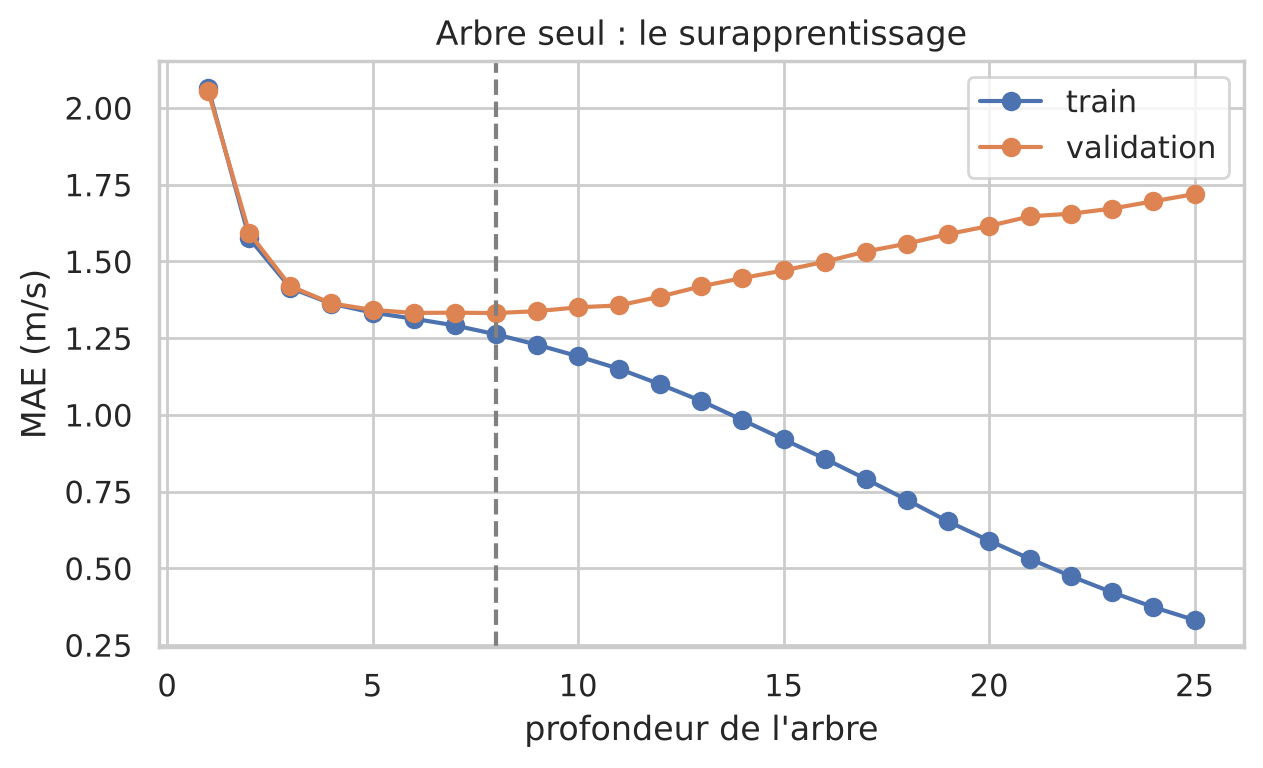

Meilleure profondeur (validation) : 8, MAE val = 1.332
Arbre non limité (profondeur 25) : MAE train = 0.332 vs MAE val = 1.719


In [40]:
Xa, ya = DATA["vitesse"]["train"]; Xb, yb = DATA["vitesse"]["val"]
prof = list(range(1, 26))
mae_tr, mae_va = [], []
for d in prof:
    arbre = DecisionTreeRegressor(max_depth=d, random_state=SEED).fit(Xa, ya)
    mae_tr.append(mean_absolute_error(ya, arbre.predict(Xa)))
    mae_va.append(mean_absolute_error(yb, arbre.predict(Xb)))

best_d = prof[int(np.argmin(mae_va))]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(prof, mae_tr, "o-", label="train"); ax.plot(prof, mae_va, "o-", label="validation")
ax.axvline(best_d, color="gray", ls="--"); ax.set_xlabel("profondeur de l'arbre"); ax.set_ylabel("MAE (m/s)")
ax.set_title("Arbre seul : le surapprentissage"); ax.legend(); plt.show()
print(f"Meilleure profondeur (validation) : {best_d}, MAE val = {min(mae_va):.3f}")
print(f"Arbre non limité (profondeur 25) : MAE train = {mae_tr[-1]:.3f} vs MAE val = {mae_va[-1]:.3f}")
arbre_ref = {"depth": best_d, "mae_val": min(mae_va)}

## 3. Bagging : Random Forest

**Principe.**
1. On tire `B` échantillons **bootstrap** du train (tirage avec remise).
2. On entraîne un arbre profond sur chacun.
3. À chaque coupure, l'arbre ne regarde qu'un **sous-ensemble aléatoire de variables** (c'est ce qui distingue la forêt aléatoire du bagging simple).
4. Prédiction : **moyenne** des arbres (régression) ou **vote** (classification).

Chaque arbre seul a une forte variance (il suit le bruit de son échantillon) ; la moyenne de nombreux arbres peu corrélés a une variance bien plus faible, sans augmenter le biais.

**Pourquoi ce choix ici ?**
- Les variables sont nombreuses et **corrélées** (retards, moyennes glissantes) : la forêt le tolère bien.
- Les relations sont **non linéaires** et locales (zone lente / rapide, effets de seuil dus aux feux).
- Le jeu a des **valeurs extrêmes** (pics de flux) : les arbres y sont robustes, sans normalisation.
- Peu sensible au choix des hyperparamètres, c'est un bon point de départ.

**Hyperparamètres optimisés** (recherche aléatoire, évaluée sur la validation) : nombre d'arbres, profondeur maximale, taille minimale des feuilles, fraction de variables par coupure, taille des échantillons bootstrap.

In [41]:
ESPACES = {
    "RandomForest": {"n_estimators": [100, 150], "max_depth": [12, 20, None],
                     "min_samples_leaf": [3, 5, 10], "max_features": ["sqrt", 0.3],
                     "max_samples": [0.5, 0.7]},
    "XGBoost":      {"learning_rate": [0.02, 0.05, 0.1], "max_depth": [3, 4, 6, 8], "min_child_weight": [1, 5, 10],
                     "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.5, 0.7, 1.0], "reg_lambda": [0.5, 1, 5, 10]},
    "AdaBoost":     {"n_estimators": [50, 100, 200], "learning_rate": [0.05, 0.1, 0.5, 1.0], "depth": [2, 3, 4]},
}
N_ITER = {"RandomForest": 6, "XGBoost": 25, "AdaBoost": 4}

def fabrique(famille, kind, p):
    p = dict(p)
    if famille == "RandomForest":
        cls = RandomForestClassifier if kind == "clf" else RandomForestRegressor
        return cls(n_jobs=-1, random_state=SEED, **p)
    if famille == "XGBoost":
        cls = xgb.XGBClassifier if kind == "clf" else xgb.XGBRegressor
        return cls(n_estimators=2000, early_stopping_rounds=50, tree_method="hist", n_jobs=-1, random_state=SEED,
                   eval_metric="mlogloss" if kind == "clf" else "mae", **p)
    if famille == "AdaBoost":
        d = p.pop("depth")
        if kind == "clf":
            return AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=d, random_state=SEED), random_state=SEED, **p)
        return AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=d, random_state=SEED), random_state=SEED, **p)

def ajuster(famille, modele, Xa, ya, Xb, yb):
    if famille == "XGBoost":      # arrêt anticipé : on garde le nombre d'arbres qui minimise l'erreur de validation
        modele.fit(Xa, ya, eval_set=[(Xa, ya), (Xb, yb)], verbose=False)
    else:
        modele.fit(Xa, ya)
    return modele

def chercher(famille, tache):
    """Recherche aléatoire : on entraîne sur le train, on évalue sur la validation, on garde le meilleur."""
    kind = TASKS[tache]["kind"]
    (Xa, ya), (Xb, yb) = DATA[tache]["train"], DATA[tache]["val"]
    essais, meilleur = [], (np.inf, None, None, None)
    for p in ParameterSampler(ESPACES[famille], N_ITER[famille], random_state=SEED):
        t0 = time.time()
        mod = ajuster(famille, fabrique(famille, kind, p), Xa, ya, Xb, yb)
        temps = time.time() - t0
        sc = perte(kind, yb, mod.predict(Xb))
        ligne = {**p, "perte_val": sc, "temps_s": temps}
        if famille == "XGBoost": ligne["n_arbres"] = int(mod.best_iteration + 1)
        essais.append(ligne)
        if sc < meilleur[0]: meilleur = (sc, p, mod, temps)
    return pd.DataFrame(essais).sort_values("perte_val").reset_index(drop=True), meilleur

MODELES, ESSAIS, PARAMS, TEMPS = {}, {}, {}, {}      # résultats par (tâche, famille)
def lancer(famille):
    for t in TASKS:
        essais, (sc, p, mod, temps) = chercher(famille, t)
        ESSAIS[(t, famille)], MODELES[(t, famille)], PARAMS[(t, famille)], TEMPS[(t, famille)] = essais, mod, p, temps
        print(f"{famille:12s} {t:8s}  meilleure perte validation = {sc:.4f}  ({len(essais)} essais, {essais.temps_s.sum():.0f} s)")

In [42]:
lancer("RandomForest")

RandomForest etat      meilleure perte validation = 0.2627  (6 essais, 26 s)


RandomForest vitesse   meilleure perte validation = 1.2945  (6 essais, 24 s)


RandomForest flux      meilleure perte validation = 1.4023  (6 essais, 26 s)


In [43]:
for t in TASKS:
    e = ESSAIS[(t, "RandomForest")]
    print(f"\n=== RandomForest / {t} : 3 meilleurs essais (perte = {'1 - F1 macro' if TASKS[t]['kind']=='clf' else 'MAE'}) ===")
    print(e.head(3).round(4).to_string(index=False))


=== RandomForest / etat : 3 meilleurs essais (perte = 1 - F1 macro) ===
 n_estimators  min_samples_leaf  max_samples max_features  max_depth  perte_val  temps_s
          100                 3          0.7          0.3       12.0     0.2627   6.9107
          100                10          0.5         sqrt       12.0     0.2640   2.8130
          100                 3          0.5         sqrt       12.0     0.2645   3.0845

=== RandomForest / vitesse : 3 meilleurs essais (perte = MAE) ===
 n_estimators  min_samples_leaf  max_samples max_features  max_depth  perte_val  temps_s
          100                 5          0.5          0.3        NaN     1.2945   6.0919
          100                 3          0.7          0.3       12.0     1.2946   6.2403
          100                 5          0.5         sqrt        NaN     1.3079   3.5130

=== RandomForest / flux : 3 meilleurs essais (perte = MAE) ===
 n_estimators  min_samples_leaf  max_samples max_features  max_depth  perte_val  tem

**Combien d'arbres faut-il ?** On ajoute des arbres un par un (à hyperparamètres fixés) et on regarde l'erreur de validation : elle se stabilise, **ajouter des arbres ne cause pas de surapprentissage** en bagging, il coûte seulement du temps de calcul.

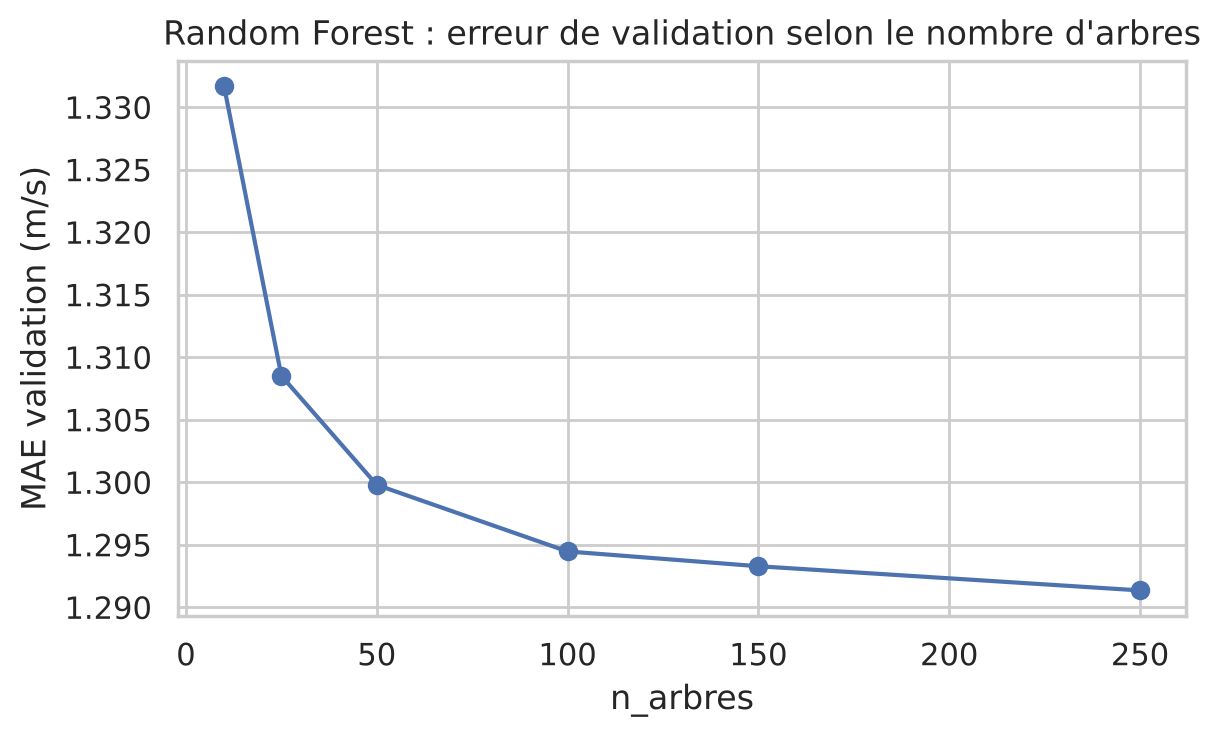

 n_arbres  MAE_val
       10   1.3317
       25   1.3085
       50   1.2998
      100   1.2945
      150   1.2933
      250   1.2913


In [44]:
p = dict(PARAMS[("vitesse", "RandomForest")]); p.pop("n_estimators")
foret = RandomForestRegressor(n_estimators=10, warm_start=True, n_jobs=-1, random_state=SEED, **p)
Xa, ya = DATA["vitesse"]["train"]; Xb, yb = DATA["vitesse"]["val"]
courbe = []
for n in [10, 25, 50, 100, 150, 250]:
    foret.set_params(n_estimators=n).fit(Xa, ya)
    courbe.append((n, mean_absolute_error(yb, foret.predict(Xb))))
courbe = pd.DataFrame(courbe, columns=["n_arbres", "MAE_val"])
ax = courbe.plot(x="n_arbres", y="MAE_val", marker="o", figsize=(6.5, 3.6), legend=False)
ax.set_ylabel("MAE validation (m/s)"); ax.set_title("Random Forest : erreur de validation selon le nombre d'arbres"); plt.show()
print(courbe.round(4).to_string(index=False))

## 4. Boosting : XGBoost et AdaBoost

**Principe général.** Au lieu de moyenner des arbres indépendants, le boosting construit les arbres **l'un après l'autre**, chacun corrigeant les erreurs des précédents. Il réduit surtout le **biais** (des arbres simples et peu profonds deviennent, ensemble, très expressifs).

- **AdaBoost** : après chaque arbre, on **augmente le poids des exemples mal prédits** ; l'arbre suivant se concentre dessus. Les arbres sont pondérés dans le vote final selon leur précision. Sensible au bruit et aux valeurs aberrantes.
- **XGBoost** : *gradient boosting* ; chaque nouvel arbre est ajusté sur les **résidus** (le gradient de la perte) des arbres précédents. Il ajoute de la **régularisation** (`reg_lambda`, `min_child_weight`), du sous-échantillonnage des lignes (`subsample`) et des colonnes (`colsample_bytree`), et un **taux d'apprentissage** (`learning_rate`) qui fait avancer par petits pas.

**Pourquoi ce choix ici ?** Même raisons que pour la forêt (non-linéarités, variables corrélées, pas de normalisation), plus : le boosting donne en général la meilleure précision sur données tabulaires de cette taille, et XGBoost est rapide (histogrammes) et dispose de l'**arrêt anticipé** : on arrête quand l'erreur de validation cesse de baisser.

**Hyperparamètres optimisés.** XGBoost : `learning_rate`, `max_depth`, `min_child_weight`, `subsample`, `colsample_bytree`, `reg_lambda` (le nombre d'arbres est choisi automatiquement par arrêt anticipé). AdaBoost : `n_estimators`, `learning_rate`, profondeur des arbres faibles.

In [45]:
lancer("XGBoost")

XGBoost      etat      meilleure perte validation = 0.2596  (25 essais, 220 s)


XGBoost      vitesse   meilleure perte validation = 1.2867  (25 essais, 66 s)


XGBoost      flux      meilleure perte validation = 1.3795  (25 essais, 120 s)


In [46]:
for t in TASKS:
    print(f"\n=== XGBoost / {t} : 3 meilleurs essais ===")
    print(ESSAIS[(t, "XGBoost")].head(3).round(4).to_string(index=False))


=== XGBoost / etat : 3 meilleurs essais ===
 subsample  reg_lambda  min_child_weight  max_depth  learning_rate  colsample_bytree  perte_val  temps_s  n_arbres
       0.8         1.0                 1          3           0.10               0.7     0.2596   3.8897       311
       0.8         0.5                10          6           0.05               0.7     0.2597   4.3133       197
       0.6         5.0                 1          4           0.05               1.0     0.2600   6.6814       418

=== XGBoost / vitesse : 3 meilleurs essais ===
 subsample  reg_lambda  min_child_weight  max_depth  learning_rate  colsample_bytree  perte_val  temps_s  n_arbres
       0.8         1.0                10          6           0.02               1.0     1.2867   3.2365       393
       1.0         0.5                 5          8           0.02               1.0     1.2887   4.6839       330
       1.0         1.0                 1          8           0.02               1.0     1.2892   5.49

In [47]:
lancer("AdaBoost")
for t in TASKS:
    print(f"\n=== AdaBoost / {t} ===")
    print(ESSAIS[(t, "AdaBoost")].head(3).round(4).to_string(index=False))

AdaBoost     etat      meilleure perte validation = 0.2690  (4 essais, 191 s)


AdaBoost     vitesse   meilleure perte validation = 1.4753  (4 essais, 127 s)


AdaBoost     flux      meilleure perte validation = 1.6020  (4 essais, 153 s)

=== AdaBoost / etat ===
 n_estimators  learning_rate  depth  perte_val  temps_s
          200           0.05      4     0.2690  73.1469
           50           0.50      4     0.2716  18.0082
          100           0.05      3     0.2760  27.2141

=== AdaBoost / vitesse ===
 n_estimators  learning_rate  depth  perte_val  temps_s
          100           0.05      3     1.4753  25.1156
          200           0.05      4     1.4982  60.7303
           50           0.50      4     1.6196  12.9312

=== AdaBoost / flux ===
 n_estimators  learning_rate  depth  perte_val  temps_s
          200           0.05      4     1.6020  72.3775
          100           0.05      3     1.6126  30.2016
           50           0.50      4     1.7585  14.9871


### Courbe d'apprentissage du boosting

L'erreur d'**entraînement** baisse sans cesse, celle de **validation** baisse puis se stabilise : l'arrêt anticipé s'arrête à ce moment-là.

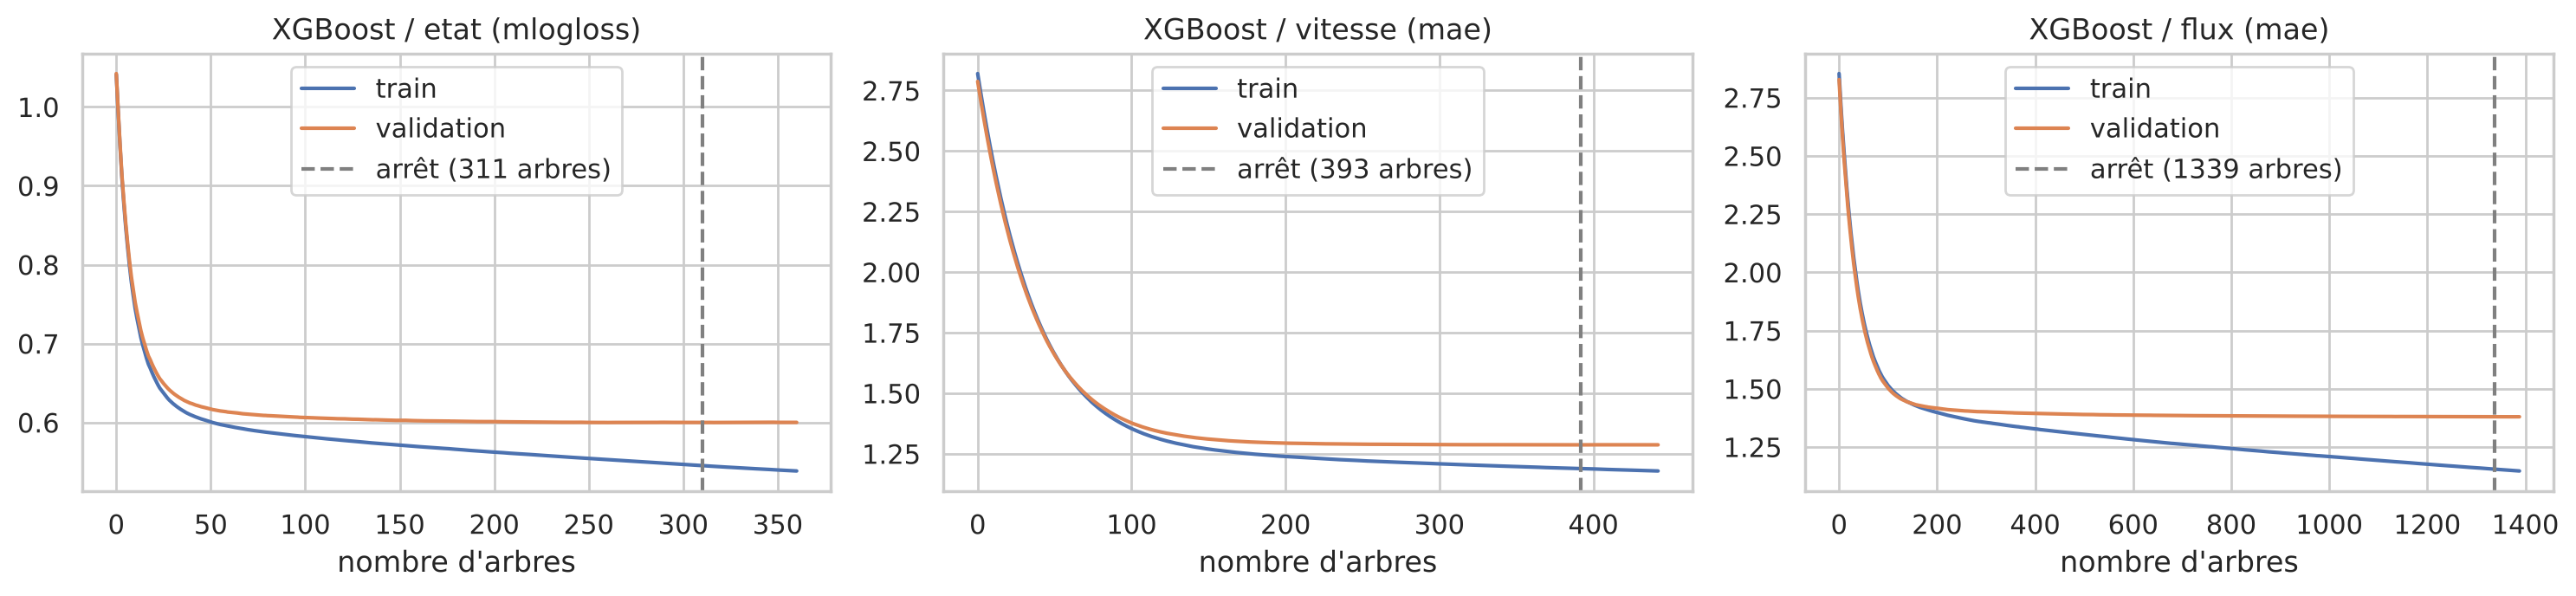

In [48]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, t in zip(ax, TASKS):
    mod = MODELES[(t, "XGBoost")]; h = mod.evals_result()
    cle = list(h["validation_0"].keys())[0]
    a.plot(h["validation_0"][cle], label="train"); a.plot(h["validation_1"][cle], label="validation")
    a.axvline(mod.best_iteration, color="gray", ls="--", label=f"arrêt ({mod.best_iteration + 1} arbres)")
    a.set_title(f"XGBoost / {t} ({cle})"); a.set_xlabel("nombre d'arbres"); a.legend()
plt.tight_layout(); plt.show()

## 5. Comparaison sur la validation

Tous les modèles sont comparés **sur la validation** (choix des hyperparamètres), avec leur temps d'entraînement et leur écart train / validation (indice de surapprentissage).

In [49]:
FAMILLES = ["RandomForest", "XGBoost", "AdaBoost"]
def proba(modele, X):
    return modele.predict_proba(X) if hasattr(modele, "predict_proba") else None

lignes = []
for t in TASKS:
    kind = TASKS[t]["kind"]; crit = "F1_macro" if kind == "clf" else "MAE"
    for f in FAMILLES:
        mod = MODELES[(t, f)]
        (Xa, ya), (Xb, yb) = DATA[t]["train"], DATA[t]["val"]
        mv = metriques(kind, yb, mod.predict(Xb), proba(mod, Xb) if kind == "clf" else None)
        mt = metriques(kind, ya, mod.predict(Xa))
        lignes.append({"tâche": t, "modèle": f, **{f"{k}_val": v for k, v in mv.items()},
                       f"{crit}_train": mt[crit], "écart_train_val": abs(mt[crit] - mv[crit]), "temps_s": TEMPS[(t, f)]})
for (t, n), m in ref_val.items():
    kind = TASKS[t]["kind"]
    lignes.append({"tâche": t, "modèle": f"[réf] {n}", **{f"{k}_val": v for k, v in m.items()}})
comp_val = pd.DataFrame(lignes)

for t in TASKS:
    kind = TASKS[t]["kind"]
    cols = ["modèle"] + (["Accuracy_val", "F1_macro_val", "Rappel_congestionné_val", "AUC_ovr_val"] if kind == "clf" else ["MAE_val", "RMSE_val", "R2_val"]) + ["écart_train_val", "temps_s"]
    print(f"\n=== {t} : {TASKS[t]['nom']} ===")
    print(comp_val[comp_val["tâche"] == t][cols].round(3).to_string(index=False))


=== etat : État du trafic ===
              modèle  Accuracy_val  F1_macro_val  Rappel_congestionné_val  AUC_ovr_val  écart_train_val  temps_s
        RandomForest         0.736         0.737                    0.799        0.895            0.085    6.911
             XGBoost         0.740         0.740                    0.803        0.895            0.023    3.890
            AdaBoost         0.730         0.731                    0.794        0.890            0.008   73.147
   [réf] Persistance         0.693         0.696                    0.757          NaN              NaN      NaN
[réf] Profil cellule         0.709         0.714                    0.718          NaN              NaN      NaN

=== vitesse : Vitesse moyenne (m/s) ===
              modèle  MAE_val  RMSE_val  R2_val  écart_train_val  temps_s
        RandomForest    1.294     1.812   0.724            0.290    6.092
             XGBoost    1.287     1.806   0.726            0.098    3.237
            AdaBoost    1.47

## 6. Évaluation finale sur le **test**

On utilise maintenant le jeu de test, **une seule fois**, avec les modèles retenus sur la validation. Les prédictions sont sauvegardées dans `results/` pour la comparaison finale (partie 5).

In [50]:
resultats, preds = {}, {}
for t in TASKS:
    kind = TASKS[t]["kind"]; Xc, yc = DATA[t]["test"]
    preds[t] = {"y_true": yc.values}
    resultats[t] = {}
    for f in FAMILLES:
        mod = MODELES[(t, f)]
        p = mod.predict(Xc); pr = proba(mod, Xc) if kind == "clf" else None
        resultats[t][f] = {"test": metriques(kind, yc, p, pr),
                           "val": metriques(kind, DATA[t]["val"][1], mod.predict(DATA[t]["val"][0]), proba(mod, DATA[t]["val"][0]) if kind == "clf" else None),
                           "temps_s": TEMPS[(t, f)], "params": {k: (None if v is None else v) for k, v in PARAMS[(t, f)].items()}}
        preds[t][f] = p

rows = []
for t in TASKS:
    crit = "F1_macro" if TASKS[t]["kind"] == "clf" else "MAE"
    for f in FAMILLES:
        r = resultats[t][f]; rows.append({"tâche": t, "modèle": f, f"{crit} val": r["val"][crit], f"{crit} test": r["test"][crit]})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# Sauvegardes pour la partie 5
json.dump(resultats, open("results/ensemble_metrics.json", "w"), indent=2, default=lambda o: float(o) if hasattr(o, "__float__") else str(o))
for t in TASKS:
    pd.DataFrame(preds[t]).to_parquet(f"results/ensemble_preds_{t}.parquet", index=False)
print("\nSauvegardé : results/ensemble_metrics.json et results/ensemble_preds_*.parquet")

  tâche       modèle  F1_macro val  F1_macro test  MAE val  MAE test
   etat RandomForest         0.737          0.730      NaN       NaN
   etat      XGBoost         0.740          0.730      NaN       NaN
   etat     AdaBoost         0.731          0.723      NaN       NaN
vitesse RandomForest           NaN            NaN    1.294     1.285
vitesse      XGBoost           NaN            NaN    1.287     1.280
vitesse     AdaBoost           NaN            NaN    1.475     1.473
   flux RandomForest           NaN            NaN    1.402     1.474
   flux      XGBoost           NaN            NaN    1.380     1.445
   flux     AdaBoost           NaN            NaN    1.602     1.678

Sauvegardé : results/ensemble_metrics.json et results/ensemble_preds_*.parquet


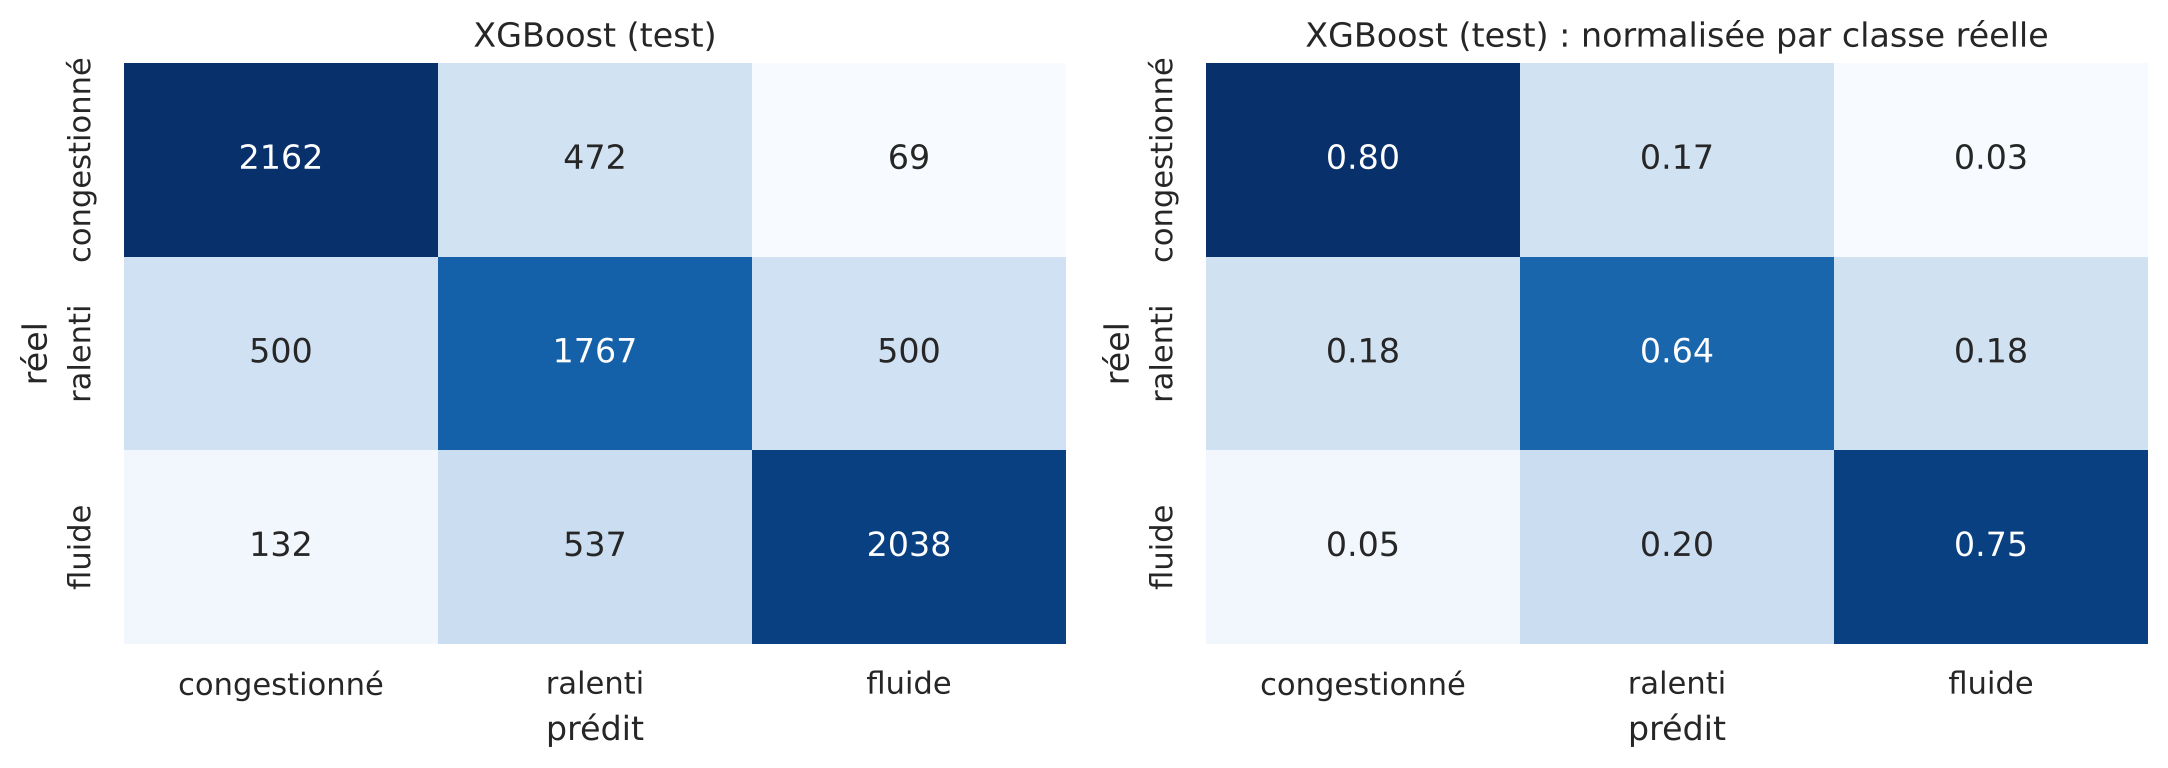

In [51]:
# Détail pour la classification : matrice de confusion du meilleur modèle (test)
t = "etat"; Xc, yc = DATA[t]["test"]
meilleur = max(FAMILLES, key=lambda f: resultats[t][f]["test"]["F1_macro"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, norm in zip(ax, [None, "true"]):
    cm = confusion_matrix(yc, preds[t][meilleur], normalize=norm)
    sns.heatmap(cm, annot=True, fmt=".2f" if norm else "d", cmap="Blues", xticklabels=ETATS, yticklabels=ETATS, ax=a, cbar=False)
    a.set_xlabel("prédit"); a.set_ylabel("réel"); a.set_title(f"{meilleur} (test)" + (" : normalisée par classe réelle" if norm else ""))
plt.tight_layout(); plt.show()

### Variables les plus importantes (tâche `vitesse`)

Deux regards complémentaires :
- **Importance par permutation** (forêt) : de combien l'erreur de validation augmente quand on **mélange** une variable. Elle mesure ce dont le modèle se sert vraiment, pas une cause réelle.
- **Gain** (XGBoost) : la réduction d'erreur apportée par les coupures sur cette variable.

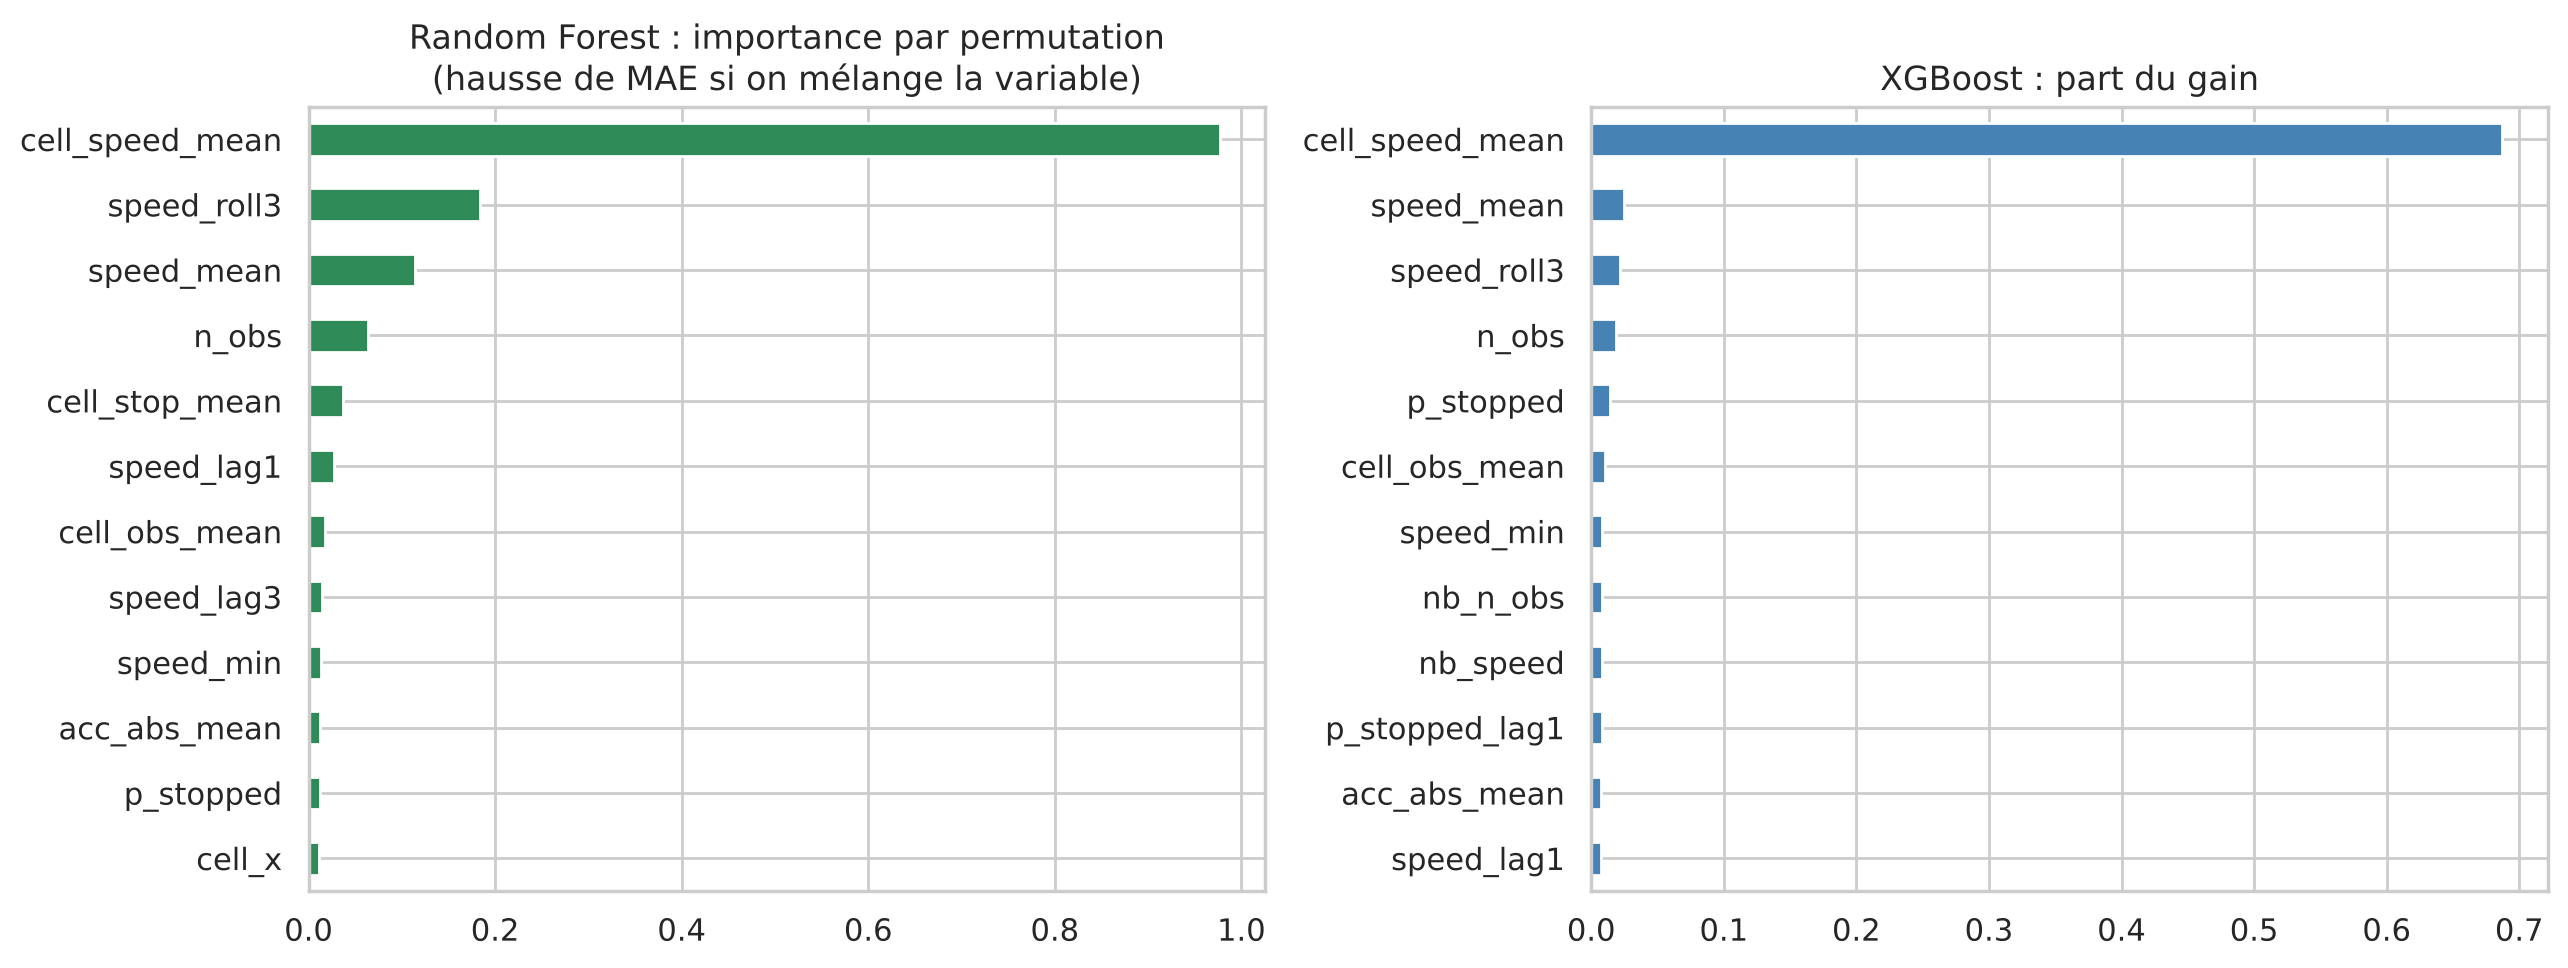

Top 5 forêt  : ['cell_speed_mean', 'speed_roll3', 'speed_mean', 'n_obs', 'cell_stop_mean']
Top 5 XGBoost: ['cell_speed_mean', 'speed_mean', 'speed_roll3', 'n_obs', 'p_stopped']


In [52]:
Xb, yb = DATA["vitesse"]["val"]
perm = permutation_importance(MODELES[("vitesse", "RandomForest")], Xb, yb, n_repeats=3, random_state=SEED, n_jobs=-1,
                              scoring="neg_mean_absolute_error")
imp_rf = pd.Series(perm.importances_mean, index=FEATS).sort_values(ascending=False)
gain = pd.Series(MODELES[("vitesse", "XGBoost")].get_booster().get_score(importance_type="gain")).reindex(FEATS).fillna(0)
imp_xg = (gain / gain.sum()).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
imp_rf.head(12)[::-1].plot.barh(ax=ax[0], color="seagreen"); ax[0].set_title("Random Forest : importance par permutation\n(hausse de MAE si on mélange la variable)")
imp_xg.head(12)[::-1].plot.barh(ax=ax[1], color="steelblue"); ax[1].set_title("XGBoost : part du gain")
plt.tight_layout(); plt.show()
print("Top 5 forêt  :", list(imp_rf.index[:5]))
print("Top 5 XGBoost:", list(imp_xg.index[:5]))

## 7. Analyse : avantages et limites des approches

**Ce que montrent les résultats** (tous les chiffres viennent des cellules ci-dessus ; la validation a servi aux réglages, le test à la mesure finale).

1. **Les modèles d'ensemble battent nettement l'arbre seul.** L'arbre limité à la meilleure profondeur atteint une MAE de vitesse d'environ 1,33 m/s en validation ; non limité, il tombe à 0,33 m/s sur le train mais remonte à 1,72 sur la validation (surapprentissage net). La forêt et XGBoost descendent à environ 1,29 m/s.
2. **Mais l'apport par rapport aux références simples est modeste.** Le profil habituel d'une cellule donne déjà une MAE de vitesse de 1,36 m/s (validation) contre 1,29 pour les meilleurs modèles, et un F1 de 0,71 contre 0,74. Le trafic simulé est largement déterminé par la **géographie** : la variable `cell_speed_mean` domine de très loin l'importance, devant la vitesse récente. Les modèles apportent un gain réel, mais plus faible que ce que laisserait croire un score brut.
3. **Bagging contre Boosting : XGBoost et la forêt sont très proches.** XGBoost est légèrement devant sur la vitesse et le flux (test : 1,280 contre 1,285 m/s, et 1,445 contre 1,474 véhicule) et à égalité sur l'état du trafic (F1 de 0,730 pour les deux). Ces écarts sont petits : la partie 5 teste s'ils dépassent le bruit statistique.
4. **AdaBoost est nettement moins bon** (MAE de vitesse 1,47 contre 1,28) et c'est le plus lent à entraîner. Son poids sur les exemples mal prédits le rend sensible au bruit, et les trafics voisins sont intrinsèquement bruités (arrivées aléatoires, feux). Son écart train / validation est faible : il **sous-apprend**, avec la petite grille d'hyperparamètres explorée ici.
5. **Surapprentissage** : la forêt a le plus grand écart train / validation (0,29 m/s de MAE sur la vitesse) car ses arbres profonds mémorisent le train ; XGBoost, régularisé et arrêté tôt, a un écart plus faible (0,10).

**Avantages et limites**

| | Random Forest (Bagging) | XGBoost (Boosting) | AdaBoost |
|---|---|---|---|
| Précision ici | très bonne | meilleure ou égale | moyenne |
| Hyperparamètres | peu sensibles : de nombreux réglages donnent presque le même score | plus nombreux et plus sensibles, mais l'arrêt anticipé fixe seul le nombre d'arbres | sensible au taux d'apprentissage et à la profondeur |
| Surapprentissage | modéré (grand écart train / val sans effet sur la validation) | contrôlé par la régularisation et l'arrêt anticipé | faible, mais sous-apprentissage |
| Temps d'entraînement | quelques secondes (parallélisable) | quelques secondes avec arrêt anticipé | le plus long (arbres construits en série et recalculs de poids) |
| Robustesse au bruit et aux extrêmes | bonne (moyenne de nombreux arbres) | bonne avec régularisation | faible |
| Interprétabilité | importance par permutation | importance par gain | importance par impureté |

**Limites de cette étude.** (i) La recherche d'hyperparamètres est volontairement **restreinte** (6, 25 et 4 essais) pour un temps de calcul raisonnable ; avec plus d'essais, AdaBoost et la forêt pourraient gagner un peu. (ii) Le jeu de validation sert à la fois à choisir les réglages et à l'arrêt anticipé de XGBoost : le score de validation est donc légèrement optimiste, d'où l'écart observé avec le test pour le flux (1,38 en validation, 1,45 en test). (iii) Les erreurs ne sont pas indépendantes (cellules voisines, minutes consécutives) : c'est pourquoi la partie 5 utilise un bootstrap par blocs de minutes. (iv) Une seule simulation : on ne sait pas si les résultats se généralisent à un autre réseau ou à une autre période de la journée.

---
---
<a id='partie3'></a>

# Partie 3 : Réseaux de neurones artificiels (ANN)

**Projet : Smart Traffic Flow Prediction and Optimization**

Même problème, mêmes jeux et mêmes métriques que la partie 2 : prédire, pour chaque cellule de 100 m et pour la **minute suivante**, l'état du trafic (`etat`), la vitesse moyenne (`vitesse`) et le flux (`flux`). Cela permet une comparaison équitable avec le Bagging et le Boosting (partie 5).

**Plan** : 1. rappels et choix d'architecture · 2. sous-apprentissage, surapprentissage et bon réglage · 3. optimisation des hyperparamètres · 4. évaluation finale · 5. analyse.

## 1. Rappels et choix de conception

**Un réseau de neurones « perceptron multicouche » (MLP)** est une succession de couches. Chaque neurone calcule une somme pondérée de ses entrées, puis applique une **fonction d'activation** non linéaire. L'apprentissage ajuste les poids pour minimiser une **fonction de perte**, par **descente de gradient** (rétropropagation), en parcourant les données par petits groupes (*batchs*) pendant plusieurs passages (*epochs*).

| Élément | Choix retenu | Justification |
|---|---|---|
| Type de réseau | **MLP** (couches denses) | les données sont **tabulaires** : 39 variables par ligne. L'historique (retards, moyennes glissantes) et le voisinage spatial sont déjà résumés par le feature engineering, donc pas besoin de réseau récurrent ni convolutif |
| Entrées | variables **normalisées** (`*_scaled.parquet`) | un réseau est sensible à l'échelle des variables, contrairement aux arbres |
| Couches cachées | 2 à 3 couches de 32 à 256 neurones (à optimiser) | assez de capacité pour des relations non linéaires, sans excès pour 37 000 exemples |
| Activation cachée | **ReLU** (comparée à ELU et tanh) | simple, évite la disparition du gradient |
| Sortie, classification | 3 neurones, **softmax** | probabilité de chaque état |
| Sortie, régression | 1 neurone, **linéaire** | valeur réelle |
| Perte | classification : **entropie croisée** ; régression : **erreur quadratique moyenne (MSE)** | cohérent avec les métriques (F1, RMSE) |
| Optimiseur | **Adam** + réduction du taux d'apprentissage sur plateau | convergence rapide et peu sensible au réglage |
| Régularisation | **Dropout**, pénalité **L2**, **arrêt anticipé** | limiter le surapprentissage |
| Cibles de régression | **standardisées** (moyenne 0, écart-type 1, calculées sur le train) | entraînement plus stable ; on remet à l'échelle pour les métriques |

In [53]:
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import ParameterSampler
print("TensorFlow", tf.__version__)

SCALED = charger("scaled")

def X_y(df, tache):
    d = df.dropna(subset=[tache["target"]])
    y = d[tache["target"]].astype(int) if tache["kind"] == "clf" else d[tache["target"]].astype(float)
    return d[FEATS].values.astype("float32"), y.values

DATA = {t: {s: X_y(df, TASKS[t]) for s, df in zip(SPLITS, SCALED)} for t in TASKS}
STAT = {t: (DATA[t]["train"][1].mean(), DATA[t]["train"][1].std()) for t in TASKS if TASKS[t]["kind"] == "reg"}
print({t: {s: len(DATA[t][s][1]) for s in SPLITS} for t in TASKS})

I0000 00:00:1795164276.639877   30840 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795164278.165993   30840 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0
{'etat': {'train': 36950, 'val': 8180, 'test': 8177}, 'vitesse': {'train': 36950, 'val': 8180, 'test': 8177}, 'flux': {'train': 44873, 'val': 9990, 'test': 10000}}


In [54]:
def construire(n_in, kind, couches=2, unites=64, activation="relu", dropout=0.0, l2=0.0, lr=1e-3):
    """MLP : [Dense -> (Dropout)] x couches, puis couche de sortie."""
    inp = keras.Input((n_in,))
    x = inp
    for _ in range(couches):
        x = layers.Dense(unites, activation=activation, kernel_regularizer=regularizers.l2(l2) if l2 else None)(x)
        if dropout: x = layers.Dropout(dropout)(x)
    if kind == "clf":
        out = layers.Dense(3, activation="softmax")(x)
        model = keras.Model(inp, out)
        model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    else:
        out = layers.Dense(1)(x)
        model = keras.Model(inp, out)
        model.compile(optimizer=keras.optimizers.Adam(lr), loss="mse", metrics=["mae"])
    return model

def cible(tache, y):
    """Cible vue par le réseau : standardisée en régression."""
    if TASKS[tache]["kind"] == "reg":
        mu, sd = STAT[tache]; return ((y - mu) / sd).astype("float32")
    return y

def entrainer(tache, seed=SEED, epochs=80, batch=256, patience=8, arret=True, **arch):
    """Entraîne un MLP. arret=True : arrêt anticipé + réduction du taux d'apprentissage ; False : toutes les epochs."""
    tf.keras.utils.set_random_seed(seed)
    kind = TASKS[tache]["kind"]
    (Xa, ya), (Xb, yb) = DATA[tache]["train"], DATA[tache]["val"]
    model = construire(Xa.shape[1], kind, **arch)
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(2, patience // 2))] if arret else []
    t0 = time.time()
    h = model.fit(Xa, cible(tache, ya), validation_data=(Xb, cible(tache, yb)), epochs=epochs, batch_size=batch,
                  callbacks=cb, verbose=0)
    return model, pd.DataFrame(h.history), time.time() - t0

def predire(model, tache, X):
    p = model.predict(X, verbose=0, batch_size=2048)
    if TASKS[tache]["kind"] == "clf": return p.argmax(1), p
    mu, sd = STAT[tache]; return p.ravel() * sd + mu, None

def evaluer(model, tache, split):
    X, y = DATA[tache][split]
    pred, proba = predire(model, tache, X)
    return metriques(TASKS[tache]["kind"], y, pred, proba)

## 2. Sous-apprentissage, surapprentissage et bon réglage

On entraîne trois réseaux sur la même tâche (`vitesse`) pour voir les trois régimes de la courbe d'apprentissage :

| Réseau | Description | Comportement attendu |
|---|---|---|
| **A, trop simple** | 1 couche de 2 neurones | **sous-apprentissage** : erreur élevée sur train *et* validation |
| **B, trop puissant** | 3 couches de 512 neurones, sans régularisation, sans arrêt, 150 epochs | **surapprentissage** : l'erreur de train descend, celle de validation remonte |
| **C, bien réglé** | 2 couches de 64, dropout, L2, arrêt anticipé | les deux courbes se rejoignent et se stabilisent |

In [55]:
T = "vitesse"
reseaux = {
    "A : trop simple (1x2)":          dict(arch=dict(couches=1, unites=2),  epochs=60,  arret=False),
    "B : trop puissant (3x512)":      dict(arch=dict(couches=3, unites=512, lr=1e-3), epochs=150, arret=False),
    "C : régularisé (2x64, dropout, L2)": dict(arch=dict(couches=2, unites=64, dropout=0.2, l2=1e-4), epochs=100, arret=True),
}
courbes = {}
for nom, cfg in reseaux.items():
    model, hist, tps = entrainer(T, epochs=cfg["epochs"], arret=cfg["arret"], **cfg["arch"])
    courbes[nom] = hist
    mu, sd = STAT[T]
    print(f"{nom:38s} MAE train = {evaluer(model, T, 'train')['MAE']:.3f} | MAE val = {evaluer(model, T, 'val')['MAE']:.3f}  ({len(hist)} epochs, {tps:.0f} s)")

A : trop simple (1x2)                  MAE train = 1.317 | MAE val = 1.323  (60 epochs, 16 s)


B : trop puissant (3x512)              MAE train = 0.355 | MAE val = 1.510  (150 epochs, 219 s)


C : régularisé (2x64, dropout, L2)     MAE train = 1.290 | MAE val = 1.329  (49 epochs, 21 s)


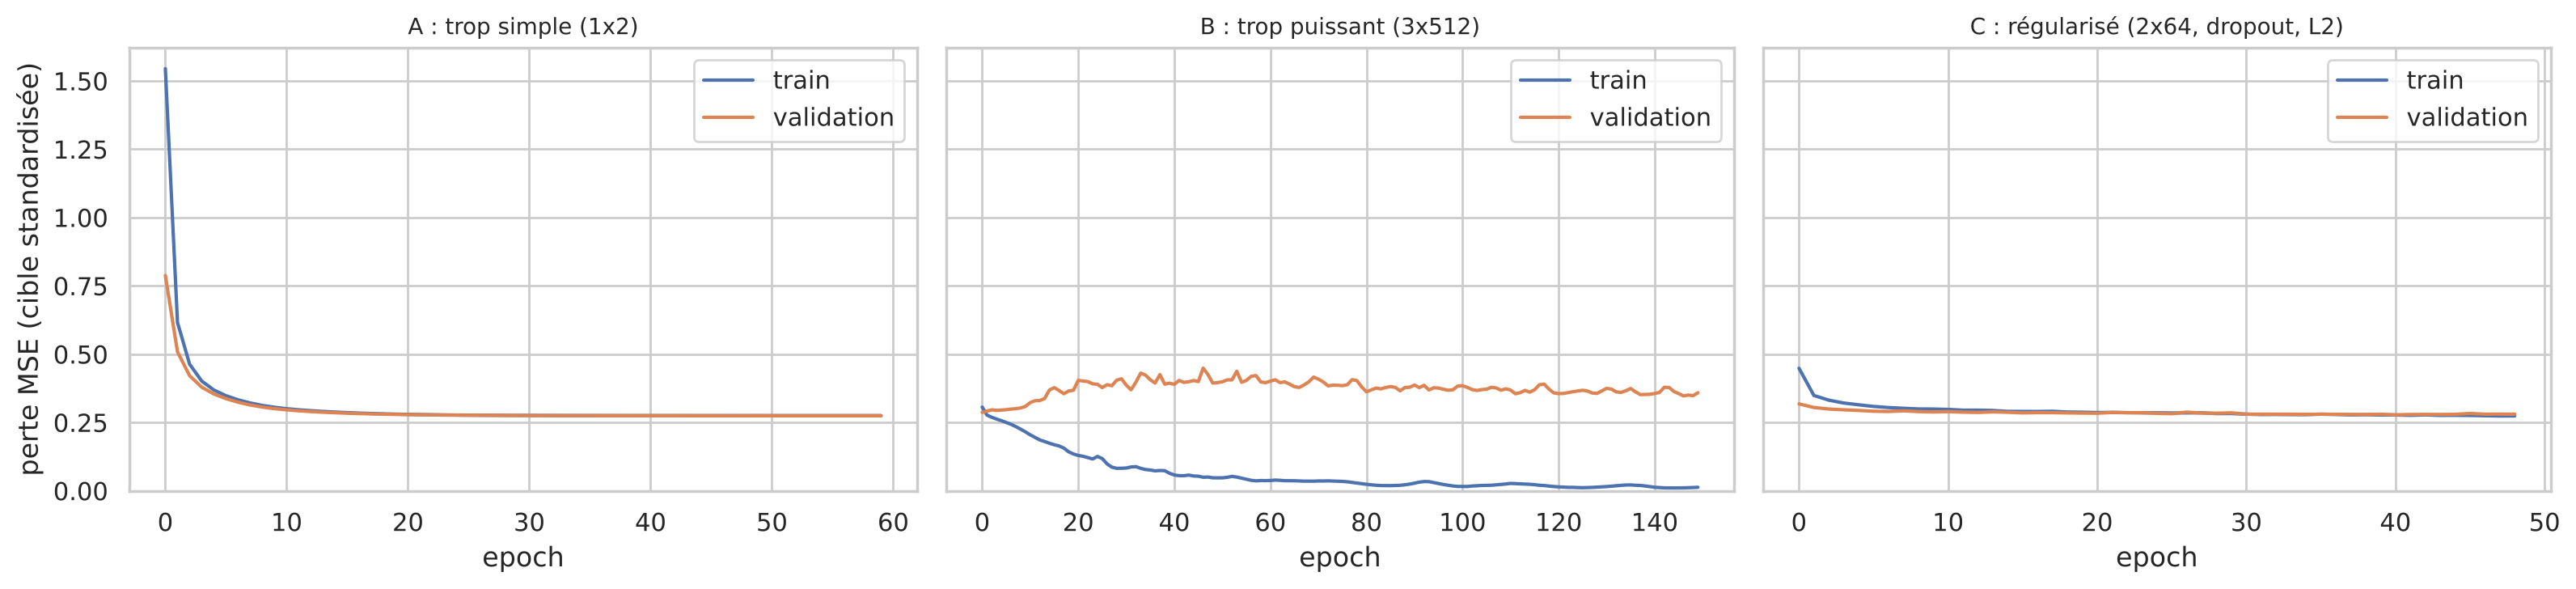

In [56]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for a, (nom, h) in zip(ax, courbes.items()):
    a.plot(h["loss"], label="train"); a.plot(h["val_loss"], label="validation")
    a.set_title(nom, fontsize=10); a.set_xlabel("epoch"); a.legend()
ax[0].set_ylabel("perte MSE (cible standardisée)"); ax[0].set_ylim(0, None)
plt.tight_layout(); plt.show()

**Lecture.** Le réseau A n'a pas assez de capacité : les deux erreurs restent hautes (**sous-apprentissage**, biais élevé). Le réseau B mémorise le train : sa perte d'entraînement continue de baisser pendant que la perte de validation **remonte** (**surapprentissage**, variance élevée). Le réseau C, avec dropout, pénalité L2 et arrêt anticipé, garde les deux courbes proches. C'est ce type de réglage que l'on optimise ensuite.

## 3. Optimisation des hyperparamètres

Recherche aléatoire sur la validation, pour chacune des trois tâches. Hyperparamètres : nombre de couches, neurones par couche, activation, dropout, pénalité L2, taux d'apprentissage, taille de batch. Le critère est le même que pour les arbres (MAE en régression, 1 − F1 macro en classification).

In [57]:
ESPACE = {"couches": [2, 3], "unites": [32, 64, 128, 256], "activation": ["relu", "elu", "tanh"],
          "dropout": [0.0, 0.1, 0.2, 0.3], "l2": [0.0, 1e-5, 1e-4, 1e-3], "lr": [3e-4, 1e-3, 3e-3]}
BATCHS = [128, 256, 512]
N_ESSAIS = 6

RECH, MODELES = {}, {}
for t in TASKS:
    kind = TASKS[t]["kind"]; Xb, yb = DATA[t]["val"]
    lignes, meilleur = [], (np.inf, None, None)
    for i, p in enumerate(ParameterSampler(ESPACE, N_ESSAIS, random_state=SEED)):
        batch = BATCHS[i % len(BATCHS)]
        model, hist, tps = entrainer(t, epochs=60, batch=batch, patience=8, **p)
        pred, _ = predire(model, t, Xb)
        sc = perte(kind, yb, pred)
        lignes.append({**p, "batch": batch, "epochs": len(hist), "perte_val": sc, "temps_s": tps})
        if sc < meilleur[0]: meilleur = (sc, {**p, "batch": batch}, i)
        keras.backend.clear_session()
    RECH[t] = pd.DataFrame(lignes).sort_values("perte_val").reset_index(drop=True)
    MODELES[t] = meilleur[1]
    print(f"\n=== {t} : essais classés (perte = {'1 - F1 macro' if kind == 'clf' else 'MAE'}) ===")
    print(RECH[t].round(4).to_string(index=False))


=== etat : essais classés (perte = 1 - F1 macro) ===
 unites     lr     l2  dropout  couches activation  batch  epochs  perte_val  temps_s
    128 0.0030 0.0000      0.3        3       tanh    128      60     0.2661  58.9170
     32 0.0030 0.0010      0.1        2       tanh    256      60     0.2697  22.6644
     64 0.0003 0.0001      0.2        2       relu    512      60     0.2699  17.4538
     32 0.0003 0.0010      0.1        3       tanh    256      60     0.2721  26.7219
    256 0.0003 0.0010      0.2        3       tanh    128      60     0.2733  74.1208
    128 0.0003 0.0001      0.3        3       tanh    512      60     0.2737  26.1389



=== vitesse : essais classés (perte = MAE) ===
 unites     lr     l2  dropout  couches activation  batch  epochs  perte_val  temps_s
    128 0.0030 0.0000      0.3        3       tanh    128      31     1.3183  27.0290
    256 0.0003 0.0010      0.2        3       tanh    128      60     1.3207  72.7543
     32 0.0003 0.0010      0.1        3       tanh    256      60     1.3248  25.6342
     32 0.0030 0.0010      0.1        2       tanh    256      40     1.3324  14.1578
    128 0.0003 0.0001      0.3        3       tanh    512      60     1.3329  27.3017
     64 0.0003 0.0001      0.2        2       relu    512      60     1.3684  16.5655



=== flux : essais classés (perte = MAE) ===
 unites     lr     l2  dropout  couches activation  batch  epochs  perte_val  temps_s
    128 0.0030 0.0000      0.3        3       tanh    128      60     1.3927  61.2722
    128 0.0003 0.0001      0.3        3       tanh    512      60     1.4460  29.0616
     32 0.0030 0.0010      0.1        2       tanh    256      32     1.4502  14.8761
     32 0.0003 0.0010      0.1        3       tanh    256      60     1.4622  27.2630
    256 0.0003 0.0010      0.2        3       tanh    128      60     1.4649 104.8996
     64 0.0003 0.0001      0.2        2       relu    512      46     1.4895  14.7913


### Sensibilité aux hyperparamètres

Sur ces essais, quelles tendances voit-on ? (Le nombre d'essais est volontairement petit, pour un temps de calcul raisonnable : les tendances sont indicatives.)

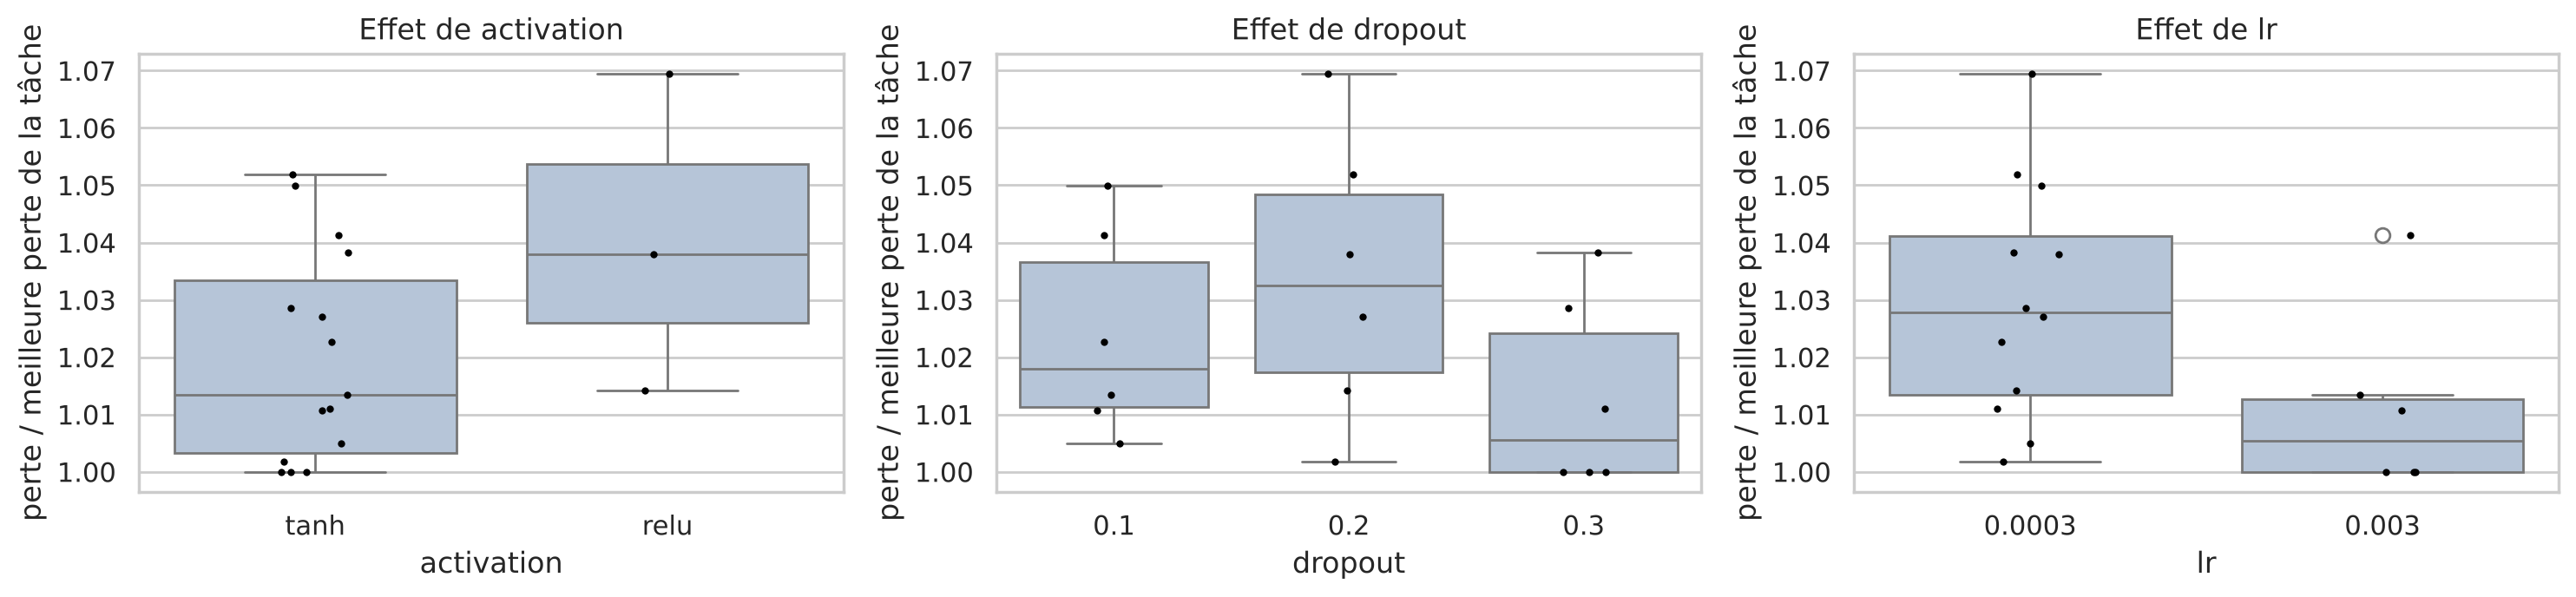

activation
relu    1.041
tanh    1.020


In [58]:
tous = pd.concat([RECH[t].assign(tache=t) for t in TASKS])
# Perte relative au meilleur essai de chaque tâche, pour pouvoir comparer des tâches différentes
tous["perte_relative"] = tous["perte_val"] / tous.groupby("tache")["perte_val"].transform("min")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, col in zip(ax, ["activation", "dropout", "lr"]):
    sns.boxplot(data=tous, x=col, y="perte_relative", ax=a, color="lightsteelblue")
    sns.stripplot(data=tous, x=col, y="perte_relative", ax=a, color="black", size=3)
    a.set_title(f"Effet de {col}"); a.set_ylabel("perte / meilleure perte de la tâche")
plt.tight_layout(); plt.show()
print(tous.groupby("activation")["perte_relative"].mean().round(3).to_string())

## 4. Évaluation finale

Les meilleurs réglages sont ré-entraînés avec **3 graines aléatoires** (un réseau dépend de l'initialisation des poids : on mesure donc la variabilité). Les métriques de la graine 42 sont utilisées pour la comparaison, avec les prédictions sauvegardées pour la partie 5. Le test n'est utilisé qu'ici.

In [59]:
SEEDS = [42, 43, 44]
FINAL, TEMPS, preds, courbes_finales = {}, {}, {}, {}
for t in TASKS:
    kind = TASKS[t]["kind"]; p = dict(MODELES[t]); batch = p.pop("batch")
    essais = []
    for sd in SEEDS:
        model, hist, tps = entrainer(t, seed=sd, epochs=100, batch=batch, patience=10, **p)
        essais.append({"seed": sd, "val": evaluer(model, t, "val"), "test": evaluer(model, t, "test"), "epochs": len(hist)})
        if sd == SEEDS[0]:
            Xc, yc = DATA[t]["test"]
            preds[t] = {"y_true": yc, "ANN": predire(model, t, Xc)[0]}
            courbes_finales[t] = hist; TEMPS[t] = tps
        keras.backend.clear_session()
    FINAL[t] = {"params": MODELES[t], "essais": essais}

crit = {"etat": "F1_macro", "vitesse": "MAE", "flux": "MAE"}
rows = []
for t in TASKS:
    v = [e["val"][crit[t]] for e in FINAL[t]["essais"]]; te = [e["test"][crit[t]] for e in FINAL[t]["essais"]]
    rows.append({"tâche": t, "critère": crit[t], "val (graine 42)": v[0], "test (graine 42)": te[0],
                 "test moyenne 3 graines": np.mean(te), "test écart-type": np.std(te)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

  tâche  critère  val (graine 42)  test (graine 42)  test moyenne 3 graines  test écart-type
   etat F1_macro            0.733             0.731                   0.727            0.005
vitesse      MAE            1.314             1.312                   1.302            0.009
   flux      MAE            1.394             1.460                   1.460            0.002


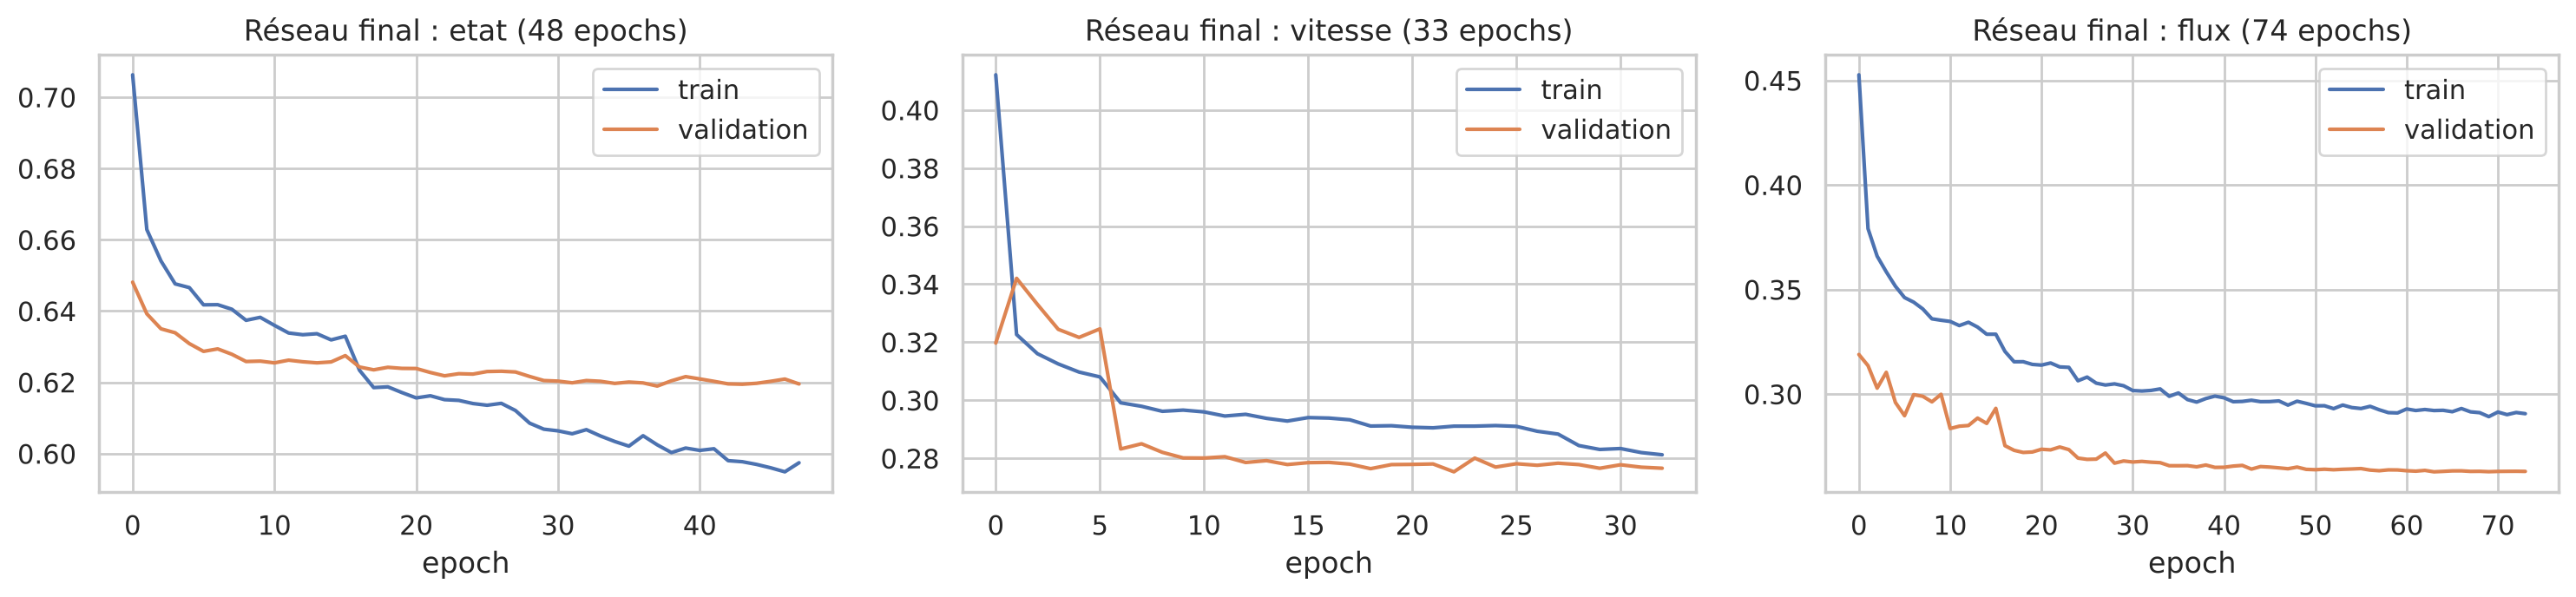

In [60]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, t in zip(ax, TASKS):
    h = courbes_finales[t]
    a.plot(h["loss"], label="train"); a.plot(h["val_loss"], label="validation")
    a.set_title(f"Réseau final : {t} ({len(h)} epochs)"); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

In [61]:
# Sauvegardes pour la partie 5 (même structure que la partie 2)
resultats = {t: {"ANN": {"test": FINAL[t]["essais"][0]["test"], "val": FINAL[t]["essais"][0]["val"], "temps_s": TEMPS[t],
                         "params": FINAL[t]["params"],
                         "test_3_graines": {crit[t]: [e["test"][crit[t]] for e in FINAL[t]["essais"]]}}} for t in TASKS}
json.dump(resultats, open("results/ann_metrics.json", "w"), indent=2, default=lambda o: float(o) if hasattr(o, "__float__") else str(o))
for t in TASKS:
    pd.DataFrame(preds[t]).to_parquet(f"results/ann_preds_{t}.parquet", index=False)
print("Sauvegardé : results/ann_metrics.json et results/ann_preds_*.parquet")

Sauvegardé : results/ann_metrics.json et results/ann_preds_*.parquet


## 5. Analyse

### Ce que montrent les courbes d'apprentissage
- **Réseau A (1×2)** : les deux courbes se superposent et plafonnent haut (MAE vitesse 1,317 en train, 1,323 en validation). Le modèle est trop pauvre pour apprendre la structure : c'est du **sous-apprentissage**.
- **Réseau B (3×512, sans régularisation)** : l'erreur de train s'effondre (MAE 0,355) alors que celle de validation remonte dès les premières epochs (MAE 1,510). Le réseau mémorise les fenêtres d'entraînement : c'est du **surapprentissage**, et c'est aussi le plus lent à entraîner (212 s contre 22 s pour C).
- **Réseau C (2×64, dropout, L2, arrêt anticipé)** : train et validation se rejoignent (1,290 / 1,329) ; l'arrêt anticipé coupe l'entraînement à 49 epochs. C'est le bon régime : la validation n'est pas spectaculairement meilleure que celle de A (1,329 contre 1,323 en MAE), car les variables explicatives limitent déjà la performance, mais le modèle ne dérive pas.

### Hyperparamètres (6 essais par tâche, tendances indicatives)
- Les meilleurs réglages sont les mêmes pour les trois tâches : **3 couches, 128 neurones, tanh, dropout 0,3, pas d'apprentissage 3·10⁻³**. Sur la validation, les écarts entre bons essais sont petits (par exemple perte 0,266 à 0,274 pour l'état), signe que la performance est surtout limitée par l'information contenue dans les variables, pas par le réglage.
- Le **tanh** fait légèrement mieux que le **ReLU** (perte relative moyenne 1,020 contre 1,041) ; le seul essai en ReLU est aussi le moins bon pour la vitesse et le flux. Avec seulement 6 essais, on ne peut pas conclure de façon ferme.
- Les deux essais avec un pas d'apprentissage de 3·10⁻³ figurent parmi les 4 premiers pour chacune des trois tâches, et le meilleur de chaque tâche en fait partie : avec un entraînement limité à 60 epochs, un pas plus élevé converge mieux. Le nombre d'essais reste trop petit pour une conclusion ferme.

### Performance finale (test, moyenne de 3 graines)
| Tâche | Critère | Graine 42 | Moyenne 3 graines | Écart-type |
|---|---|---|---|---|
| État | F1 macro | 0,731 | 0,727 | 0,005 |
| Vitesse | MAE | 1,312 | 1,302 | 0,009 |
| Flux | MAE | 1,460 | 1,460 | 0,002 |

- L'**écart-type entre graines est faible** (inférieur à 0,01) : le résultat ne dépend pas d'un coup de chance sur l'initialisation.
- Les courbes finales : pour la vitesse et le flux, la perte de validation reste sous celle d'entraînement (effet du dropout, actif seulement à l'entraînement), sans remontée. Pour l'état, un petit écart apparaît (validation autour de 0,62 contre 0,60 en train) : léger début de surapprentissage, contenu par l'arrêt anticipé.
- **Comparaison avec les ensembles** (partie 2) : le réseau est au niveau de Random Forest et XGBoost sur l'état (F1 0,731 contre 0,730 pour les deux), un peu moins bon sur la vitesse (MAE 1,312 contre 1,285 pour RF et 1,280 pour XGBoost) et sur le flux (1,460 contre 1,474 pour RF et 1,445 pour XGBoost). La différence est de l'ordre de 2 % : **sur ces données tabulaires de taille moyenne (environ 37 000 lignes), le réseau n'apporte pas de gain par rapport au boosting**, mais coûte plus cher à régler et plus lent à entraîner (31 à 78 s contre 4 à 7 s).
- La classe **« ralenti »** (classe intermédiaire) reste la plus difficile (rappel 0,62), comme pour les ensembles : ses frontières avec « fluide » et « congestionné » sont floues, puisque les classes viennent de seuils (quantiles) sur une vitesse continue.

---
---
<a id='partie4'></a>

# Partie 4 (bonus) : Reinforcement Learning, régulation d'un carrefour à feux

**Projet : Smart Traffic Flow Prediction and Optimization**

Les parties 2 et 3 **prédisent** le trafic. Ici, on s'intéresse à l'**optimisation** : comment **décider** (quand passer un feu au vert) pour réduire l'attente des véhicules ? C'est un problème de **décision séquentielle** : chaque décision change l'état futur (les files), ce qui est exactement le cadre du Reinforcement Learning.

**Le dataset ne contient ni feux ni décisions.** L'énoncé autorise un environnement **simulé** : on construit donc un simulateur de carrefour, mais on l'**alimente avec les flux réels** observés dans les cellules les plus chargées du réseau (export de la partie 1, `rl_flux_axes.parquet`). Les hypothèses du simulateur qui ne viennent pas des données sont indiquées clairement.

**Plan** : 1. données réelles et hypothèses · 2. environnement (états, actions, récompense) · 3. politiques de référence · 4. agent Q-learning · 5. évaluation sur scénarios réels et synthétiques · 6. analyse.

In [62]:
T1, T2, W = META["T1"], META["T2"], META["n_fenetres"]
flux = pd.read_parquet("data_prepared/rl_flux_axes.parquet")
CELLULES = sorted(flux.cell_id.unique())
A0 = flux.pivot(index="w", columns="cell_id", values="n_axe0").reindex(columns=CELLULES)      # véhicules / minute, axe 0
A1 = flux.pivot(index="w", columns="cell_id", values="n_axe1").reindex(columns=CELLULES)      # véhicules / minute, axe 1
print(f"{len(CELLULES)} cellules, {len(A0)} minutes. Train : minutes < {T1}, validation : {T1}-{T2}, test : > {T2}")
flux.groupby("cell_id")[["n_axe0", "n_axe1"]].agg(["mean", lambda s: s.quantile(.95)]).round(1).set_axis(
    ["axe0 moyenne", "axe0 pic (p95)", "axe1 moyenne", "axe1 pic (p95)"], axis=1)

5 cellules, 394 minutes. Train : minutes < 275, validation : 275-334, test : > 334


,axe0 moyenne,axe0 pic (p95),axe1 moyenne,axe1 pic (p95)
cell_id,,,,
27,2.9,6.0,6.5,11.0
42,3.2,6.0,13.3,17.3
75,12.1,20.0,8.0,15.0
93,11.2,18.0,11.1,19.0
112,6.8,15.0,1.6,5.0


## 1. Données réelles et hypothèses

**Ce qui vient des données.** Pour les 5 cellules les plus chargées, le nombre de véhicules par minute sur chacun des **deux axes** de circulation (les deux familles de routes du damier). Ces cellules sont d'ailleurs lentes : la vitesse moyenne y est de 0,7 à 2,4 m/s, ce sont de vrais points de congestion. On les traite comme des **carrefours** à deux phases.

**Ce qui est supposé** (le dataset ne le contient pas) :

| Hypothèse | Valeur | Justification |
|---|---|---|
| Flux de saturation (véhicules écoulés par seconde au vert) | 0,5 véh/s (1 800 véh/h) | valeur classique d'une voie urbaine |
| Temps perdu à chaque changement de phase (orange + dégagement) | 3 s | ordre de grandeur usuel |
| Vert minimal | 10 s | sécurité / confort |
| Arrivées | loi de Poisson dont la moyenne suit les flux réels par minute | processus d'arrivée standard |

**Découpage** : l'agent apprend sur les minutes du **train**, les réglages (pas de temps du feu fixe, paramètres de l'heuristique, choix de la meilleure politique apprise) se font sur la **validation**, et l'évaluation finale utilise les minutes du **test** (période de simulation postérieure, jamais vue).

## 2. L'environnement : états, actions, récompense

| Élément | Définition |
|---|---|
| **Carrefour** | 2 axes (0 et 1) ; un seul axe est au vert à la fois |
| **État observé** | longueur de la file de chaque axe (discrétisée en 8 classes), phase en cours (quel axe est au vert), temps écoulé depuis le dernier changement (3 classes) : 8 × 8 × 2 × 3 = **384 états** |
| **Actions** | `0` = garder la phase ; `1` = changer de phase (refusé si le vert minimal n'est pas écoulé) |
| **Pas de décision** | 5 secondes (la simulation avance seconde par seconde) |
| **Récompense** | `−(nombre de véhicules en attente, cumulé sur le pas) / 50` : minimiser l'attente totale revient à minimiser le retard moyen (loi de Little) |
| **Épisode** | 15 minutes (900 s), soit 180 décisions, avec les flux réels de 15 minutes consécutives |
| **Dynamique** | arrivées de Poisson ; à chaque seconde, si l'axe au vert a une file non vide et hors temps perdu, un véhicule est écoulé avec la probabilité 0,5 |

In [63]:
class Carrefour:
    """Carrefour à 2 phases. Simulation à la seconde, décision toutes les DT secondes."""
    DT, MIN_GREEN, LOST, QMAX = 5, 10, 3, 80
    BORNES = [0, 1, 2, 4, 7, 11, 17, 26]                    # 8 classes de longueur de file
    N_ETATS, N_ACTIONS = 8 * 8 * 2 * 3, 2

    def __init__(self, saturation=0.5):
        self.S = saturation

    def reset(self, lam0, lam1, seed, horizon=900):
        """lam0, lam1 : arrivées (véhicules / minute), une valeur par minute de l'épisode."""
        rng = np.random.default_rng(seed)
        minute = np.arange(horizon) // 60
        self.arr = [rng.poisson(np.asarray(lam0, float)[minute] / 60), rng.poisson(np.asarray(lam1, float)[minute] / 60)]
        self.srv = rng.random(horizon) < self.S
        self.H, self.t = horizon, 0
        self.q, self.phase, self.tp, self.lost = [0, 0], 0, self.MIN_GREEN, 0
        self.wait = self.served = self.arrived = self.switches = self.qmax = 0
        return self.etat()

    def etat(self):
        tb = 0 if self.tp < self.MIN_GREEN else (1 if self.tp < 25 else 2)
        return ((self.CLASSE[self.q[0]] * 8 + self.CLASSE[self.q[1]]) * 2 + self.phase) * 3 + tb

    def step(self, action):
        if action == 1 and self.tp >= self.MIN_GREEN:        # changement de phase : temps perdu, plus personne ne passe
            self.phase ^= 1; self.tp = 0; self.lost = self.LOST; self.switches += 1
        somme = 0
        for _ in range(self.DT):
            t = self.t
            for k in (0, 1):
                a = int(self.arr[k][t]); self.arrived += a
                self.q[k] = min(self.QMAX, self.q[k] + a)
            if self.lost > 0:
                self.lost -= 1
            elif self.q[self.phase] > 0 and self.srv[t]:
                self.q[self.phase] -= 1; self.served += 1
            self.tp += 1; self.t += 1
            tot = self.q[0] + self.q[1]; somme += tot; self.qmax = max(self.qmax, tot)
        self.wait += somme
        return self.etat(), -somme / 50.0, self.t >= self.H

    def bilan(self):
        return {"retard_s_par_veh": self.wait / max(1, self.arrived), "file_moyenne": self.wait / self.H,
                "debit_veh_h": self.served / self.H * 3600, "file_max": self.qmax, "changements_h": self.switches / self.H * 3600}

Carrefour.CLASSE = [int(np.searchsorted(Carrefour.BORNES, q, side="right") - 1) for q in range(Carrefour.QMAX + 1)]   # longueur de file -> classe

## 3. Politiques de référence

Un agent appris n'a de valeur que s'il bat des **règles simples**. On en teste quatre :

- **Aléatoire** : change de phase au hasard (borne basse).
- **Temps fixe** : change de phase toutes les `G` secondes, quel que soit le trafic (c'est ce que font beaucoup de feux réels). On teste `G = 30 s` puis la meilleure valeur sur la validation.
- **Plus longue file** : change de phase quand la file de l'axe en rouge dépasse celle de l'axe vert d'une marge `m` (ou quand le vert est vide), avec la marge `m` choisie sur la validation. C'est une heuristique **réactive**, souvent très difficile à battre.

In [64]:
def pol_aleatoire(seed=0):
    rng = np.random.default_rng(seed)
    return lambda env: int(rng.random() < 0.1)

def pol_fixe(G):
    return lambda env: int(env.tp >= G)

def pol_longue_file(marge):
    def pol(env):
        v, r = env.q[env.phase], env.q[1 - env.phase]
        return int(env.tp >= env.MIN_GREEN and (r > v + marge or (v == 0 and r > 0)))
    return pol

def jouer(politique, lam0, lam1, seed, saturation=0.5):
    env = Carrefour(saturation); env.reset(lam0, lam1, seed)
    done = False
    while not done:
        _, _, done = env.step(politique(env))
    return env.bilan()

## 4. Agent : Q-learning tabulaire

**Principe** (guide Q-learning du cours). L'agent apprend une table `Q(état, action)` = « récompense future attendue si je fais cette action dans cet état ». À chaque transition `(s, a, r, s')` :

`Q(s, a) ← Q(s, a) + α · ( r + γ · max Q(s', ·) − Q(s, a) )`

- **ε-greedy** : avec une probabilité `ε` on explore (action au hasard), sinon on exploite (meilleure action connue). `ε` décroît de 1 à 0,05.
- `α` = taux d'apprentissage (décroît de 0,2 à 0,03), `γ` = 0,97 (les conséquences d'un changement de phase se voient sur plusieurs décisions).

**Pourquoi Q-learning ?** L'espace d'états est **petit et discret** (384 états), l'algorithme est celui vu en cours, et la table apprise est **lisible** (on peut visualiser la règle de décision). Ses limites (pas de généralisation entre états, ne passe pas à l'échelle d'un réseau entier) sont discutées dans l'analyse.

**Entraînement** : à chaque épisode on tire au hasard une des 5 cellules et un créneau de 15 minutes **dans la période de train** ; l'agent subit donc des profils de demande réels et variés. Toutes les 400 épisodes on évalue la politique gloutonne sur la **validation** et on garde la meilleure table.

In [65]:
DUREE = 15                                                  # minutes par épisode

def segment(periode, cell, rng):
    lo, hi = {"train": (10, T1), "val": (T1 + 1, T2), "test": (T2 + 1, W - 1)}[periode]
    w0 = int(rng.integers(lo, hi - DUREE + 1))
    return A0[cell].values[w0:w0 + DUREE], A1[cell].values[w0:w0 + DUREE], w0

def scenarios_reels(periode):
    """Créneaux consécutifs de 15 minutes de chaque cellule, dans la période choisie."""
    lo, hi = {"val": (T1 + 1, T2), "test": (T2 + 1, W - 1)}[periode]
    out = []
    for c in CELLULES:
        for w0 in range(lo, hi - DUREE + 1, DUREE):
            out.append({"nom": f"cellule {c} / min {w0}", "cell": c, "lam0": A0[c].values[w0:w0 + DUREE], "lam1": A1[c].values[w0:w0 + DUREE]})
    return out

def evaluer(politique_factory, scens, n_seeds=4, saturation=0.5):
    """Retard moyen sur tous les scénarios x graines (mêmes aléas pour toutes les politiques : comparaison appariée)."""
    res = []
    for i, s in enumerate(scens):
        for k in range(n_seeds):
            res.append({"scenario": s["nom"], "graine": k, **jouer(politique_factory(), s["lam0"], s["lam1"], 1000 * i + k, saturation)})
    return pd.DataFrame(res)

def entrainer_q(n_episodes=30000, seed=SEED, alpha=(0.1, 0.01), gamma=0.97, eps=(1.0, 0.05), verbose=True):
    rng = np.random.default_rng(seed)
    Q = np.zeros((Carrefour.N_ETATS, Carrefour.N_ACTIONS)); visites = np.zeros(Carrefour.N_ETATS)
    env = Carrefour()
    val = scenarios_reels("val")
    meilleur, Q_best, journal, journal_val = np.inf, Q.copy(), [], []
    for ep in range(n_episodes):
        frac = ep / n_episodes
        e = max(eps[1], eps[0] - (eps[0] - eps[1]) * frac / 0.7)
        a_ = alpha[0] + (alpha[1] - alpha[0]) * frac
        cell = CELLULES[int(rng.integers(len(CELLULES)))]
        l0, l1, _ = segment("train", cell, rng)
        s = env.reset(l0, l1, int(rng.integers(1 << 30)))
        retour, done = 0.0, False
        while not done:
            a = int(rng.integers(2)) if rng.random() < e else int(Q[s].argmax())
            s2, r, done = env.step(a)
            visites[s] += 1
            Q[s, a] += a_ * (r + (0 if done else gamma * Q[s2].max()) - Q[s, a])
            s, retour = s2, retour + r
        journal.append(retour)
        if (ep + 1) % 1000 == 0:
            q_pol = lambda env_, Q=Q: int(Q[env_.etat()].argmax())
            d = evaluer(lambda: q_pol, val, n_seeds=3).retard_s_par_veh.mean()
            journal_val.append((ep + 1, d))
            if d < meilleur: meilleur, Q_best = d, Q.copy()
            if verbose and (ep + 1) % 5000 == 0: print(f"  épisode {ep + 1:5d} | ε = {e:.2f} | retard validation = {d:.2f} s/véh (meilleur : {meilleur:.2f})")
    return Q_best, np.array(journal), journal_val, meilleur, visites

# Le Q-learning dépend du hasard (exploration, tirage des épisodes) : on entraîne 5 agents de graines différentes
# et on garde celui qui a le meilleur retard sur la VALIDATION (le test reste intact).
AGENTS = []
t0 = time.time()
for sd in range(5):
    Qs, ret_s, jv_s, score_val, vis = entrainer_q(seed=SEED + sd, verbose=(sd == 0))
    AGENTS.append({"seed": SEED + sd, "Q": Qs, "retours": ret_s, "journal_val": jv_s, "retard_val": score_val, "visites": vis})
    print(f"agent {sd} (graine {SEED + sd}) : meilleur retard validation = {score_val:.2f} s/véh")
print(f"Entraînement terminé en {time.time() - t0:.0f} s")
CHOIX = int(np.argmin([a["retard_val"] for a in AGENTS]))
Q, retours, journal_val, VISITES = AGENTS[CHOIX]["Q"], AGENTS[CHOIX]["retours"], AGENTS[CHOIX]["journal_val"], AGENTS[CHOIX]["visites"]
print(f"Agent retenu (validation) : n°{CHOIX}")

  épisode  5000 | ε = 0.77 | retard validation = 10.91 s/véh (meilleur : 10.06)


  épisode 10000 | ε = 0.55 | retard validation = 9.91 s/véh (meilleur : 9.91)


  épisode 15000 | ε = 0.32 | retard validation = 10.45 s/véh (meilleur : 9.91)


  épisode 20000 | ε = 0.10 | retard validation = 9.97 s/véh (meilleur : 9.91)


  épisode 25000 | ε = 0.05 | retard validation = 9.80 s/véh (meilleur : 9.80)


  épisode 30000 | ε = 0.05 | retard validation = 9.91 s/véh (meilleur : 9.80)
agent 0 (graine 42) : meilleur retard validation = 9.80 s/véh


agent 1 (graine 43) : meilleur retard validation = 9.77 s/véh


agent 2 (graine 44) : meilleur retard validation = 9.81 s/véh


agent 3 (graine 45) : meilleur retard validation = 9.84 s/véh


agent 4 (graine 46) : meilleur retard validation = 9.81 s/véh
Entraînement terminé en 210 s
Agent retenu (validation) : n°1


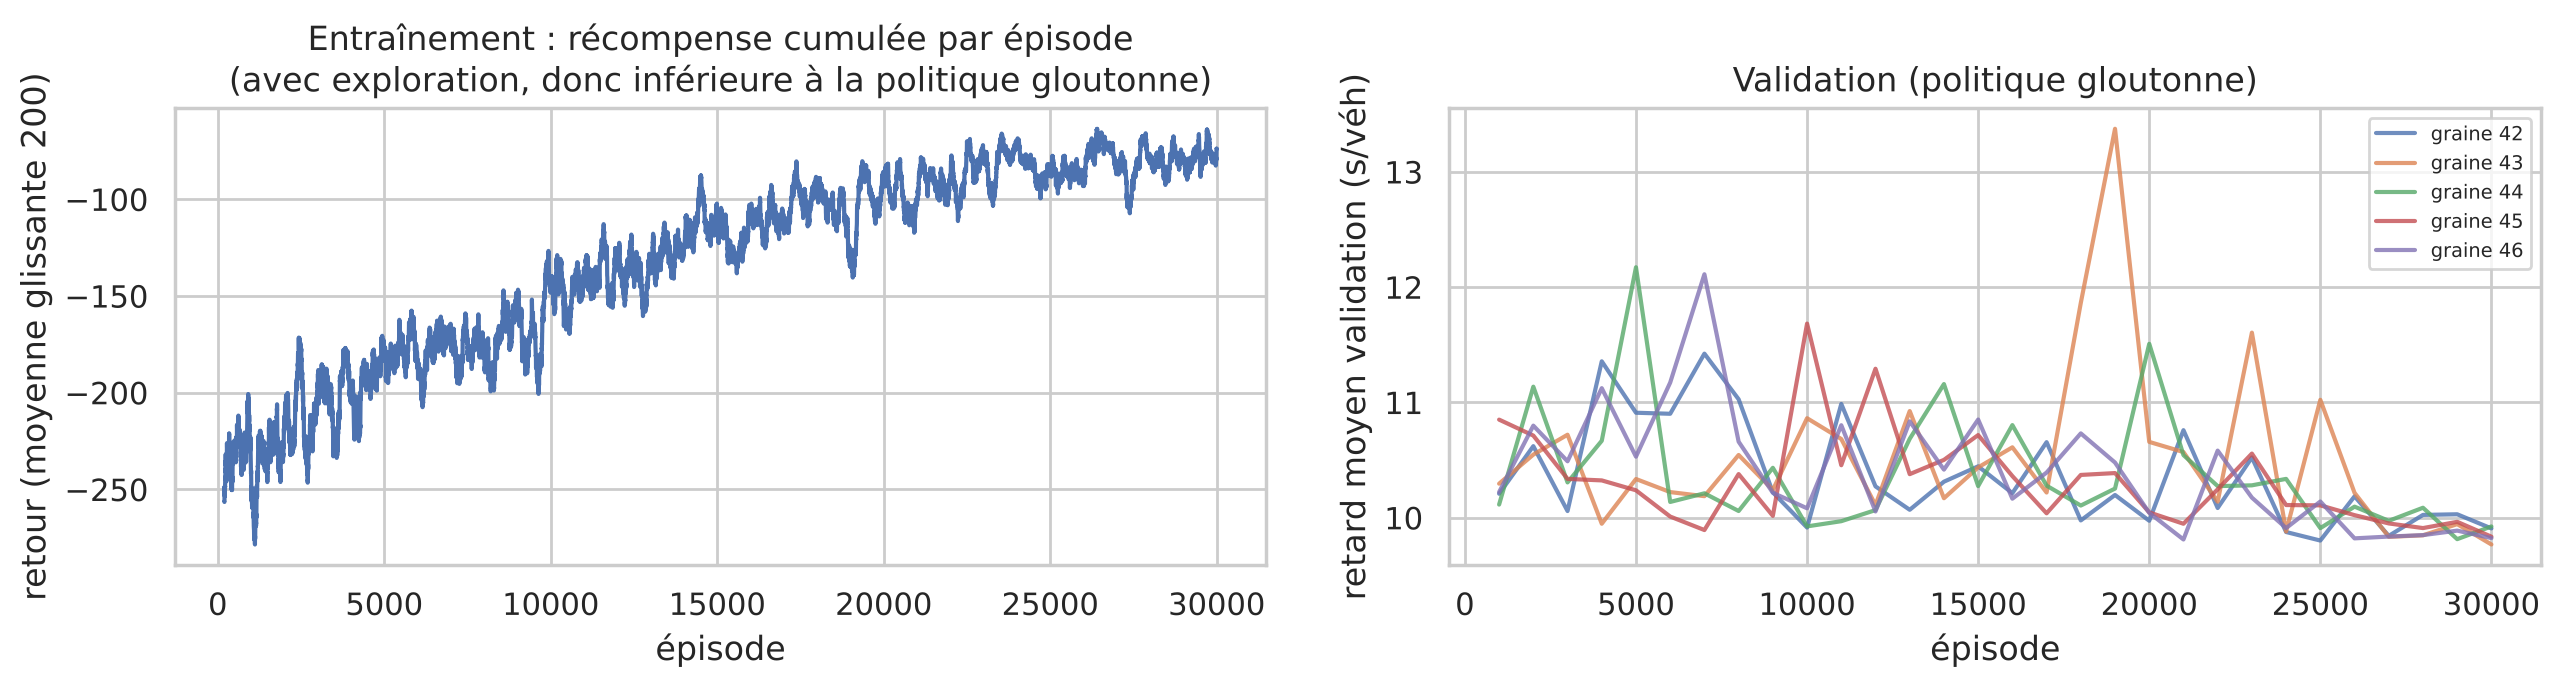

In [66]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
r = pd.Series(retours).rolling(200).mean()
ax[0].plot(r); ax[0].set_xlabel("épisode"); ax[0].set_ylabel("retour (moyenne glissante 200)"); ax[0].set_title("Entraînement : récompense cumulée par épisode\n(avec exploration, donc inférieure à la politique gloutonne)")
for a_ in AGENTS:
    jv = pd.DataFrame(a_["journal_val"], columns=["episode", "retard"]); ax[1].plot(jv.episode, jv.retard, alpha=0.8, label=f"graine {a_['seed']}")
ax[1].legend(fontsize=7); ax[1].set_xlabel("épisode"); ax[1].set_ylabel("retard moyen validation (s/véh)")
ax[1].set_title("Validation (politique gloutonne)")
plt.tight_layout(); plt.show()

## 5. Évaluation

### 5.1 Réglage des références sur la validation

In [67]:
val = scenarios_reels("val")
grille_G = [10, 15, 20, 30, 45, 60]
ev = {G: evaluer(lambda G=G: pol_fixe(G), val, 2).retard_s_par_veh.mean() for G in grille_G}
G_OPT = min(ev, key=ev.get)
ev_m = {m: evaluer(lambda m=m: pol_longue_file(m), val, 2).retard_s_par_veh.mean() for m in [0, 1, 2, 4, 6, 8, 10, 14]}
M_OPT = min(ev_m, key=ev_m.get)
print("Temps fixe, retard moyen (validation) selon G :", {k: round(v, 1) for k, v in ev.items()}, f"-> G = {G_OPT} s")
print("Plus longue file, retard moyen selon la marge  :", {k: round(v, 1) for k, v in ev_m.items()}, f"-> marge = {M_OPT}")

q_pol = lambda env, Q=Q: int(Q[env.etat()].argmax())
POLITIQUES = {"Aléatoire": lambda: pol_aleatoire(1),
              f"Temps fixe ({G_OPT} s, optimisé)": lambda: pol_fixe(G_OPT), f"Plus longue file (marge {M_OPT})": lambda: pol_longue_file(M_OPT),
              "Q-learning": lambda: q_pol}

Temps fixe, retard moyen (validation) selon G : {10: np.float64(56.3), 15: np.float64(39.1), 20: np.float64(32.6), 30: np.float64(31.0), 45: np.float64(33.6), 60: np.float64(35.6)} -> G = 30 s
Plus longue file, retard moyen selon la marge  : {0: np.float64(12.7), 1: np.float64(11.9), 2: np.float64(11.0), 4: np.float64(10.4), 6: np.float64(10.3), 8: np.float64(10.5), 10: np.float64(10.4), 14: np.float64(10.4)} -> marge = 6


### 5.2 Scénarios **réels** de test

Créneaux de 15 minutes pris dans la période de **test** (la fin de la simulation, jamais vue à l'entraînement), pour chacune des 5 cellules.

In [68]:
test_reel = scenarios_reels("test")
res_reel = {nom: evaluer(f, test_reel, 6) for nom, f in POLITIQUES.items()}
tab = pd.DataFrame({nom: d[["retard_s_par_veh", "file_moyenne", "debit_veh_h", "file_max", "changements_h"]].mean() for nom, d in res_reel.items()}).T
tab["IC95 retard (±)"] = [1.96 * d.retard_s_par_veh.std() / np.sqrt(len(d)) for d in res_reel.values()]
print(f"{len(test_reel)} créneaux x 6 graines = {len(test_reel) * 6} épisodes par politique\n")
print(tab.round(2).to_string())

15 créneaux x 6 graines = 90 épisodes par politique

                             retard_s_par_veh  file_moyenne  debit_veh_h  file_max  changements_h  IC95 retard (±)
Aléatoire                               68.94         19.23       850.98     44.72          44.00             6.54
Temps fixe (30 s, optimisé)             30.07          8.41       898.80     23.57         120.00             2.68
Plus longue file (marge 6)              11.89          3.71       926.36     14.09         149.64             1.78
Q-learning                              11.55          3.57       927.33     13.80         149.64             1.62


In [69]:
# Variabilité du Q-learning : les 5 agents sur les mêmes scénarios de test
agents_test = []
for a_ in AGENTS:
    pol = (lambda env, Qa=a_["Q"]: int(Qa[env.etat()].argmax()))
    agents_test.append(float(evaluer(lambda: pol, test_reel, 6).retard_s_par_veh.mean()))
print("Retard moyen sur le test, par agent (s/véh) :", [round(v, 2) for v in agents_test])
print(f"Moyenne des 5 agents = {np.mean(agents_test):.2f}, écart-type = {np.std(agents_test):.2f}, agent retenu sur la validation : {agents_test[CHOIX]:.2f}")

Retard moyen sur le test, par agent (s/véh) : [11.97, 11.55, 11.46, 11.87, 11.64]
Moyenne des 5 agents = 11.70, écart-type = 0.19, agent retenu sur la validation : 11.55


In [70]:
# Comparaison appariée Q-learning vs plus longue file : mêmes créneaux, mêmes aléas, différence épisode par épisode
nom_h = [n for n in res_reel if n.startswith("Plus longue")][0]
diff = (res_reel["Q-learning"].retard_s_par_veh.values - res_reel[nom_h].retard_s_par_veh.values)
ic = 1.96 * diff.std() / np.sqrt(len(diff))
print(f"Δ retard (Q-learning - plus longue file) = {diff.mean():+.2f} s/véh, IC95 [{diff.mean() - ic:+.2f}, {diff.mean() + ic:+.2f}] sur {len(diff)} épisodes appariés")
print("Épisodes où Q-learning fait mieux :", f"{100 * (diff < 0).mean():.0f} %")

Δ retard (Q-learning - plus longue file) = -0.34 s/véh, IC95 [-0.62, -0.07] sur 90 épisodes appariés
Épisodes où Q-learning fait mieux : 27 %


### 5.3 Scénarios synthétiques de stress

Pour tester la **robustesse** de l'agent face à des situations **absentes de l'entraînement** (le train ne contient que des profils réels). Flux en véhicules/minute pour chaque axe, sur 15 minutes :

| Scénario | Description |
|---|---|
| Équilibré, modéré | 10 / 10 |
| Asymétrique | 4 / 18 (un axe très dominant) |
| Forte charge | 18 / 18 (proche de la saturation) |
| Pic soudain | 6 / 6 pendant 5 min, puis 20 / 20 pendant 5 min, puis 6 / 6 |
| Capacité réduite | 12 / 12 mais flux de saturation 0,4 au lieu de 0,5 (pluie, incident) |

In [71]:
def const(a, b): return {"lam0": [a] * DUREE, "lam1": [b] * DUREE}
SYNTH = {
    "Équilibré, modéré": dict(nom="eq", **const(10, 10), S=0.5),
    "Asymétrique":       dict(nom="asym", **const(4, 18), S=0.5),
    "Forte charge":      dict(nom="forte", **const(18, 18), S=0.5),
    "Pic soudain":       dict(nom="pic", lam0=[6] * 5 + [20] * 5 + [6] * 5, lam1=[6] * 5 + [20] * 5 + [6] * 5, S=0.5),
    "Capacité réduite":  dict(nom="cap", **const(12, 12), S=0.4),
}
res_syn = {}
for scen, cfg in SYNTH.items():
    res_syn[scen] = {nom: evaluer(f, [cfg], 20, saturation=cfg["S"]).retard_s_par_veh.mean() for nom, f in POLITIQUES.items()}
syn = pd.DataFrame(res_syn).T
print("Retard moyen par véhicule (secondes), 20 graines par scénario :")
print(syn.round(1).to_string())

Retard moyen par véhicule (secondes), 20 graines par scénario :
                   Aléatoire  Temps fixe (30 s, optimisé)  Plus longue file (marge 6)  Q-learning
Équilibré, modéré       64.4                         20.3                        11.7        11.6
Asymétrique             55.2                        109.6                        12.1        12.1
Forte charge           120.4                        119.4                       111.3        93.0
Pic soudain             85.3                         69.6                        59.0        55.4
Capacité réduite       112.2                         71.3                        49.7        49.9


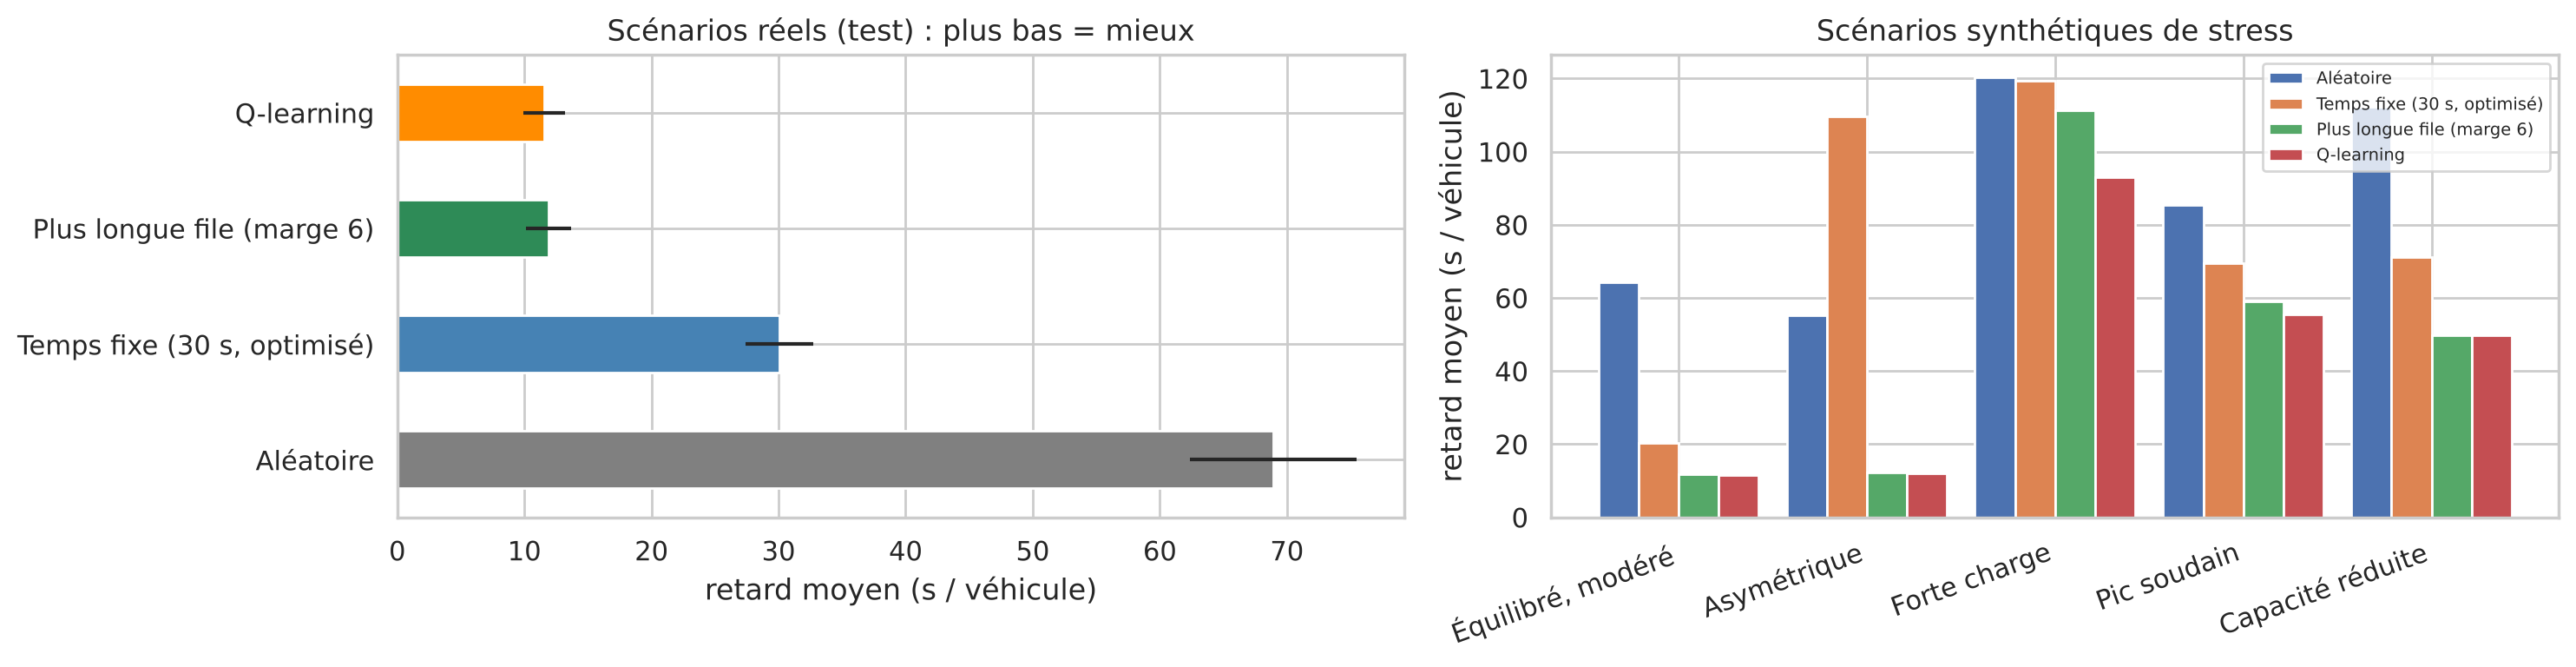

In [72]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
tab["retard_s_par_veh"].plot.barh(ax=ax[0], xerr=tab["IC95 retard (±)"], color=["gray", "steelblue", "seagreen", "darkorange"])
ax[0].set_xlabel("retard moyen (s / véhicule)"); ax[0].set_title("Scénarios réels (test) : plus bas = mieux")
syn.plot.bar(ax=ax[1], width=0.85); ax[1].set_ylabel("retard moyen (s / véhicule)"); ax[1].set_title("Scénarios synthétiques de stress")
ax[1].legend(fontsize=7); plt.setp(ax[1].get_xticklabels(), rotation=20, ha="right")
plt.tight_layout(); plt.show()

### 5.4 Comportement de l'agent

**Que fait la politique apprise ?** On visualise l'action choisie selon les files des deux axes quand l'axe 0 est au vert (vert minimal écoulé) : en bleu, l'agent **change** de phase ; en blanc, il **garde**.

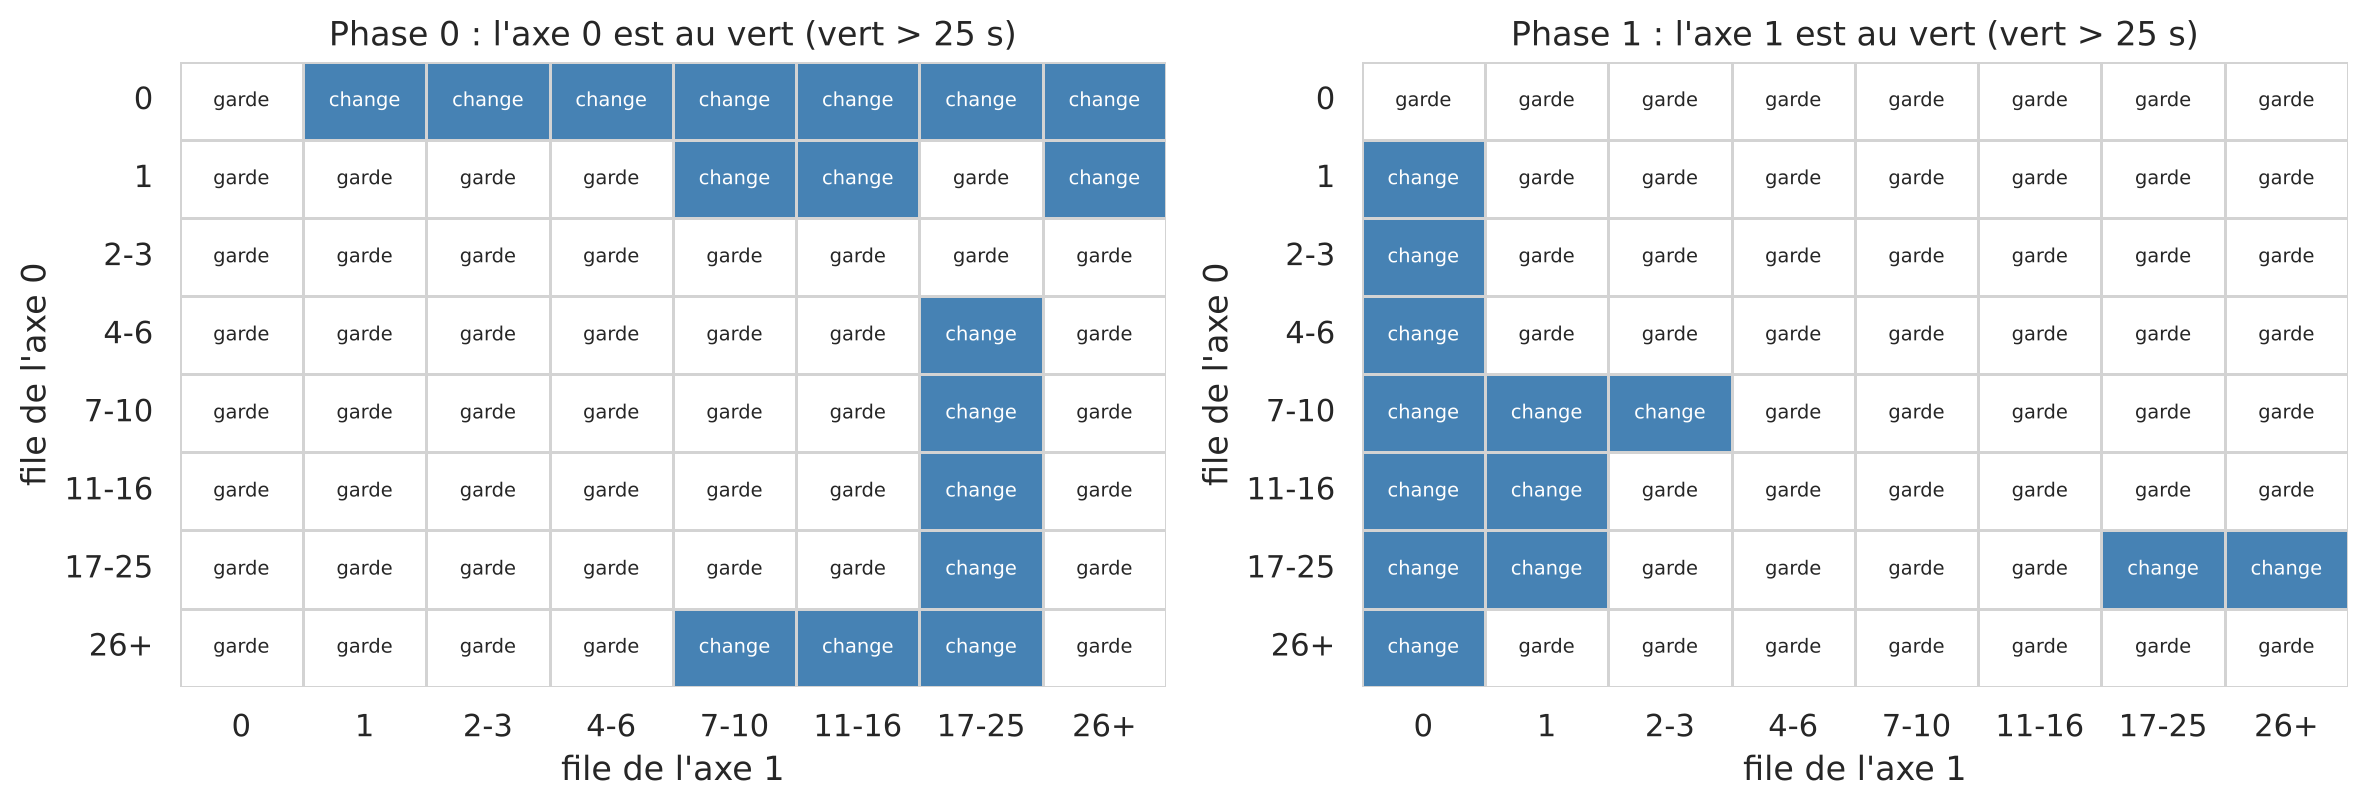

Cases vides = états rares (moins de 200 passages pendant l'entraînement) : la décision y est peu fiable. États visités au moins 200 fois : 384 sur 384


In [73]:
import matplotlib.colors as mcolors
etiq = ["0", "1", "2-3", "4-6", "7-10", "11-16", "17-25", "26+"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, phase in zip(ax, [0, 1]):
    M = np.array([[int(Q[((i * 8 + j) * 2 + phase) * 3 + 2].argmax()) for j in range(8)] for i in range(8)])
    visite = np.array([[VISITES[((i * 8 + j) * 2 + phase) * 3 + 2] >= 200 for j in range(8)] for i in range(8)])      # états rencontrés au moins 200 fois
    sns.heatmap(np.where(visite, M, np.nan), cmap=mcolors.ListedColormap(["white", "steelblue"]), cbar=False, ax=a, linewidths=.5,
                xticklabels=etiq, yticklabels=etiq, linecolor="lightgray", annot=np.where(visite, np.where(M == 1, "change", "garde"), ""), fmt="s", annot_kws={"fontsize": 7})
    a.set_xlabel("file de l'axe 1"); a.set_ylabel("file de l'axe 0"); a.set_title(f"Phase {phase} : l'axe {phase} est au vert (vert > 25 s)")
plt.tight_layout(); plt.show()
print(f"Cases vides = états rares (moins de 200 passages pendant l'entraînement) : la décision y est peu fiable. États visités au moins 200 fois : {int((VISITES >= 200).sum())} sur {Carrefour.N_ETATS}")

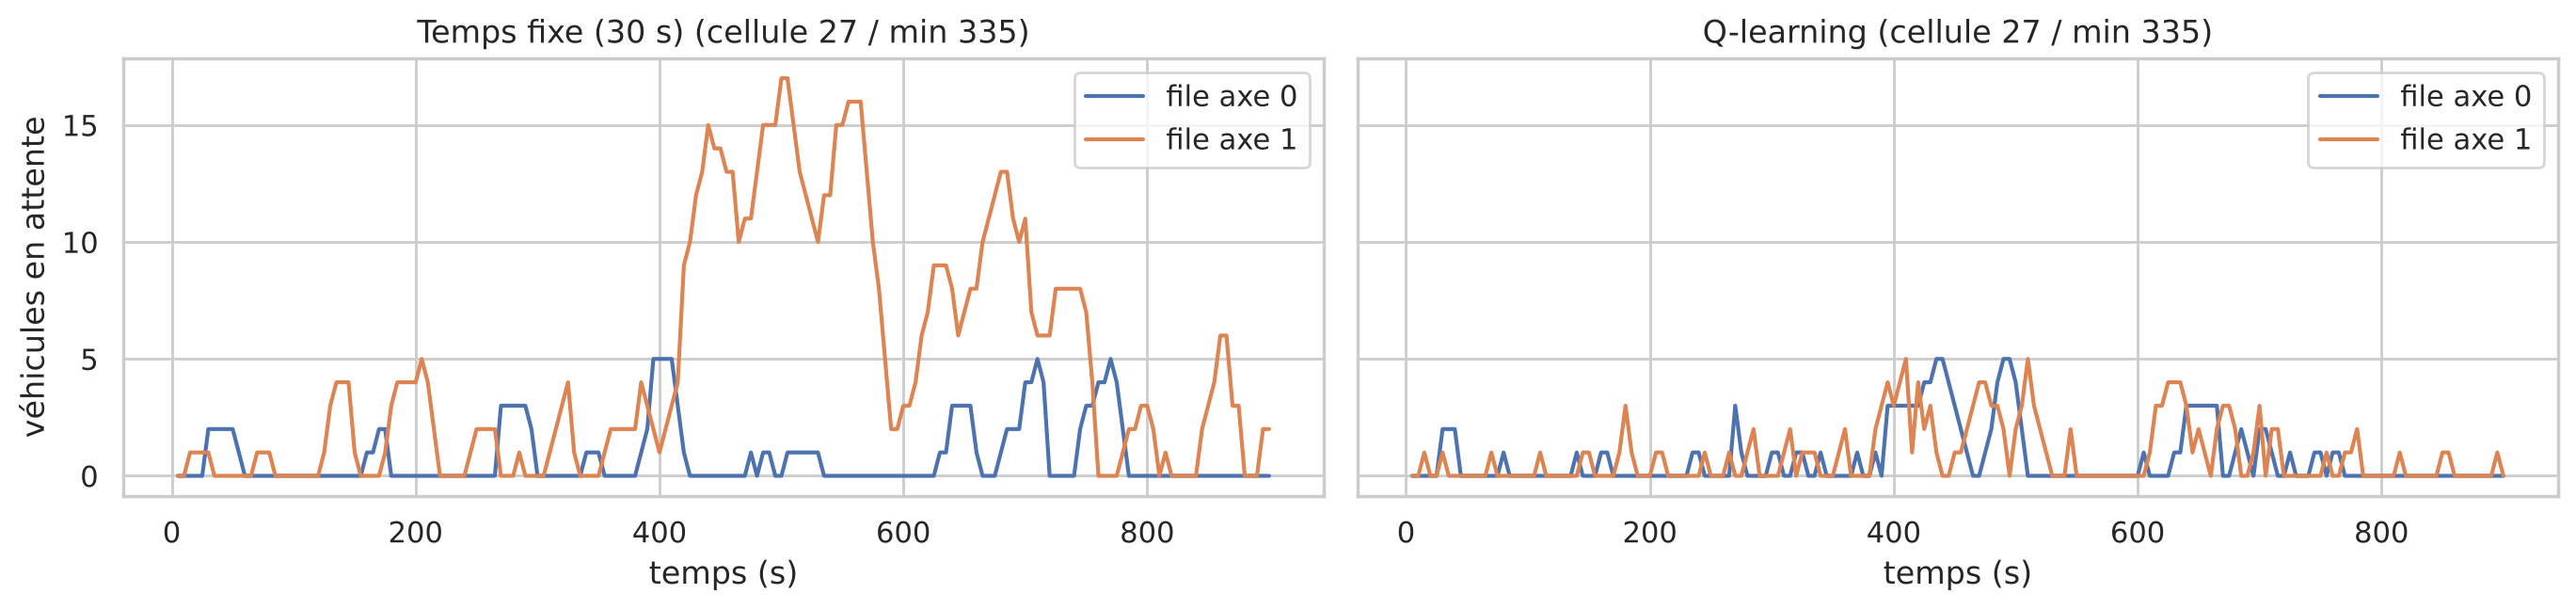

In [74]:
# Un épisode du test : files au cours du temps, temps fixe vs Q-learning
sc = test_reel[0]
def trace(politique, seed=0):
    env = Carrefour(); env.reset(sc["lam0"], sc["lam1"], seed); h, done = [], False
    while not done:
        _, _, done = env.step(politique(env)); h.append((env.t, env.q[0], env.q[1], env.phase))
    return pd.DataFrame(h, columns=["t", "q0", "q1", "phase"])
fig, ax = plt.subplots(1, 2, figsize=(14, 3.4), sharey=True)
for a, (nom, f) in zip(ax, [(f"Temps fixe ({G_OPT} s)", pol_fixe(G_OPT)), ("Q-learning", q_pol)]):
    d = trace(f); a.plot(d.t, d.q0, label="file axe 0"); a.plot(d.t, d.q1, label="file axe 1")
    a.set_title(f"{nom} ({sc['nom']})"); a.set_xlabel("temps (s)"); a.legend()
ax[0].set_ylabel("véhicules en attente")
plt.tight_layout(); plt.show()

In [75]:
# Sauvegarde pour la partie 5
reel = {nom: {"retard_s_par_veh": float(d.retard_s_par_veh.mean()), "ic95": float(1.96 * d.retard_s_par_veh.std() / np.sqrt(len(d))),
              "file_moyenne": float(d.file_moyenne.mean()), "debit_veh_h": float(d.debit_veh_h.mean()),
              "file_max": float(d.file_max.mean()), "changements_h": float(d.changements_h.mean())} for nom, d in res_reel.items()}
json.dump({"reel_test": reel, "synthetique": {k: {n: float(v) for n, v in r.items()} for k, r in res_syn.items()},
           "parametres": {"G_optimal": int(G_OPT), "marge_optimale": int(M_OPT), "episodes": 30000, "agents_q_test": agents_test,
                          "retard_par_scenario_reel": {nom: d.groupby("scenario").retard_s_par_veh.mean().to_dict() for nom, d in res_reel.items()}}},
          open("results/rl_metrics.json", "w"), indent=2, ensure_ascii=False)
np.save("results/rl_qtable.npy", Q)
print("Sauvegardé : results/rl_metrics.json et results/rl_qtable.npy")

Sauvegardé : results/rl_metrics.json et results/rl_qtable.npy


## 6. Analyse

### Ce que montre la comparaison
- **Cadre** : on compare quatre politiques sur 15 scénarios construits à partir des flux réels de la période de test (5 cellules parmi les plus chargées × 3 instants), avec des arrivées simulées identiques pour toutes les politiques (nombres aléatoires communs) et un test apparié.
- **Retard moyen par véhicule** : aléatoire 68,9 s ; temps fixe optimisé (30 s) 30,1 s ; plus longue file 11,9 s ; **Q-learning 11,5 s**. L'agent réduit donc le retard d'environ **62 %** par rapport au temps fixe et de **83 %** par rapport à une politique aléatoire.
- **Face à l'heuristique « plus longue file »** (réglée sur la validation, donc pas un adversaire facile) : le gain moyen est faible, de **−0,34 s** par véhicule, mais l'intervalle de confiance à 95 % de la différence appariée exclut 0. L'agent est donc *légèrement* meilleur, pas radicalement. Les 5 agents entraînés avec des graines différentes donnent des retards de 11,5 à 12,0 s : la dispersion est du même ordre que le gain, il faut donc rester prudent.
- **Scénarios synthétiques** : le temps fixe s'effondre quand le trafic est asymétrique (109,6 s contre 12,1 s pour l'agent) puisqu'il ne s'adapte pas ; l'agent et l'heuristique sont à égalité quand le trafic est équilibré ou la capacité réduite (49,9 s contre 49,7 s) ; l'avantage de l'agent apparaît surtout en **forte charge** (93,0 s contre 111,3 s, soit −16 %) et face à un **pic soudain** (55,4 s contre 59,0 s). Quand les files saturent, la règle « servir la plus longue file » n'est plus optimale, alors que l'agent a appris à anticiper.
- **Politique apprise** (carte ci-dessus, vert > 25 s) : la structure principale est celle attendue. L'agent **change de phase quand la file de l'axe au vert est vide (ou presque) alors que l'autre axe attend**, et il **garde** la phase tant que l'axe servi a encore des véhicules. On retrouve donc l'esprit de la règle « plus longue file ». La carte n'est pourtant pas aussi régulière que la règle écrite à la main : quelques cases sont irrégulières (par exemple « change » pour une file de 17-25 mais « garde » pour 26+ sur l'autre axe), ce qui indique que, dans ces états plus rares, la valeur apprise reste bruitée. C'est une limite de l'apprentissage tabulaire par exploration, qui explique en partie pourquoi le gain sur l'heuristique est faible.

### Limites (à garder à l'esprit)
- L'environnement est une **simulation simplifiée** d'un carrefour à 2 phases, alimentée par les flux réels agrégés par minute et par axe ; les hypothèses (saturation 0,5 véh/s, temps perdu 3 s, vert minimal 10 s) sont les nôtres, pas celles du simulateur d'origine. Les chiffres de retard sont donc **relatifs** (comparaison entre politiques), pas des retards réels du réseau.
- Un Q-learning **tabulaire** exige de discrétiser l'état (files, phase, durée de vert) ; la précision est bornée par cette discrétisation.
- Le gain sur l'heuristique est modeste ; son intérêt est d'apprendre sans règle écrite à la main, et de mieux gérer les situations saturées.

---
---
<a id='partie5'></a>

# Partie 5 : Évaluation et analyse comparative

**Projet : Smart Traffic Flow Prediction and Optimization**

Cette partie **ne ré-entraîne rien** : elle relit les résultats sauvegardés par les parties 2, 3 et 4 (`results/`) et les compare sur le **jeu de test**, c'est-à-dire la dernière partie de la simulation (15 % des minutes), jamais utilisée pour choisir un modèle ni un hyperparamètre.

**Plan** : 1. chargement · 2. tableau comparatif · 3. les différences sont-elles significatives ? · 4. où les modèles se trompent · 5. coût et variabilité · 6. agent RL · 7. démonstration · 8. limites, pistes et conclusion.

**Choix des métriques**

| Tâche | Métrique principale | Pourquoi |
|---|---|---|
| `etat` (3 classes équilibrées) | **F1 macro**, rappel de la classe « congestionné », AUC | classes équilibrées par construction, mais rater un embouteillage est plus coûteux que rater une circulation fluide, d'où le rappel de cette classe |
| `vitesse` | **MAE** (m/s), RMSE, R² | la MAE est lisible (erreur moyenne en m/s) et peu sensible aux rares pics ; le RMSE pénalise davantage les gros écarts |
| `flux` | **MAE** (véhicules), RMSE, R² | idem ; le flux est un comptage asymétrique avec quelques pics |
| Agent RL | **retard moyen par véhicule** (s), débit, file maximale | mesure directe de l'objectif d'optimisation |

## 1. Chargement des résultats

Les modèles sont comparés **ligne par ligne** : les prédictions sauvegardées par les parties 2 et 3 portent sur exactement les mêmes lignes de test. On recalcule aussi les références simples (persistance, profil de la cellule) pour savoir si les modèles apportent quelque chose.

In [76]:
RAW = charger("raw")
TEST, TRAIN = RAW[2], RAW[0]
MODELES_ML = ["RandomForest", "XGBoost", "AdaBoost", "ANN"]
FAMILLE = {"RandomForest": "Bagging", "XGBoost": "Boosting", "AdaBoost": "Boosting", "ANN": "Réseau de neurones"}

PRED, IDX = {}, {}
PROFIL_FLUX = TRAIN.groupby("cell_id")["n_veh_next"].mean()
for t, info in TASKS.items():
    d = TEST.dropna(subset=[info["target"]]); IDX[t] = d.index
    e = pd.read_parquet(f"results/ensemble_preds_{t}.parquet"); a = pd.read_parquet(f"results/ann_preds_{t}.parquet")
    assert np.array_equal(e.y_true.values, a.y_true.values) and len(e) == len(d), "lignes de test non alignées"
    P = {"y_true": e.y_true.values, **{m: e[m].values for m in ["RandomForest", "XGBoost", "AdaBoost"]}, "ANN": a["ANN"].values}
    if t == "vitesse":
        P["Persistance"] = d.speed_roll3.fillna(d.cell_speed_mean).values; P["Profil cellule"] = d.cell_speed_mean.values
    if t == "flux":
        P["Persistance"] = d.n_veh_roll3.values; P["Profil cellule"] = d.cell_id.map(PROFIL_FLUX).fillna(PROFIL_FLUX.mean()).values
    if t == "etat":
        P["Persistance"] = np.digitize(d.speed_roll3.fillna(d.cell_speed_mean), SEUILS); P["Profil cellule"] = np.digitize(d.cell_speed_mean, SEUILS)
    PRED[t] = P
    print(f"{t:8s}: {len(d):6,} lignes de test, {len(P) - 1} modèles / références alignés")

MET_ENS = json.load(open("results/ensemble_metrics.json")); MET_ANN = json.load(open("results/ann_metrics.json")); MET_RL = json.load(open("results/rl_metrics.json"))

etat    :  8,177 lignes de test, 6 modèles / références alignés
vitesse :  8,177 lignes de test, 6 modèles / références alignés
flux    : 10,000 lignes de test, 6 modèles / références alignés


## 2. Tableau comparatif sur le test

In [77]:
PROBA_AUC = {}      # l'AUC vient des métriques sauvegardées (les probabilités n'ont pas été conservées)
rows = []
for t, info in TASKS.items():
    for m, p in PRED[t].items():
        if m == "y_true": continue
        r = metriques(info["kind"], PRED[t]["y_true"], p)
        if info["kind"] == "clf" and m in MODELES_ML:
            src = MET_ANN if m == "ANN" else MET_ENS
            r["AUC_ovr"] = src[t][m]["test"].get("AUC_ovr", np.nan)
        rows.append({"tâche": t, "modèle": m, "famille": FAMILLE.get(m, "Référence"), **r})
TAB = pd.DataFrame(rows)

crit = {"etat": "F1_macro", "vitesse": "MAE", "flux": "MAE"}
for t, info in TASKS.items():
    d = TAB[TAB["tâche"] == t].dropna(axis=1, how="all").drop(columns="tâche")
    d = d.sort_values(crit[t], ascending=(info["kind"] == "reg")).reset_index(drop=True)
    print(f"\n=== {t} : {info['nom']} (trié par {crit[t]}) ===")
    print(d.round(3).to_string(index=False))


=== etat : État du trafic (trié par F1_macro) ===
        modèle            famille  Accuracy  F1_macro  Rappel_congestionné  Rappel_ralenti  Rappel_fluide  AUC_ovr
           ANN Réseau de neurones     0.732     0.731                0.822           0.617          0.759    0.889
       XGBoost           Boosting     0.730     0.730                0.800           0.639          0.753    0.892
  RandomForest            Bagging     0.729     0.730                0.799           0.642          0.749    0.891
      AdaBoost           Boosting     0.722     0.723                0.788           0.638          0.742    0.887
Profil cellule          Référence     0.709     0.714                0.716           0.697          0.715      NaN
   Persistance          Référence     0.685     0.688                0.765           0.633          0.659      NaN

=== vitesse : Vitesse moyenne (m/s) (trié par MAE) ===
        modèle            famille   MAE  RMSE    R2
       XGBoost           Boosting 1.

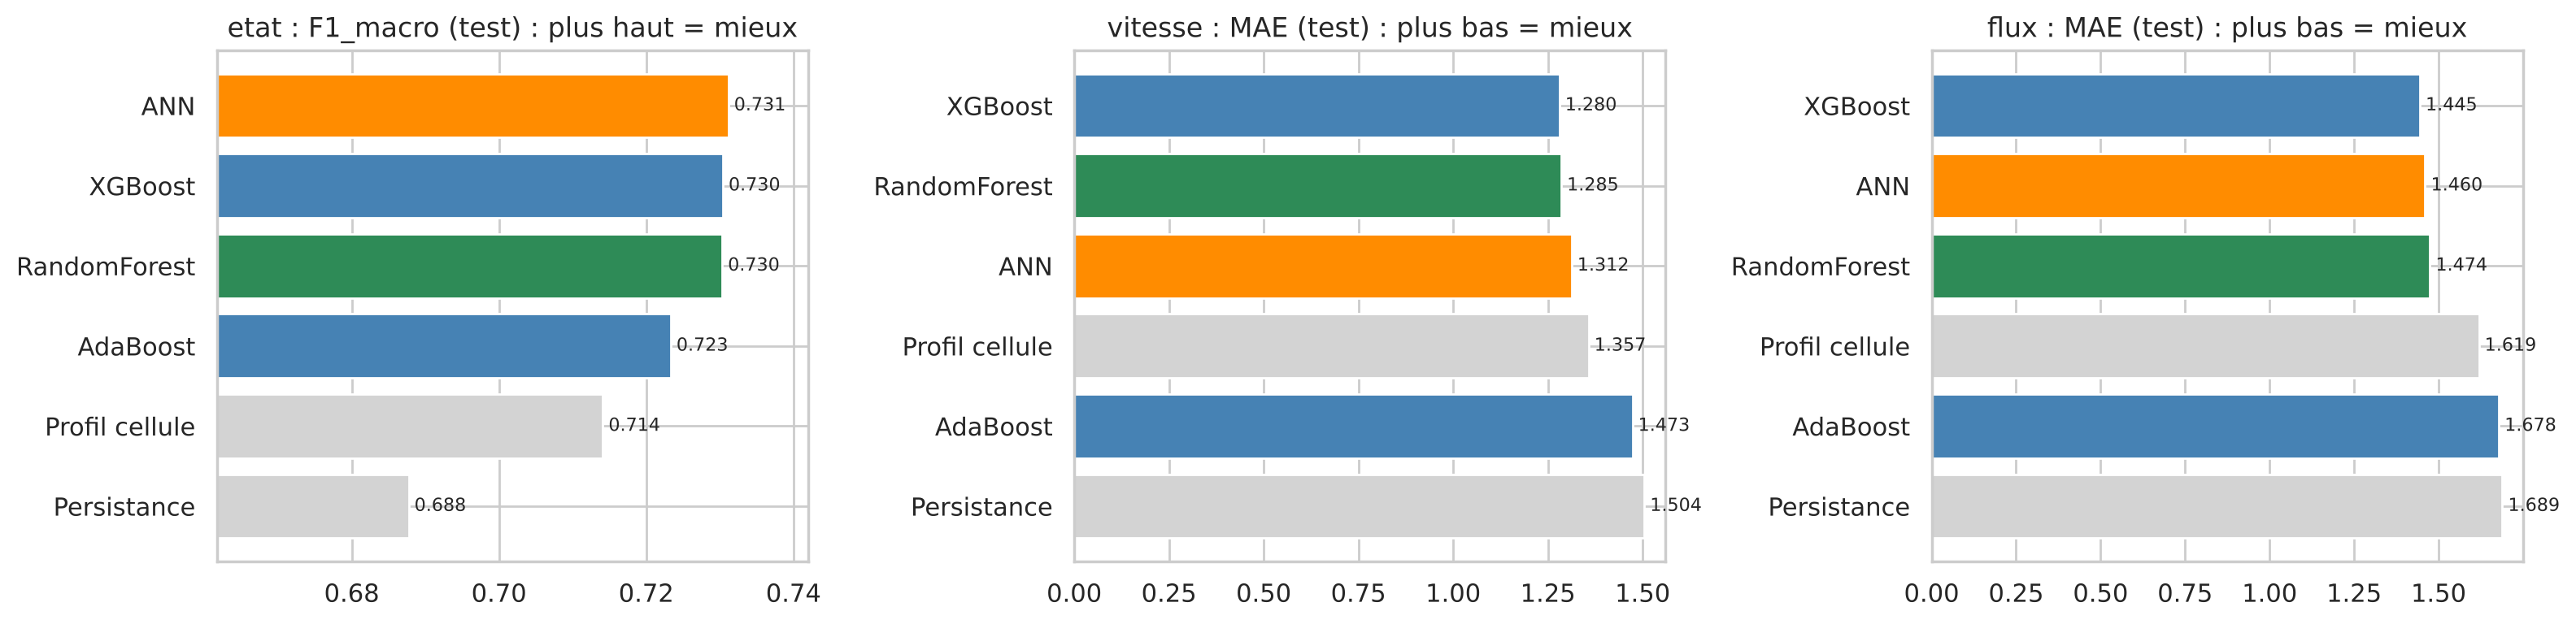

In [78]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
couleur = {"Référence": "lightgray", "Bagging": "seagreen", "Boosting": "steelblue", "Réseau de neurones": "darkorange"}
for a, t in zip(ax, TASKS):
    d = TAB[TAB["tâche"] == t].sort_values(crit[t], ascending=(TASKS[t]["kind"] == "reg"))
    a.barh(d["modèle"], d[crit[t]], color=[couleur[f] for f in d["famille"]])
    a.invert_yaxis(); a.set_title(f"{t} : {crit[t]} (test)" + (" : plus haut = mieux" if TASKS[t]["kind"] == "clf" else " : plus bas = mieux"))
    for i, v in enumerate(d[crit[t]]): a.text(v, i, f" {v:.3f}", va="center", fontsize=8)
    lo, hi = d[crit[t]].min(), d[crit[t]].max(); a.set_xlim(lo - (hi - lo) * 0.6 if TASKS[t]["kind"] == "clf" else 0, hi + (hi - lo) * 0.25)
plt.tight_layout(); plt.show()

## 3. Les différences sont-elles significatives ?

Quand deux modèles ont des scores proches (0,735 contre 0,740, par exemple), on ne peut pas conclure sans mesurer l'**incertitude**. On utilise un **bootstrap par blocs de minutes** : on tire au hasard, avec remise, des minutes entières du test (et pas des lignes isolées, car les cellules d'une même minute sont corrélées entre elles), et on recalcule la différence d'erreur. L'intervalle à 95 % qui ne contient pas 0 indique une différence nette.

Les paires comparées sont fixées **avant** de regarder les résultats : Boosting contre Bagging (XGBoost vs Random Forest), réseau de neurones contre Boosting, et meilleur modèle d'arbres contre persistance.

In [79]:
def bootstrap_diff(w, err_a, err_b, n=3000, seed=SEED):
    """Différence moyenne d'erreur (a - b) et IC95 % ; négatif = a est meilleur. Rééchantillonnage par minute (bloc)."""
    g = pd.DataFrame({"w": w, "d": err_a - err_b}).groupby("w")["d"].agg(["sum", "count"])
    idx = np.random.default_rng(seed).integers(0, len(g), (n, len(g)))
    m = g["sum"].values[idx].sum(1) / g["count"].values[idx].sum(1)
    return float(g["sum"].sum() / g["count"].sum()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def erreur(t, m):
    y, p = PRED[t]["y_true"], PRED[t][m]
    return np.abs(y - p) if TASKS[t]["kind"] == "reg" else (y != p).astype(float)       # erreur absolue / erreur de classement

PAIRES = [("XGBoost", "RandomForest", "Boosting vs Bagging"), ("ANN", "XGBoost", "ANN vs Boosting"),
          ("XGBoost", "Persistance", "Boosting vs persistance"), ("ANN", "Persistance", "ANN vs persistance")]
lignes = []
for t in TASKS:
    w = TEST.loc[IDX[t], "w_cible"].values
    for a, b, nom in PAIRES:
        diff, lo, hi = bootstrap_diff(w, erreur(t, a), erreur(t, b))
        verdict = f"{a} meilleur" if hi < 0 else (f"{b} meilleur" if lo > 0 else "pas de différence nette")
        lignes.append({"tâche": t, "comparaison": nom, "Δ erreur moyenne": diff, "IC95 bas": lo, "IC95 haut": hi, "verdict": verdict})
print("Δ = erreur de A moins erreur de B (MAE en m/s ou en véhicules ; taux d'erreur de classement pour 'etat').\n")
print(pd.DataFrame(lignes).round(3).to_string(index=False))

Δ = erreur de A moins erreur de B (MAE en m/s ou en véhicules ; taux d'erreur de classement pour 'etat').

  tâche             comparaison  Δ erreur moyenne  IC95 bas  IC95 haut                 verdict
   etat     Boosting vs Bagging            -0.000    -0.006      0.005 pas de différence nette
   etat         ANN vs Boosting            -0.002    -0.008      0.004 pas de différence nette
   etat Boosting vs persistance            -0.045    -0.052     -0.037        XGBoost meilleur
   etat      ANN vs persistance            -0.047    -0.055     -0.038            ANN meilleur
vitesse     Boosting vs Bagging            -0.005    -0.011      0.001 pas de différence nette
vitesse         ANN vs Boosting             0.032     0.024      0.040        XGBoost meilleur
vitesse Boosting vs persistance            -0.224    -0.246     -0.202        XGBoost meilleur
vitesse      ANN vs persistance            -0.192    -0.213     -0.171            ANN meilleur
   flux     Boosting vs Bagging       

## 4. Où les modèles se trompent-ils ?

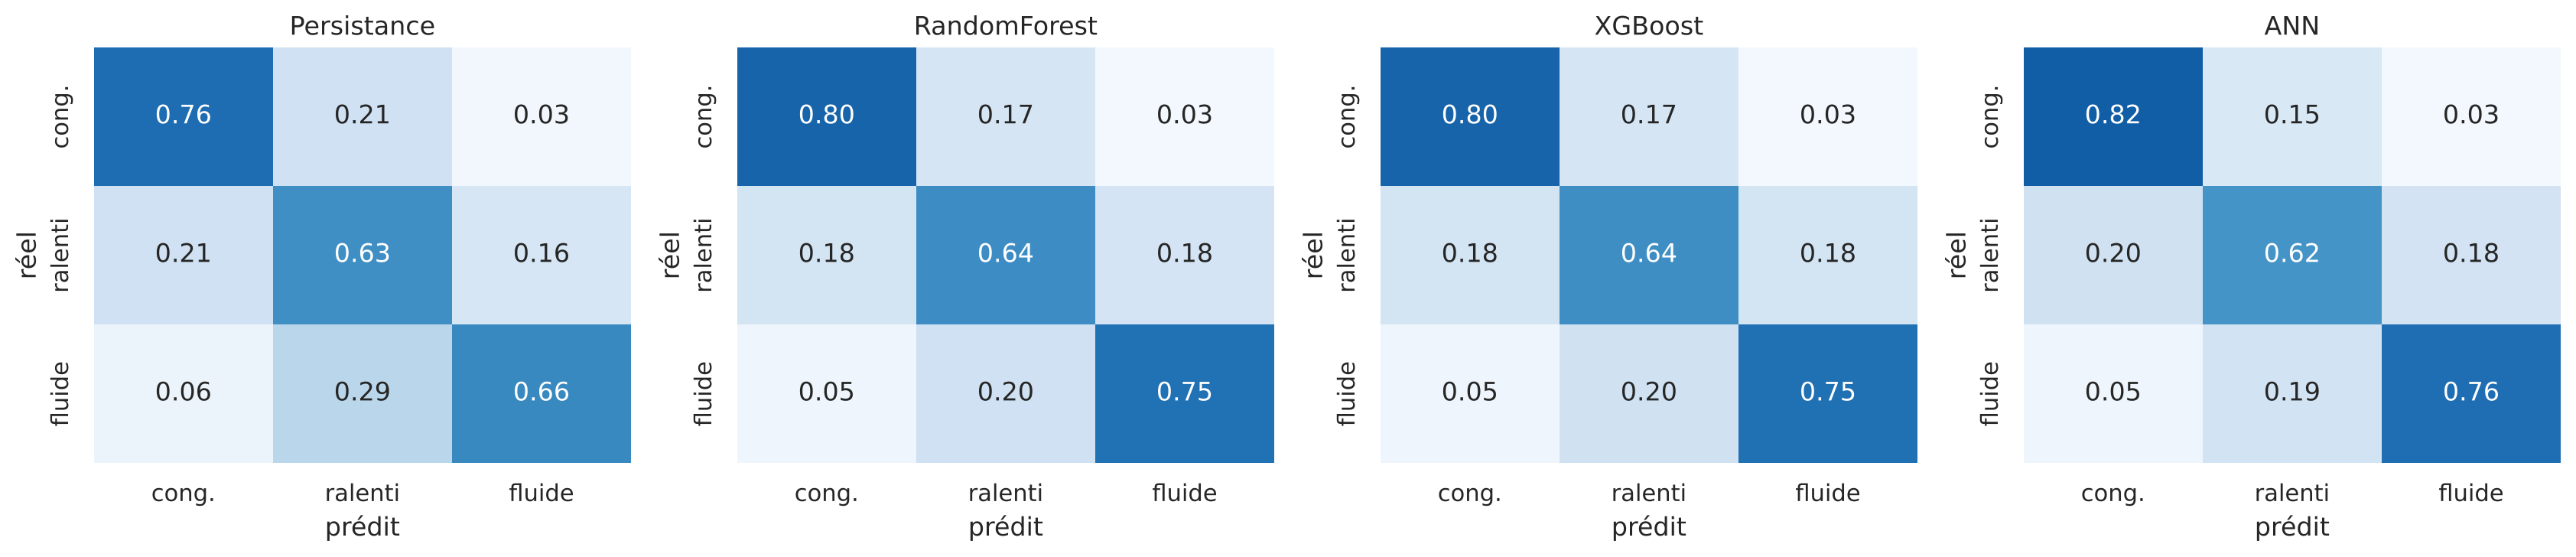

Persistance : erreurs = 31.5 % dont 2.8 % de confusions extrêmes (congestionné <-> fluide)
XGBoost     : erreurs = 27.0 % dont 2.5 % de confusions extrêmes (congestionné <-> fluide)
ANN         : erreurs = 26.8 % dont 2.5 % de confusions extrêmes (congestionné <-> fluide)


In [80]:
# Classification : matrices de confusion normalisées par classe réelle
t = "etat"
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, m in zip(ax, ["Persistance", "RandomForest", "XGBoost", "ANN"]):
    sns.heatmap(confusion_matrix(PRED[t]["y_true"], PRED[t][m], normalize="true"), annot=True, fmt=".2f", cmap="Blues", cbar=False,
                xticklabels=["cong.", "ralenti", "fluide"], yticklabels=["cong.", "ralenti", "fluide"], ax=a, vmin=0, vmax=1)
    a.set_title(m); a.set_xlabel("prédit"); a.set_ylabel("réel")
plt.tight_layout(); plt.show()

y = PRED[t]["y_true"]
for m in ["Persistance", "XGBoost", "ANN"]:
    ecart = np.abs(y - PRED[t][m])
    print(f"{m:12s}: erreurs = {100 * (ecart > 0).mean():.1f} % dont {100 * (ecart == 2).mean():.1f} % de confusions extrêmes (congestionné <-> fluide)")

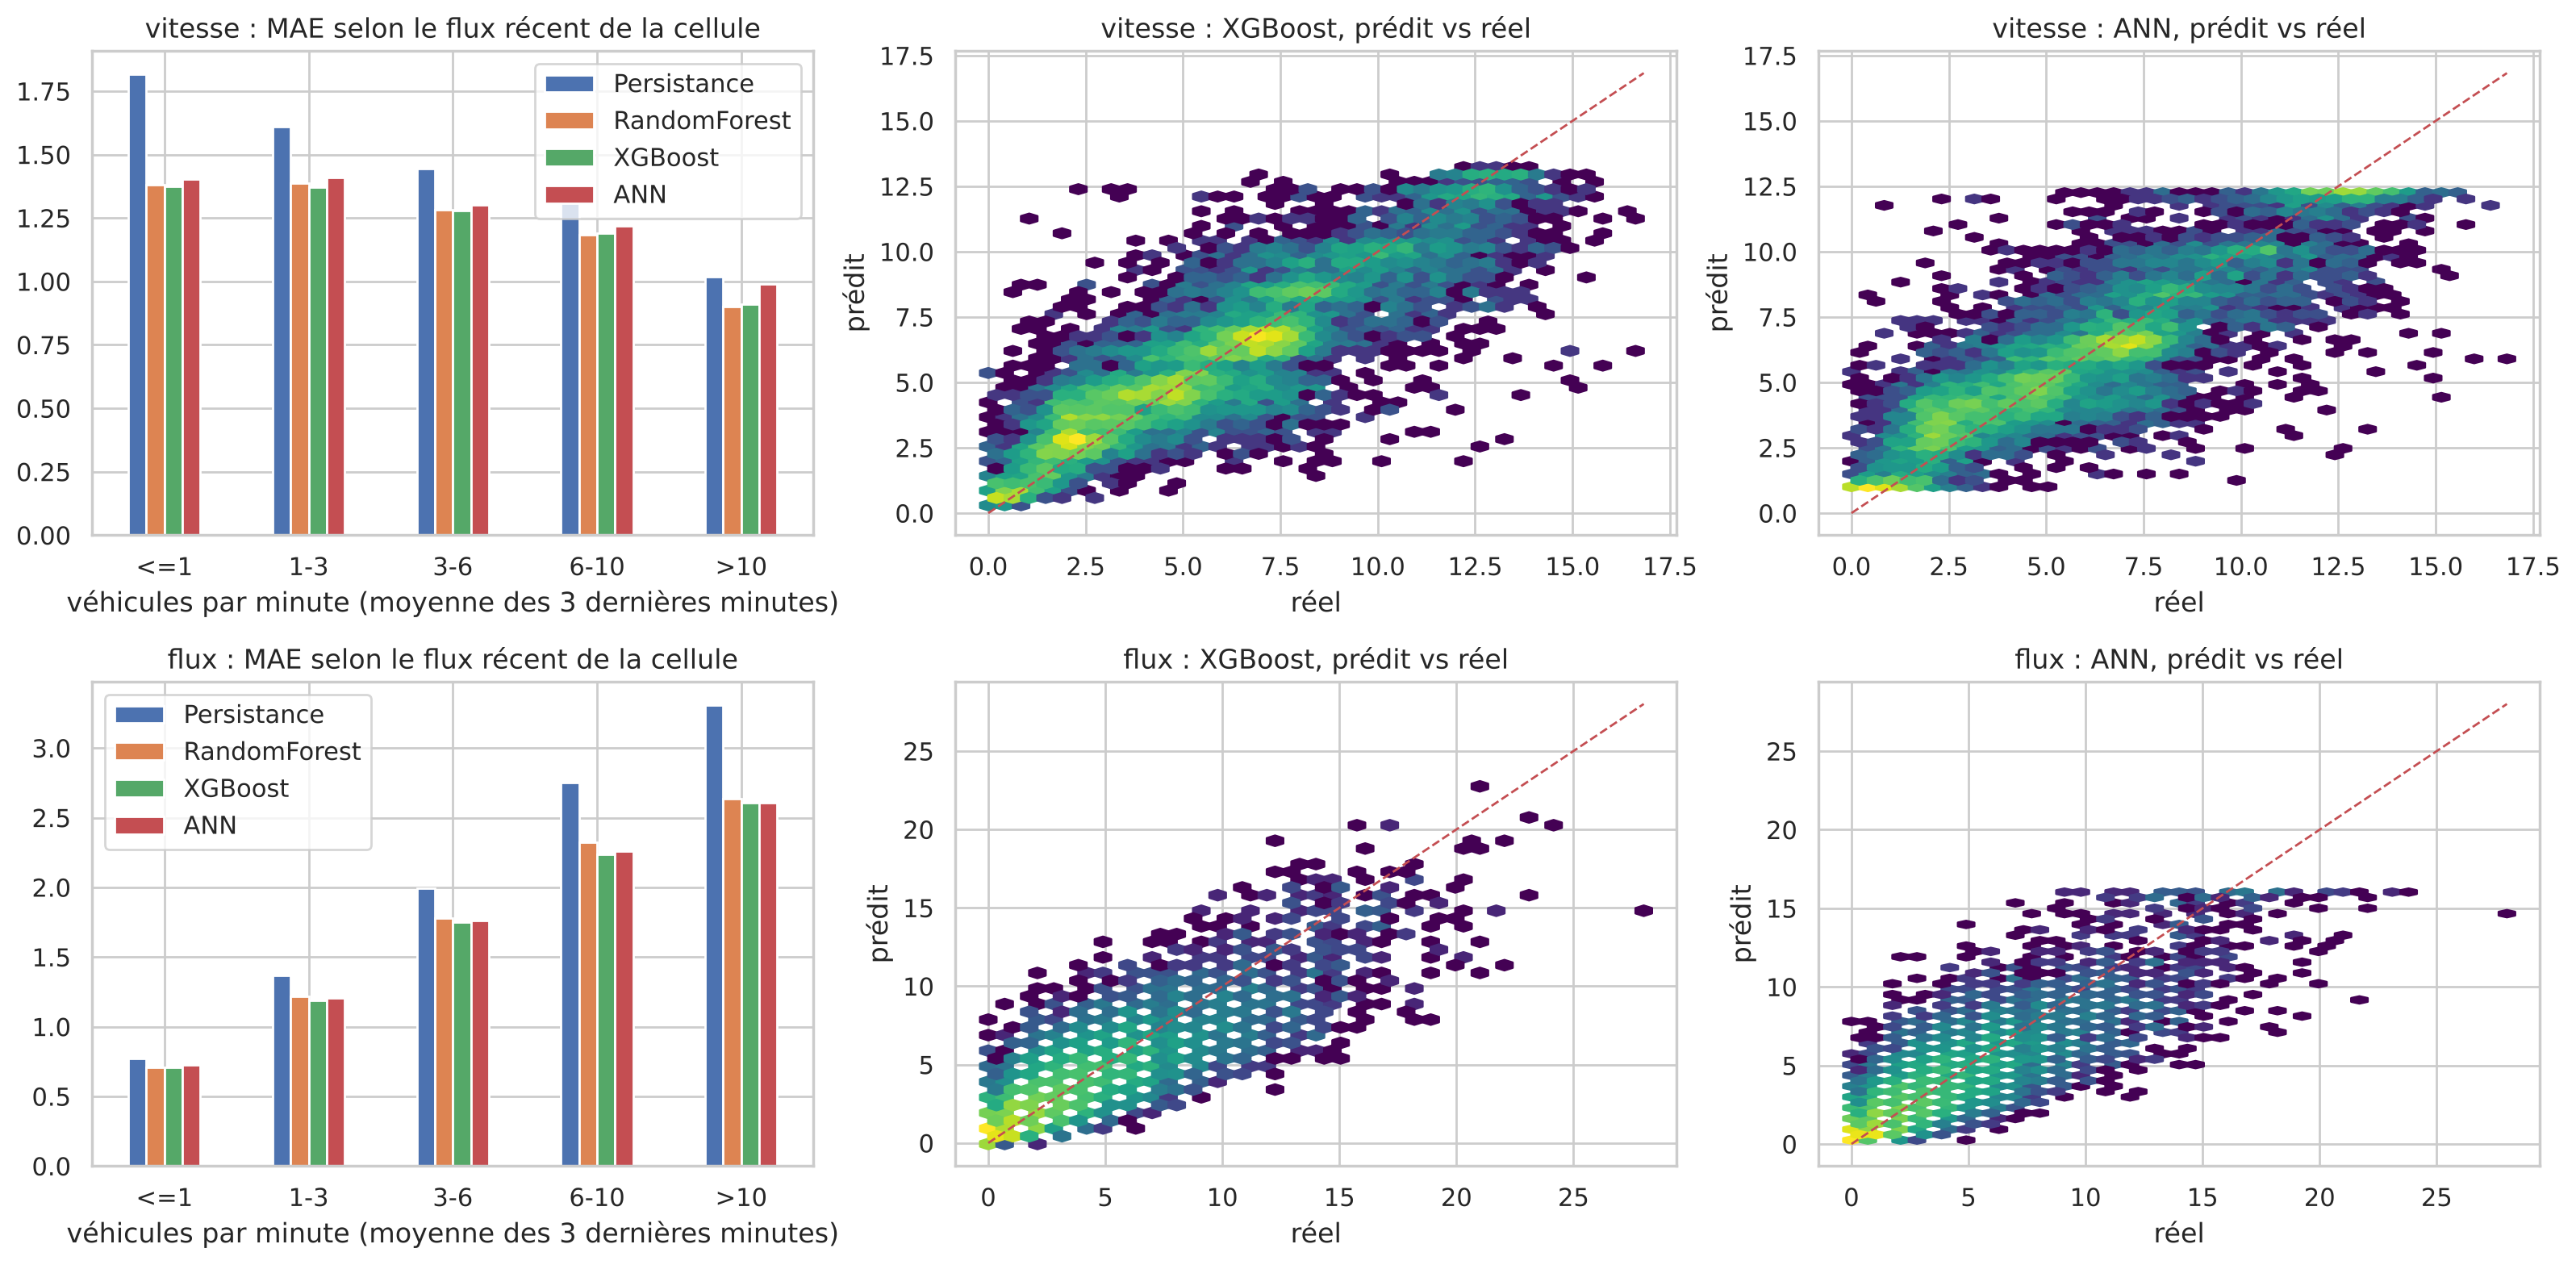

In [81]:
# Régression : erreur selon la charge de la cellule, et valeurs prédites vs réelles
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for j, t in enumerate(["vitesse", "flux"]):
    d = TEST.loc[IDX[t]]; y = PRED[t]["y_true"]
    charge = pd.cut(d.n_veh_roll3, [-0.1, 1, 3, 6, 10, 100], labels=["<=1", "1-3", "3-6", "6-10", ">10"])
    err = pd.DataFrame({m: np.abs(y - PRED[t][m]) for m in ["Persistance", "RandomForest", "XGBoost", "ANN"]})
    err.groupby(charge.values, observed=True).mean().plot.bar(ax=ax[j, 0]); ax[j, 0].set_title(f"{t} : MAE selon le flux récent de la cellule")
    ax[j, 0].set_xlabel("véhicules par minute (moyenne des 3 dernières minutes)"); ax[j, 0].tick_params(axis="x", rotation=0)
    for k, m in enumerate(["XGBoost", "ANN"]):
        ax[j, 1 + k].hexbin(y, PRED[t][m], gridsize=40, bins="log", cmap="viridis", mincnt=1)
        lim = [0, max(y.max(), PRED[t][m].max())]; ax[j, 1 + k].plot(lim, lim, "r--", lw=1)
        ax[j, 1 + k].set_title(f"{t} : {m}, prédit vs réel"); ax[j, 1 + k].set_xlabel("réel"); ax[j, 1 + k].set_ylabel("prédit")
plt.tight_layout(); plt.show()

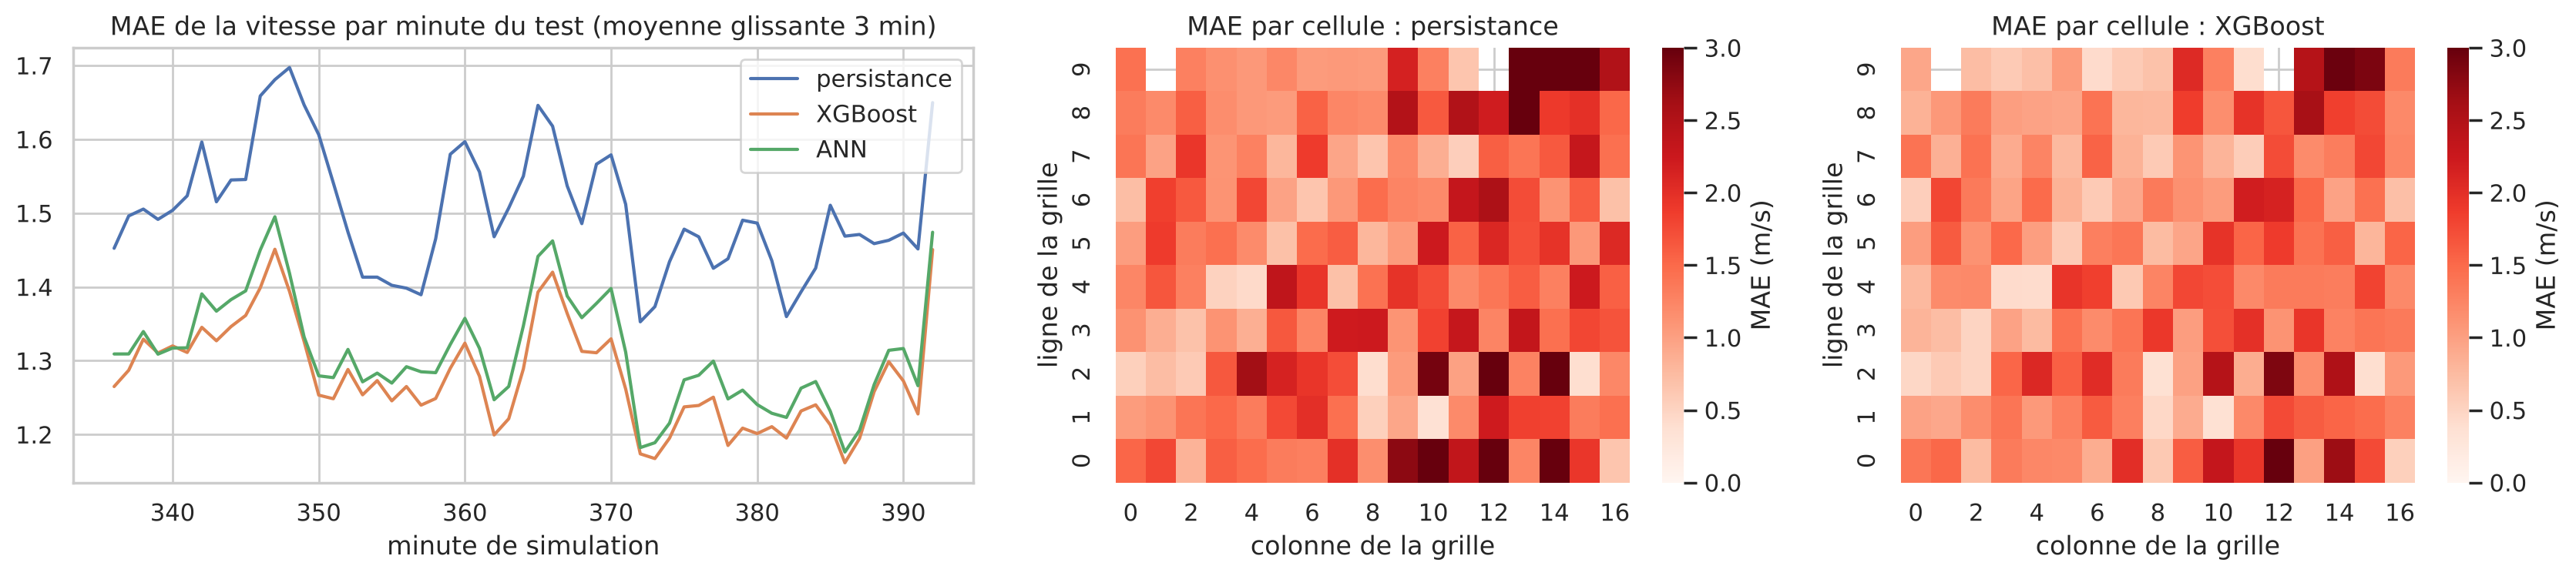

MAE vitesse : persistance 1.504 | XGBoost 1.280 | ANN 1.312
Cellules les plus difficiles pour XGBoost (>= 20 observations) :
         mean  size
cell_id            
12       3.73    33
167      2.98    28
46       2.86    58


In [82]:
# Dans le temps (par minute) et dans l'espace (par cellule), pour la vitesse
t = "vitesse"; d = TEST.loc[IDX[t]].copy(); y = PRED[t]["y_true"]
d["err_ref"] = np.abs(y - PRED[t]["Persistance"]); d["err_xgb"] = np.abs(y - PRED[t]["XGBoost"]); d["err_ann"] = np.abs(y - PRED[t]["ANN"])
NX, NY = META["grille"]

fig, ax = plt.subplots(1, 3, figsize=(17, 3.9), gridspec_kw={"width_ratios": [1.4, 1, 1]})
d.groupby("w_cible")[["err_ref", "err_xgb", "err_ann"]].mean().rolling(3, center=True).mean().plot(ax=ax[0])
ax[0].set_title("MAE de la vitesse par minute du test (moyenne glissante 3 min)"); ax[0].set_xlabel("minute de simulation"); ax[0].legend(["persistance", "XGBoost", "ANN"])
for a, col, titre in zip(ax[1:], ["err_ref", "err_xgb"], ["persistance", "XGBoost"]):
    carte = d.groupby("cell_id")[col].mean().reindex(range(NX * NY)).values.reshape(NY, NX)
    sns.heatmap(carte, ax=a, cmap="Reds", vmin=0, vmax=3, cbar=True, cbar_kws={"label": "MAE (m/s)"}); a.invert_yaxis()
    a.set_title(f"MAE par cellule : {titre}"); a.set_xlabel("colonne de la grille"); a.set_ylabel("ligne de la grille")
plt.tight_layout(); plt.show()
print(f"MAE vitesse : persistance {d.err_ref.mean():.3f} | XGBoost {d.err_xgb.mean():.3f} | ANN {d.err_ann.mean():.3f}")
pire = d.groupby("cell_id")["err_xgb"].agg(["mean", "size"]).query("size >= 20").sort_values("mean", ascending=False).head(3)
print("Cellules les plus difficiles pour XGBoost (>= 20 observations) :"); print(pire.round(2).to_string())

## 5. Coût de calcul et variabilité

Un modèle un peu meilleur mais bien plus coûteux ou instable n'est pas toujours le bon choix. On regarde le temps d'entraînement (une exécution sur la machine utilisée) et, pour le réseau de neurones, l'écart-type entre graines aléatoires.

In [83]:
rows = []
for t in TASKS:
    for m in ["RandomForest", "XGBoost", "AdaBoost"]:
        rows.append({"tâche": t, "modèle": m, "temps d'entraînement (s)": MET_ENS[t][m]["temps_s"]})
    rows.append({"tâche": t, "modèle": "ANN", "temps d'entraînement (s)": MET_ANN[t]["ANN"]["temps_s"]})
cout = pd.DataFrame(rows).pivot(index="modèle", columns="tâche", values="temps d'entraînement (s)")
print("Temps d'entraînement du modèle final (secondes) :"); print(cout.round(1).to_string())

print("\nRéseau de neurones : 3 graines aléatoires, test")
for t in TASKS:
    v = MET_ANN[t]["ANN"]["test_3_graines"][crit[t]]
    print(f"  {t:8s} {crit[t]:9s}: {np.round(v, 3)}  moyenne = {np.mean(v):.3f}, écart-type = {np.std(v):.3f}")

Temps d'entraînement du modèle final (secondes) :
tâche         etat  flux  vitesse
modèle                           
ANN           43.8  74.4     26.6
AdaBoost      73.1  72.4     25.1
RandomForest   6.9   6.4      6.1
XGBoost        3.9   7.1      3.2

Réseau de neurones : 3 graines aléatoires, test
  etat     F1_macro : [0.731 0.73  0.72 ]  moyenne = 0.727, écart-type = 0.005
  vitesse  MAE      : [1.312 1.291 1.303]  moyenne = 1.302, écart-type = 0.009
  flux     MAE      : [1.46  1.457 1.463]  moyenne = 1.460, écart-type = 0.002


## 6. Agent de Reinforcement Learning (bonus)

L'agent ne prédit pas : il **décide**. Son évaluation est donc différente : on mesure le **retard moyen par véhicule** dans un simulateur de carrefour alimenté par les flux réels du test (voir partie 4), et on le compare à des politiques de régulation de référence.

In [84]:
reel = pd.DataFrame(MET_RL["reel_test"]).T[["retard_s_par_veh", "ic95", "file_moyenne", "file_max", "debit_veh_h", "changements_h"]]
print("Scénarios réels (test) : 15 créneaux de 15 min x 6 graines")
print(reel.round(2).to_string())
ref = reel.loc[[i for i in reel.index if i.startswith("Temps fixe")][0], "retard_s_par_veh"]
for nom in reel.index:
    print(f"  {nom:32s}: {100 * (reel.loc[nom, 'retard_s_par_veh'] / ref - 1):+6.1f} % de retard par rapport au temps fixe")
print("\nAgents Q-learning (5 graines) sur le test, retard moyen :", np.round(MET_RL["parametres"]["agents_q_test"], 2))

syn = pd.DataFrame(MET_RL["synthetique"]).T
print("\nScénarios synthétiques (retard moyen, s/véh) :"); print(syn.round(1).to_string())

Scénarios réels (test) : 15 créneaux de 15 min x 6 graines
                             retard_s_par_veh  ic95  file_moyenne  file_max  debit_veh_h  changements_h
Aléatoire                               68.94  6.54         19.23     44.72       850.98          44.00
Temps fixe (30 s, optimisé)             30.07  2.68          8.41     23.57       898.80         120.00
Plus longue file (marge 6)              11.89  1.78          3.71     14.09       926.36         149.64
Q-learning                              11.55  1.62          3.57     13.80       927.33         149.64
  Aléatoire                       : +129.3 % de retard par rapport au temps fixe
  Temps fixe (30 s, optimisé)     :   +0.0 % de retard par rapport au temps fixe
  Plus longue file (marge 6)      :  -60.5 % de retard par rapport au temps fixe
  Q-learning                      :  -61.6 % de retard par rapport au temps fixe

Agents Q-learning (5 graines) sur le test, retard moyen : [11.97 11.55 11.46 11.87 11.64]

Scéna

## 7. Démonstration : prévoir l'état du trafic de la minute suivante sur toute la ville

Pour une minute `t` du test, on prend les variables disponibles à la fin de la minute `t`, on prédit l'état de chaque cellule à `t+1` avec **XGBoost**, et on le compare à la réalité.

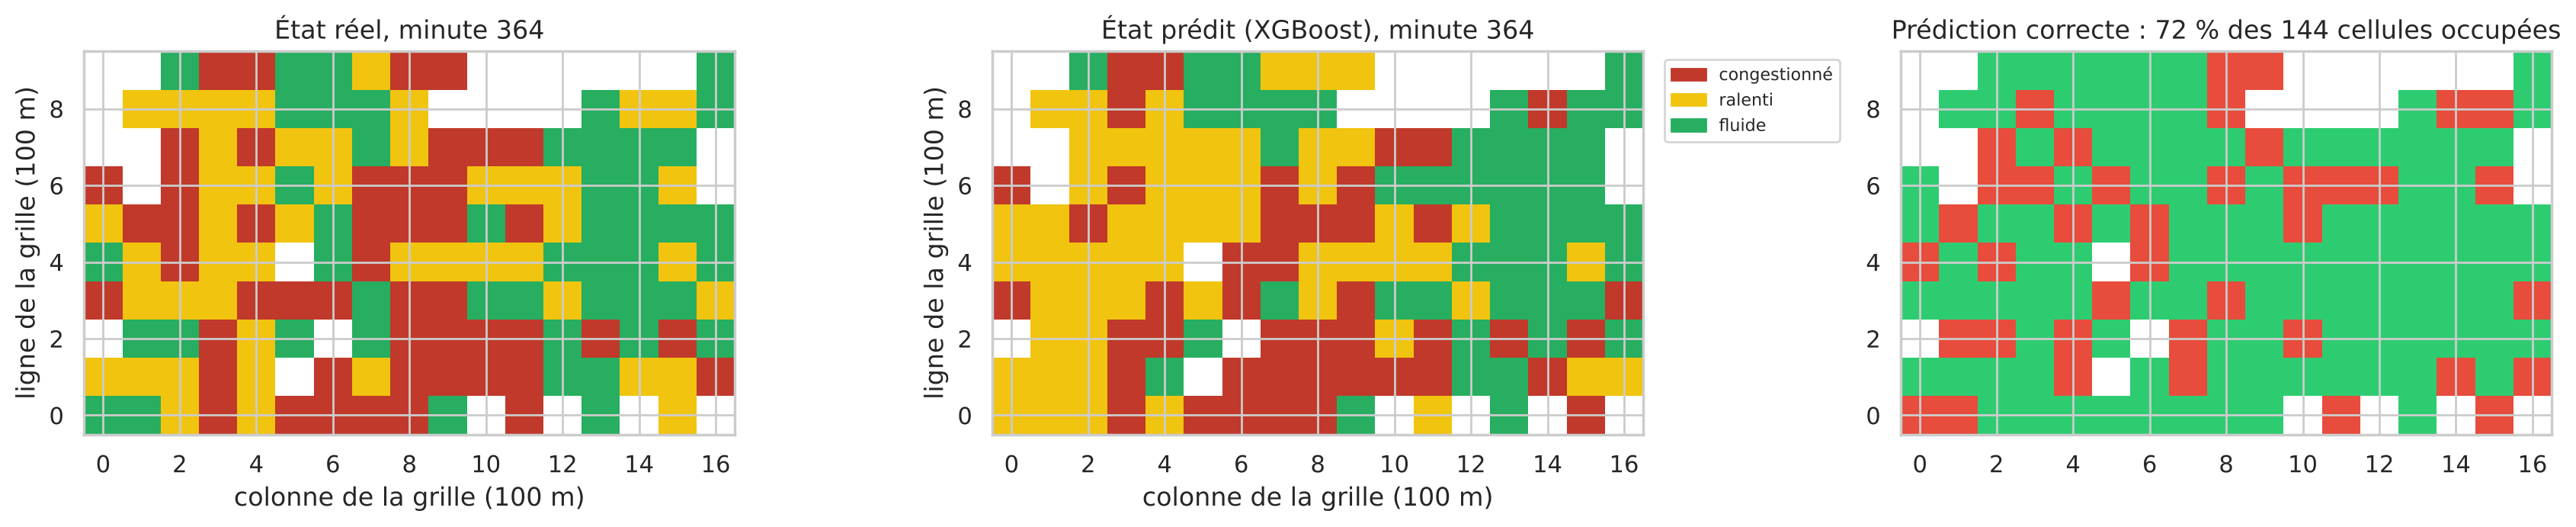

In [85]:
t = "etat"; d = TEST.loc[IDX[t]].copy()
d["reel"] = PRED[t]["y_true"]; d["pred"] = PRED[t]["XGBoost"]
NX, NY = META["grille"]

def demo(minute_cible):
    """Carte de l'état réel et de l'état prédit pour la minute `minute_cible` (prédiction faite à la minute précédente)."""
    s = d[d.w_cible == minute_cible]
    fig, ax = plt.subplots(1, 3, figsize=(17, 3.9))
    cmap = plt.matplotlib.colors.ListedColormap(["#c0392b", "#f1c40f", "#27ae60"])
    for a, col, titre in zip(ax[:2], ["reel", "pred"], ["État réel", "État prédit (XGBoost)"]):
        carte = s.set_index("cell_id")[col].reindex(range(NX * NY)).values.reshape(NY, NX)
        im = a.imshow(carte, origin="lower", cmap=cmap, vmin=0, vmax=2, interpolation="nearest"); a.set_title(f"{titre}, minute {minute_cible}")
        a.set_xlabel("colonne de la grille (100 m)"); a.set_ylabel("ligne de la grille (100 m)")
    ok = (s.reel == s.pred); carte = ok.groupby(s.cell_id).first().reindex(range(NX * NY)).astype(float).values.reshape(NY, NX)
    ax[2].imshow(carte, origin="lower", cmap=plt.matplotlib.colors.ListedColormap(["#e74c3c", "#2ecc71"]), vmin=0, vmax=1, interpolation="nearest")
    ax[2].set_title(f"Prédiction correcte : {100 * ok.mean():.0f} % des {len(s)} cellules occupées")
    from matplotlib.patches import Patch
    ax[1].legend(handles=[Patch(color=c, label=l) for c, l in zip(["#c0392b", "#f1c40f", "#27ae60"], ETATS)], loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
    plt.tight_layout(); plt.show()

milieu = int(d.w_cible.median())
demo(milieu)

## 8. Limites, pistes d'amélioration et conclusion

### Ce que l'on retient
**1. Les modèles apprenants battent les références simples, mais de façon modeste.**
Sur le test, par rapport à la persistance (prédire que rien ne change), l'erreur absolue moyenne baisse d'environ **15 %** pour la vitesse (1,504 → 1,280 m/s avec XGBoost) et pour le flux (1,689 → 1,445 véhicules) ; le taux d'erreur de classement de l'état passe de 31,5 % à 27,0 %. Contre la référence « profil de la cellule » (moyenne historique de la cellule), l'avantage est plus faible : −5,7 % sur la vitesse, −10,7 % sur le flux, et +0,017 de F1 macro sur l'état. Une bonne partie de l'information est donc déjà dans l'historique de chaque cellule (la variable `cell_speed_mean` domine le classement des variables de la partie 1) ; les modèles ajoutent surtout la dynamique récente (retards, voisinage).

**2. Les trois familles de modèles sont très proches.**
- **État** : ANN, XGBoost et Random Forest sont à 0,73 de F1 macro ; l'intervalle de confiance de la différence contient 0 (pas de différence nette).
- **Vitesse** : XGBoost (1,280) ≈ Random Forest (1,285) ; le réseau est légèrement moins bon (1,312), et cet écart de 0,03 m/s est statistiquement net mais petit.
- **Flux** : XGBoost est le meilleur (1,445), devant le réseau (1,460) et Random Forest (1,474) ; les différences sont petites mais nettes.
- **AdaBoost** est clairement plus faible, surtout sur la vitesse et le flux (MAE 1,473 et 1,678, c'est-à-dire proche de la persistance) : ses arbres peu profonds sont mal adaptés à des cibles continues bruitées.
- Le seul modèle qui sort un peu du lot est **XGBoost**, et c'est aussi le **plus économique** (3 à 7 s d'entraînement contre 31 à 78 s pour le réseau et 25 à 71 s pour AdaBoost). Si l'on devait en retenir un pour un usage réel, ce serait XGBoost.

**3. Où les modèles se trompent.**
- La classe intermédiaire **« ralenti »** est la plus difficile (rappel de 0,62 à 0,64) ; les confusions extrêmes (congestionné ↔ fluide) ne représentent que 2,5 % des échantillons. Comme les classes sont définies par des seuils sur une vitesse continue, une erreur de classement est souvent une erreur de quelques dixièmes de m/s de part et d'autre d'un seuil.
- Les erreurs ne sont pas uniformes dans l'espace : elles se concentrent sur quelques cellules (par exemple 12, 167 et 46, avec une MAE moyenne de 2,9 à 3,7 m/s) et sur certains bords de la grille. Elles évoluent aussi dans le temps de façon quasi identique pour tous les modèles, ce qui montre qu'une partie de l'erreur vient de variations du trafic qu'aucun de ces modèles ne voit venir.
- Sur la carte de démonstration (minute 364), 72 % des cellules occupées sont prédites correctement, ce qui est cohérent avec l'exactitude globale d'environ 73 %.

**4. Le bonus RL.**
L'agent Q-learning ramène le retard moyen de 30,1 s (temps fixe optimisé) à 11,5 s (−62 %), et fait légèrement mieux que l'heuristique « plus longue file » (11,9 s ; différence appariée de −0,34 s, intervalle de confiance excluant 0). L'avantage est surtout net en forte charge (−16 %). Ces retards sont des valeurs de simulation, utiles pour comparer des politiques entre elles, pas des mesures du réseau réel.

### Limites
- **Un seul jeu de données et un seul découpage temporel** (70 % / 15 % / 15 %, avec 394 fenêtres d'une minute au total). Les intervalles de confiance sont calculés par bootstrap par blocs de minutes et mesurent l'incertitude d'échantillonnage sur cette période de test, pas la variabilité entre journées de trafic différentes.
- **Horizon d'une minute** : on prédit la fenêtre suivante. Un horizon plus long serait plus utile pour agir sur le trafic, mais plus difficile.
- **Cibles dérivées** : l'état est un découpage par seuils (quantiles du jeu d'entraînement) de la vitesse ; un autre découpage donnerait d'autres scores.
- **Cellules peu observées** : en dessous de quelques véhicules par fenêtre, la vitesse moyenne est bruitée, ce qui borne la précision atteignable.
- **Réglage limité par le temps de calcul** : 6 essais pour le réseau, 25 pour XGBoost, 4 pour AdaBoost. Des écarts de moins de 2 % ne doivent pas être sur-interprétés.
- **RL** : environnement simplifié (carrefour à 2 phases, hypothèses de saturation et de temps perdu choisies par nous), apprentissage tabulaire à états discrétisés.

### Pistes d'amélioration
- Élargir le voisinage spatial (au-delà des cellules adjacentes déjà utilisées) ou utiliser un modèle qui exploite la grille : réseau convolutif, ConvLSTM ou réseau de graphes sur le réseau routier.
- Ajouter des variables de contexte (heure, jour, événements) si le jeu de données le permet, et valider sur plusieurs périodes (validation croisée temporelle).
- Prédire plusieurs horizons (1, 5, 15 minutes) et fournir un intervalle de prédiction (régression quantile) plutôt qu'une seule valeur.
- Pour le RL : calibrer l'environnement sur le simulateur d'origine, passer à un **DQN** pour éviter la discrétisation, et étendre le contrôle à plusieurs carrefours voisins en reliant le prédicteur de flux à l'agent.

### Conclusion
Le pipeline complet (préparation sans fuite de données, ensembles, réseau de neurones, apprentissage par renforcement) donne des résultats cohérents entre eux : l'information utile est concentrée dans l'historique local de la circulation, les modèles les plus simples à régler (XGBoost, Random Forest) suffisent, et le réseau de neurones ne les dépasse pas sur ces données tabulaires. L'intérêt pratique est surtout de **combiner** la prévision (où le trafic va se dégrader) avec la **décision** (comment adapter les feux), ce que l'agent de RL illustre sur un carrefour simulé.